# Resolution refinement and the rodeo algorithm on the Hubbard model — lattice refinement, symmetry protection and gate budgets

This notebook is the computational companion of paper III of the EIGEN-Q series.  Papers I and II
implemented the pipeline *coarse eigenstate → prolongation → adiabatic resolution refinement →
rodeo filter* on the pairing Hamiltonian, where "resolution" was the number of single-particle
levels.  Here we carry the same pipeline, the same exact-diagonalisation (ED) benchmarks and the
same cost accounting to the Hubbard model

$$H=-t\sum_{\langle ij\rangle\sigma}\big(c^\dagger_{i\sigma}c_{j\sigma}+\mathrm{h.c.}\big)+U\sum_i n_{i\uparrow}n_{i\downarrow},$$

and to the form of refinement for which the method was proposed: a **lattice** refinement in which
every coarse site is resolved into a block of fine sites and the prolongation maps the coarse
orbital onto the bonding combination of its block.

All physics lives in `pairinglib.hubbard` (tested, `tests/test_hubbard.py`); the ED conventions
are those of `paper3/Hubbard.ipynb` (block Jordan–Wigner ordering, sorted occupation masks,
$H=K_\uparrow\otimes1+1\otimes K_\downarrow+U\,\mathrm{diag}$).  We work at $t=1$ with open
boundary conditions.  The sections follow the paper: model and ED reference (1), prolongation and
the Galerkin coarse model (2), the open chain $4\to8$ along two refinement paths (3), which gap
controls the refinement (4), the dimer bootstrap and composed chains (5), $8\to16$ sites (6), two
dimensions and the wrong symmetry sector (7), the rodeo filter (8), the UCCSD comparator (9),
circuit-level costs (10) and a summary (11).

---
## 1&nbsp; The model and its exact-diagonalisation reference

The Hamiltonian conserves $N_\uparrow$ and $N_\downarrow$; we work in one sector of dimension
$\binom{N}{N_\uparrow}\binom{N}{N_\downarrow}$.  With the up orbitals Jordan–Wigner ordered before
the down orbitals, a down hop crosses all up electrons twice and the sector Hamiltonian is the
Kronecker sum of two one-species hopping matrices plus the diagonal interaction.  We validate the
builder against free fermions ($U=0$), the analytic dimer $E_0=\tfrac12(U-\sqrt{U^2+16t^2})$, and
the term decomposition used later for product formulas.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# --- validation of the sector ED against closed forms ---
N, bonds = hb.chain(2)
for U in (0.0, 4.0, 8.0):
    E0 = np.linalg.eigvalsh(hb.H_hubbard(N, bonds, 1, 1, U)[0].toarray())[0]
    Ean = 0.5*(U - np.sqrt(U**2 + 16))
    assert abs(E0 - Ean) < 1e-12
    print(f"dimer U={U:3.0f}: E0 = {E0:+.10f} == (U - sqrt(U^2+16t^2))/2")
for kind, L, (nu, nd) in (("chain", 8, (2, 2)), ("square", 3, (2, 1))):
    N, bonds = hb.chain(L) if kind == "chain" else hb.square(L)
    T1 = np.zeros((N, N))
    for i, j in bonds: T1[i, j] = T1[j, i] = -1.0
    e1 = np.linalg.eigvalsh(T1)
    H, _ = hb.H_hubbard(N, bonds, nu, nd, 0.0)
    E0 = hb.ground(H, 1)[0][0]
    assert abs(E0 - (e1[:nu].sum() + e1[:nd].sum())) < 1e-9
    print(f"{kind:6s} L={L} U=0 ({nu},{nd}): E0 = {E0:+.10f} == band filling")
N, bonds = hb.chain(6)
H, _ = hb.H_hubbard(N, bonds, 3, 3, 4.0)
terms = hb.hubbard_terms(N, bonds, 3, 3, 4.0)
assert abs(sum(T.toarray() for T in terms) - H.toarray()).max() < 1e-12
print(f"term decomposition [K_even, K_odd, U diag] sums to H (L=6, half filling, dim {H.shape[0]})")
print("\nsector dimensions used below:")
for lab, N, nu, nd in (("chain L=2", 2, 2, 2), ("chain L=4", 4, 2, 2), ("chain L=8", 8, 2, 2), ("chain L=16", 16, 2, 2),
                       ("2x2", 4, 1, 1), ("4x4", 16, 1, 1), ("2x2", 4, 2, 2), ("4x4", 16, 2, 2)):
    print(f"  {lab:11s} ({nu},{nd}): {comb(N, nu)*comb(N, nd):6d}")


dimer U=  0: E0 = -2.0000000000 == (U - sqrt(U^2+16t^2))/2
dimer U=  4: E0 = -0.8284271247 == (U - sqrt(U^2+16t^2))/2
dimer U=  8: E0 = -0.4721359550 == (U - sqrt(U^2+16t^2))/2
chain  L=8 U=0 (2,2): E0 = -6.8229482556 == band filling
square L=3 U=0 (2,1): E0 = -7.0710678119 == band filling
term decomposition [K_even, K_odd, U diag] sums to H (L=6, half filling, dim 400)

sector dimensions used below:
  chain L=2   (2,2):      1
  chain L=4   (2,2):     36
  chain L=8   (2,2):    784
  chain L=16  (2,2):  14400
  2x2         (1,1):     16
  4x4         (1,1):    256
  2x2         (2,2):     36
  4x4         (2,2):  14400


---
## 2&nbsp; Prolongation and the Galerkin coarse Hamiltonian

A refinement step maps $N_c$ coarse sites onto $N_f=bN_c$ fine sites ($b=2$ for the chain, $b=4$
for the square lattice).  The prolongation sends the coarse orbital to the normalized bonding
combination of its block,
$c^\dagger_{c\sigma}\mapsto s^\dagger_{c\sigma}=b^{-1/2}\sum_{f\in B(c)}c^\dagger_{f\sigma}$,
and a coarse determinant to the product of $s^\dagger$ operators; $P$ is an isometry from the coarse
sector into the fine sector.  On a device it is one Givens rotation per block per spin ($b=2$).

The coarse Hamiltonian whose eigenstate is refined is the Galerkin projection
$H_{\rm low}=P^\dagger H_{\rm high}P$, which makes $\langle P\psi_{\rm low}|H_{\rm high}|P\psi_{\rm low}\rangle=E_{\rm low}$
exact.  Projecting the hopping and interaction terms with the bonding map gives a closed form:
an intra-block bond contributes $-t$ per particle, an inter-block bond $\tfrac12 s^\dagger_cs_{c'}$,
and $U\,n_{f\uparrow}n_{f\downarrow}\to(U/b)\,n_{s\uparrow}n_{s\downarrow}$ summed over the block, so

$$\text{chain: } H_{\rm low}=H_{\rm Hubbard}(L;\,t/2,\,U/2)-tN,\qquad
\text{square: } H_{\rm low}=H_{\rm Hubbard}(L\times L;\,t/2,\,U/4)-2tN .$$

In one dimension $U/t$ is preserved: the hierarchy $L\to2L\to4L\to\cdots$ is self-similar.  We
verify both identities to machine precision and tabulate the prolonged overlap $p_0$.

In [2]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

for kind, L, nu, nd in (("chain", 4, 2, 2), ("chain", 2, 2, 2), ("square", 2, 1, 1)):
    if kind == "chain": (Nc, bc), (Nf, bf), blocks, intra = hb.refine_chain(L)
    else:               (Nc, bc), (Nf, bf), blocks, intra = hb.refine_square(L)
    for U in (0.0, 4.0):
        Hf, _ = hb.H_hubbard(Nf, bf, nu, nd, U)
        P = hb.prolong(Nc, Nf, blocks, nu, nd)
        Hl = P.T @ Hf.toarray() @ P
        tl, Ul, c = hb.galerkin_params(kind, 1.0, U, nu + nd)
        Hc = hb.H_hubbard(Nc, bc, nu, nd, Ul, t=tl)[0].toarray() + c*np.eye(len(Hl))
        err = abs(Hl - Hc).max(); iso = abs(P.T @ P - np.eye(P.shape[1])).max()
        print(f"{kind:6s} {Nc:2d}->{Nf:2d} ({nu},{nd}) U={U:.0f}: |P^T H P - H_Hubbard(t'={tl}, U'={Ul}) - ({c})| = {err:.1e}, |P^T P - 1| = {iso:.1e}")
print("\nprolonged overlap p0 = |<Psi_high|P psi_low>|^2 of the coarse ground state:")
for kind, L, nu, nd in (("chain", 2, 2, 2), ("chain", 4, 2, 2), ("chain", 8, 2, 2), ("square", 2, 1, 1)):
    if kind == "chain": (Nc, bc), (Nf, bf), blocks, intra = hb.refine_chain(L)
    else:               (Nc, bc), (Nf, bf), blocks, intra = hb.refine_square(L)
    row = []
    for U in (0.0, 2.0, 4.0, 8.0):
        Hf, _ = hb.H_hubbard(Nf, bf, nu, nd, U)
        w, V = hb.ground(Hf, 2)
        P = hb.prolong(Nc, Nf, blocks, nu, nd, sparse=True)
        ps = hb.prolonged_state(Hf, P)
        row.append(abs(np.vdot(V[:, 0], ps["Phi0"]))**2)
    print(f"  {kind:6s} {Nc:2d}->{Nf:2d} ({nu},{nd}):  " + "  ".join(f"U={U:.0f}: {p:.4f}" for U, p in zip((0, 2, 4, 8), row)))


chain   4-> 8 (2,2) U=0: |P^T H P - H_Hubbard(t'=0.5, U'=0.0) - (-4.0)| = 3.6e-15, |P^T P - 1| = 8.9e-16
chain   4-> 8 (2,2) U=4: |P^T H P - H_Hubbard(t'=0.5, U'=2.0) - (-4.0)| = 3.6e-15, |P^T P - 1| = 8.9e-16
chain   2-> 4 (2,2) U=0: |P^T H P - H_Hubbard(t'=0.5, U'=0.0) - (-4.0)| = 3.6e-15, |P^T P - 1| = 8.9e-16
chain   2-> 4 (2,2) U=4: |P^T H P - H_Hubbard(t'=0.5, U'=2.0) - (-4.0)| = 8.3e-17, |P^T P - 1| = 8.9e-16
square  4->16 (1,1) U=0: |P^T H P - H_Hubbard(t'=0.5, U'=0.0) - (-4.0)| = 0.0e+00, |P^T P - 1| = 0.0e+00
square  4->16 (1,1) U=4: |P^T H P - H_Hubbard(t'=0.5, U'=1.0) - (-4.0)| = 0.0e+00, |P^T P - 1| = 0.0e+00

prolonged overlap p0 = |<Psi_high|P psi_low>|^2 of the coarse ground state:
  chain   2-> 4 (2,2):  U=0: 0.8050  U=2: 0.7541  U=4: 0.6449  U=8: 0.4804
  chain   4-> 8 (2,2):  U=0: 0.7773  U=2: 0.8139  U=4: 0.7974  U=8: 0.7501
  chain   8->16 (2,2):  U=0: 0.9119  U=2: 0.8929  U=4: 0.8692  U=8: 0.8400
  square  4->16 (1,1):  U=0: 0.8050  U=2: 0.8289  U=4: 0.8396  U=8: 

---
## 3&nbsp; The open chain refined from four to eight sites along two paths

**Path A** is the shift-controlled projector path of papers I and II,
$H_A(s)=\cos^2(\tfrac{\pi s}2)P(H_{\rm low}-\mu)P^\dagger+\sin^2(\tfrac{\pi s}2)(H_{\rm high}-\mu)$,
with $\mu=E_{\rm low}+\mu_{\rm buf}$.  **Path B** keeps the Hamiltonian two-local in the laboratory
frame: it adds an extra hopping $\Lambda$ on the intra-block bonds and switches it off,
$H_B(s)=H_{\rm high}-\Lambda\cos^2(\tfrac{\pi s}2)\sum_{\rm intra}\sum_\sigma(c^\dagger_{f\sigma}c_{f'\sigma}+{\rm h.c.})$
— the dimerized chain being adiabatically made uniform.  At finite $\Lambda$ the ground state of
$H_B(0)$ differs from the prolonged state by an admixture of order $t/\Lambda$, so Path B carries a
residual $1-p\simeq c\,(t/\Lambda)^2$ to the end.

We propagate exactly with 96 slices (the slice propagators are reused for every $T$) and report
$p(T)=|\langle\Psi_{\rm high}|\psi(T)\rangle|^2$ for $N_\uparrow=N_\downarrow=2$, $U/t=0,2,4,8$.

chain 4->8, (2,2), dims 36 -> 784  [195 s]

 U/t      E_low     E_high     p0  Delta  D_eff |    A, mu_buf=1    A, mu_buf=2    B, Lambda=8   B, Lambda=16
                                                | p(8)  p(16) p(32) p(8)  p(16) p(32) p(8)  p(16) p(32) p(8)  p(16) p(32)
   0  -6.236068  -6.822948  0.777  0.532  0.879 | 0.98429 0.99892 0.99996 | 0.99718 0.99997 1.00000 | 0.98757 0.99546 0.99504 | 0.98040 0.99660 0.99838
   2  -5.437971  -6.032090  0.814  0.319  0.780 | 0.98737 0.99848 0.99993 | 0.99876 0.99996 1.00000 | 0.99177 0.99384 0.99497 | 0.98765 0.99594 0.99849
   4  -4.976573  -5.634427  0.797  0.223  0.588 | 0.98860 0.99814 0.99989 | 0.99837 0.99994 1.00000 | 0.98286 0.99239 0.99385 | 0.97923 0.99316 0.99769
   8  -4.558586  -5.277973  0.750  0.137  0.366 | 0.99013 0.99818 0.99985 | 0.99761 0.99991 1.00000 | 0.97528 0.98912 0.99440 | 0.97172 0.99205 0.99731

Path B: overlap of the prolonged state with the exact ground state of H_B(0), and the finite-Lambda ceiling 1-p(T=6

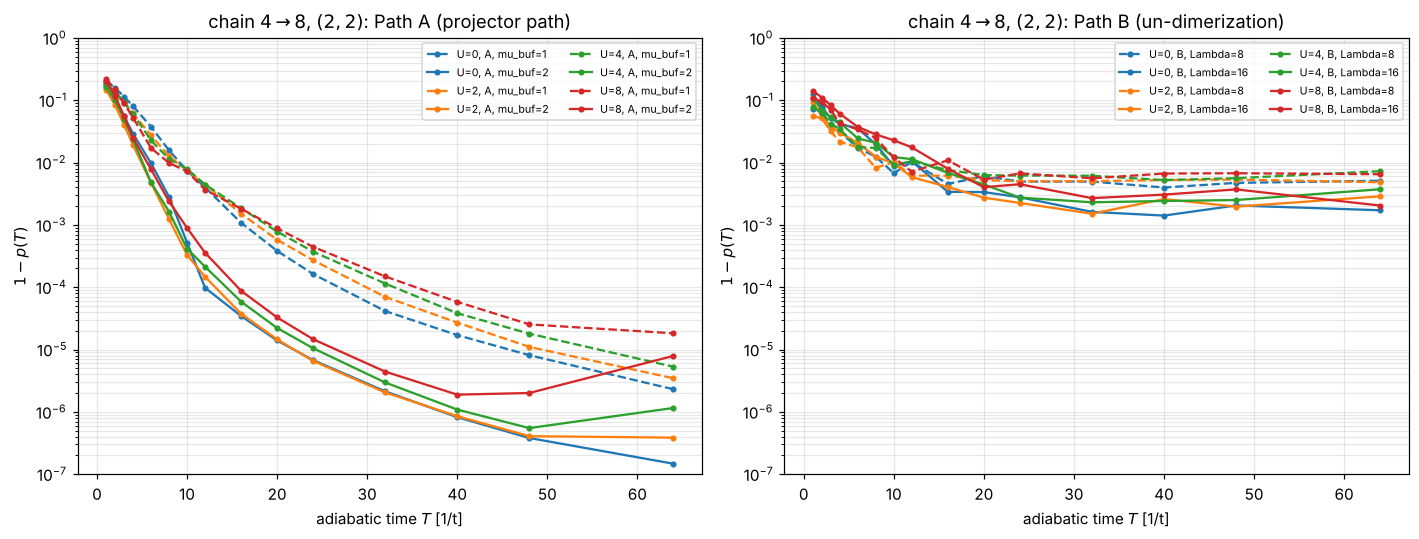

In [3]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

Ts = np.array([0, 1, 2, 3, 4, 6, 8, 10, 12, 16, 20, 24, 32, 40, 48, 64])
Us = (0.0, 2.0, 4.0, 8.0)
MU_BUFS, LAMS, MSL = (1.0, 2.0), (8.0, 16.0), 96
(Nc, bc), (Nf, bf), blocks, intra = hb.refine_chain(4)
chain48 = {}
t0 = time.time()
for U in Us:
    Hf, (Sup, Sdn) = hb.H_hubbard(Nf, bf, 2, 2, U); Hd = Hf.toarray()
    wf, Vf = np.linalg.eigh(Hd); Psih = Vf[:, 0]
    P = hb.prolong(Nc, Nf, blocks, 2, 2); ps = hb.prolonged_state(Hf, P)
    Deff, c2 = hb.effective_gap(ps["Phi0"], wf, Vf)
    r = dict(E_low=ps["El"], E_high=wf[0], p0=c2[0], gap=wf[1]-wf[0], Deff=Deff, wf=wf, Vf=Vf, Phi0=ps["Phi0"],
             Hf=Hd, Hl=ps["Hl"], P=P, c2=c2, paths={})
    for mb in MU_BUFS:
        Hle, Hhs = hb.path_A(Hd, ps["Hl"], P, ps["El"] + mb)
        ov, eigs = hb.refine_overlaps(ps["Phi0"], Hle, Hhs, Ts, Psih, MSL)
        s, W = hb.path_gap(Hle, Hhs, 21)
        r["paths"][f"A, mu_buf={mb:.0f}"] = dict(ov=ov, gap=W[:, 1]-W[:, 0], s=s, Hle=Hle, Hhs=Hhs,
                                               states={T: hb.evolve(ps["Phi0"], eigs, T) for T in (8, 16, 32)})
        del eigs                                    # 96 dense eigendecompositions: keep only the states
    Kin = hb.hubbard_terms(Nf, intra, 2, 2, 0.0, layers=[list(range(len(intra)))])[0].toarray()
    for Lam in LAMS:
        Hle, Hhs = hb.path_B(Hd, Kin, Lam)
        ov, eigs = hb.refine_overlaps(ps["Phi0"], Hle, Hhs, Ts, Psih, MSL)
        s, W = hb.path_gap(Hle, Hhs, 21)
        w0, V0 = np.linalg.eigh(Hle)
        r["paths"][f"B, Lambda={Lam:.0f}"] = dict(ov=ov, gap=W[:, 1]-W[:, 0], s=s, Hle=Hle, Hhs=Hhs,
                                                 start=abs(np.vdot(V0[:, 0], ps["Phi0"]))**2,
                                                 states={T: hb.evolve(ps["Phi0"], eigs, T) for T in (8, 16, 32)})
        del eigs
    chain48[U] = r
print(f"chain 4->8, (2,2), dims {chain48[0.0]['Hl'].shape[0]} -> {chain48[0.0]['Hf'].shape[0]}  [{time.time()-t0:.0f} s]\n")
print(f"{'U/t':>4s} {'E_low':>10s} {'E_high':>10s} {'p0':>6s} {'Delta':>6s} {'D_eff':>6s} | " + " ".join(f"{k:>14s}" for k in chain48[0.0]["paths"]))
print(f"{'':>4s} {'':>10s} {'':>10s} {'':>6s} {'':>6s} {'':>6s} | " + " ".join(f"{'p(8)  p(16) p(32)':>14s}" for k in chain48[0.0]["paths"]))
for U, r in chain48.items():
    cells_ = []
    for k, v in r["paths"].items():
        cells_.append(" ".join(f"{v['ov'][list(Ts).index(T)]:.5f}" for T in (8, 16, 32)))
    print(f"{U:4.0f} {r['E_low']:10.6f} {r['E_high']:10.6f} {r['p0']:6.3f} {r['gap']:6.3f} {r['Deff']:6.3f} | " + " | ".join(cells_))
print("\nPath B: overlap of the prolonged state with the exact ground state of H_B(0), and the finite-Lambda ceiling 1-p(T=64):")
for U, r in chain48.items():
    print(f"  U={U:.0f}: " + "   ".join(f"{k}: start {v['start']:.5f}, 1-p(64) = {1-v['ov'][-1]:.1e}" for k, v in r["paths"].items() if k.startswith("B")))
print("\nminimum of the sector gap along the path (and where it sits):")
for U, r in chain48.items():
    print(f"  U={U:.0f}: " + "  ".join(f"{k}: {v['gap'].min():.3f} @ s={v['s'][v['gap'].argmin()]:.2f}" for k, v in r["paths"].items()))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cols = {0.0: "C0", 2.0: "C1", 4.0: "C2", 8.0: "C3"}
for U, r in chain48.items():
    for k, v in r["paths"].items():
        a = ax[0] if k.startswith("A") else ax[1]
        ls = "-" if ("mu_buf=2" in k or "Lambda=16" in k) else "--"
        a.semilogy(Ts[1:], np.maximum(1 - v["ov"][1:], 1e-12), ls, color=cols[U], marker="o", ms=3,
                   label=f"U={U:.0f}, {k}")
for a, ttl in zip(ax, ("Path A (projector path)", "Path B (un-dimerization)")):
    a.set_xlabel("adiabatic time $T$ [1/t]"); a.set_ylabel("$1-p(T)$"); a.set_title(f"chain $4\\to8$, $(2,2)$: {ttl}")
    a.grid(alpha=0.3, which="both"); a.legend(fontsize=7, ncol=2); a.set_ylim(1e-7, 1)
plt.tight_layout(); plt.show()


The prolonged state is a good start at every coupling ($p_0=0.75$–$0.81$), the free-fermion
case is not trivial because the bonding modes are not the lowest fine orbitals, and Path A with
$\mu_{\rm buf}=2t$ reaches $p>0.9999$ at $T=16/t$ for all four couplings although the sector gap
of the fine Hamiltonian falls by a factor four.  Path B refines at a comparable rate but
saturates at the finite-$\Lambda$ ceiling, which scales as $(t/\Lambda)^2$ (the ratio of the
$\Lambda=8t$ and $16t$ ceilings is close to four).

---
## 4&nbsp; Which gap controls the refinement: symmetry protection

Both terms of $H_A(s)$ commute with the total spin $\mathbf S^2$ and with the reflection of the
chain, and the prolongation maps irreducible representations onto themselves.  The transported
state therefore never leaves the symmetry sector of the coarse ground state (a reflection-even
singlet here), and only states of that sector can be excited.  We make this explicit by
decomposing the prolonged state over the fine eigenstates, labelling every eigenstate by
$S$ (from $\langle\mathbf S^2\rangle=S_z(S_z+1)+\|S^+\psi\|^2$) and by its reflection parity,
and by following the gap *within the sector* along the path.  $\Delta_{\rm eff}$, the lowest
excitation that carries weight, is the quantity that sets the refinement time and the rodeo width;
we also evaluate the Jansen–Ruskai–Seiler sufficient time of paper I (Sec. IV.E) with the sector
gap and with the symmetry-resolved gap.

lowest fine excitations, their symmetry sector and their weight in the prolonged state:
  U=0: ground state S=0, parity +1; sector gap 0.532, D_eff 0.879
       E_1-E_0 = 0.532  S=1 parity -1  weight 1.8e-32
       E_2-E_0 = 0.532  S=0 parity -1  weight 2.3e-30
       E_3-E_0 = 0.879  S=0 parity +1  weight 1.1e-02
       E_4-E_0 = 0.879  S=1 parity +1  weight 1.2e-27
       E_5-E_0 = 1.064  S=0 parity +1  weight 3.9e-32
       E_6-E_0 = 1.185  S=1 parity +1  weight 1.1e-31
       weight in the (S=0, parity +1) sector: 0.925232484554
  U=2: ground state S=0, parity +1; sector gap 0.319, D_eff 0.780
       E_1-E_0 = 0.319  S=1 parity -1  weight 6.8e-32
       E_2-E_0 = 0.615  S=0 parity -1  weight 9.6e-31
       E_3-E_0 = 0.623  S=1 parity +1  weight 5.9e-34
       E_4-E_0 = 0.780  S=0 parity +1  weight 8.2e-04
       E_5-E_0 = 0.981  S=1 parity +1  weight 1.4e-31
       E_6-E_0 = 1.031  S=1 parity -1  weight 6.2e-31
       weight in the (S=0, parity +1) sector: 1.000000000000
  U=4: gro

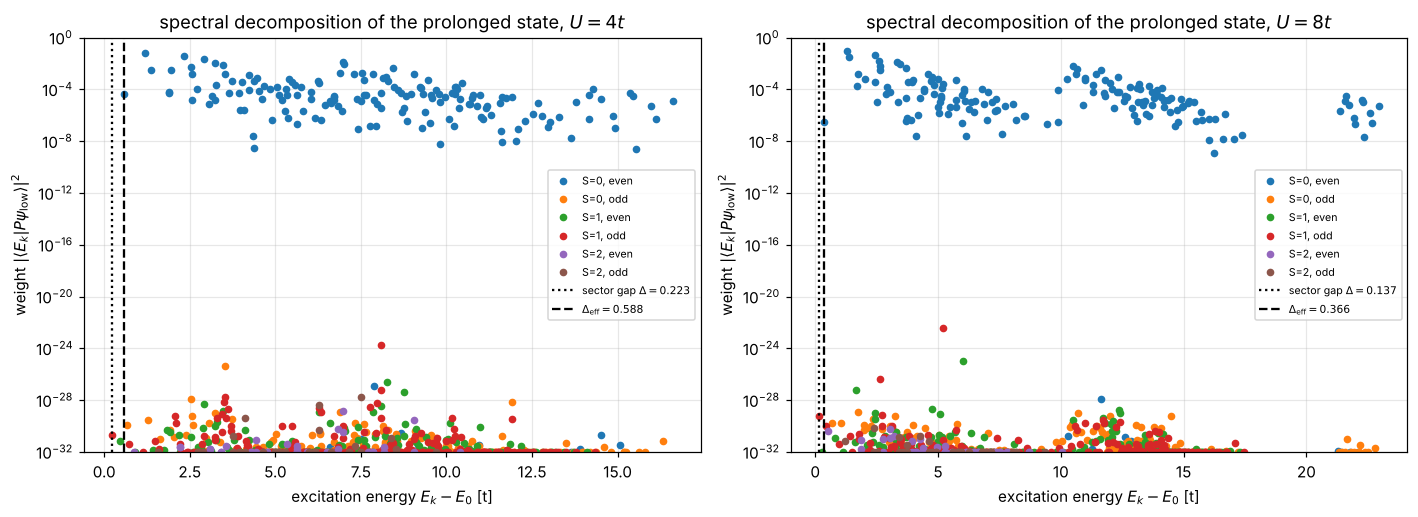

In [4]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

Rop = hb.site_permutation(hb.reflection_chain(Nf), Nf, 2, 2)
def labels(V, N=Nf):
    S = np.array([hb.total_spin(V[:, k], N, 2, 2)[1] for k in range(V.shape[1])])
    par = np.array([float(np.vdot(V[:, k], Rop @ V[:, k]).real) for k in range(V.shape[1])])
    return np.round(S).astype(int), np.sign(par).astype(int)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for a, U in zip(ax, (4.0, 8.0)):
    r = chain48[U]; wf, Vf, c2 = r["wf"], r["Vf"], r["c2"]
    S, par = labels(Vf)
    dE = wf - wf[0]
    for (s_, p_), col, lab in (((0, 1), "C0", "S=0, even"), ((0, -1), "C1", "S=0, odd"), ((1, 1), "C2", "S=1, even"), ((1, -1), "C3", "S=1, odd"), ((2, 1), "C4", "S=2, even"), ((2, -1), "C5", "S=2, odd")):
        m = (S == s_) & (par == p_) & (dE > 1e-9)
        if m.any():
            a.semilogy(dE[m], np.maximum(c2[m], 1e-32), "o", ms=4, color=col, label=lab)
    a.axvline(r["gap"], color="k", ls=":", label=f"sector gap $\\Delta={r['gap']:.3f}$")
    a.axvline(r["Deff"], color="k", ls="--", label=f"$\\Delta_{{\\rm eff}}={r['Deff']:.3f}$")
    a.set_ylim(1e-32, 1); a.set_xlabel("excitation energy $E_k-E_0$ [t]"); a.set_ylabel("weight $|\\langle E_k|P\\psi_{\\rm low}\\rangle|^2$")
    a.set_title(f"spectral decomposition of the prolonged state, $U={U:.0f}t$"); a.legend(fontsize=7); a.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

print("lowest fine excitations, their symmetry sector and their weight in the prolonged state:")
for U, r in chain48.items():
    S, par = labels(r["Vf"]); dE = r["wf"] - r["wf"][0]
    S0, p0_ = S[0], par[0]
    print(f"  U={U:.0f}: ground state S={S0}, parity {p0_:+d}; sector gap {r['gap']:.3f}, D_eff {r['Deff']:.3f}")
    for k in range(1, 7):
        print(f"       E_{k}-E_0 = {dE[k]:.3f}  S={S[k]} parity {par[k]:+d}  weight {r['c2'][k]:.1e}")
    tot_same = r["c2"][(S == S0) & (par == p0_)].sum()
    print(f"       weight in the (S={S0}, parity {p0_:+d}) sector: {tot_same:.12f}")


Path A, mu_buf = 2: JRS sufficient time T_b(eps=1e-2) with the sector gap and with the symmetry-resolved gap
 U/t  min gap min gap_eff  |B-A|  T_b(gap) T_b(gap_eff)   T*
   0    0.532       0.879  11.06     57149        11583   10
   2    0.319       0.780  11.84    253953        19904   10
   4    0.223       0.588  13.91   1010649        63772   10
   8    0.137       0.366  20.01  10087851       580380   10


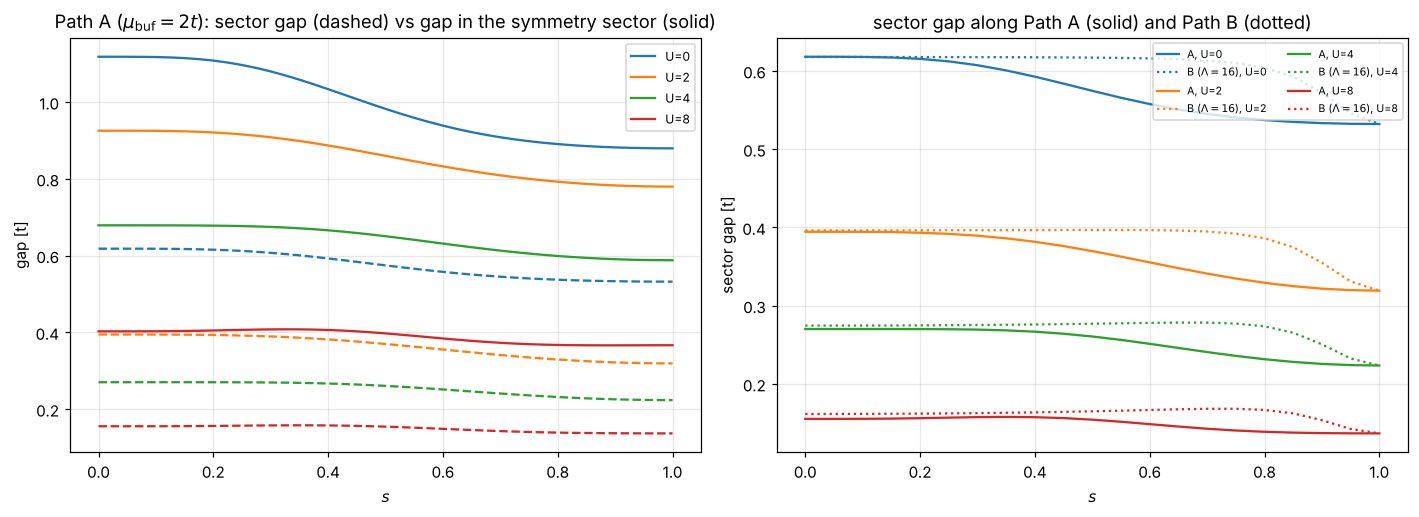

In [5]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# --- the gap along Path A: sector gap vs the gap within the symmetry sector of the tracked state ---
def sector_gap_along_path(Hle, Hhs, ns=41, N=Nf):
    s_grid = np.linspace(0, 1, ns); gsec, geff = [], []
    for s in s_grid:
        H = np.cos(np.pi*s/2)**2*Hle + np.sin(np.pi*s/2)**2*Hhs
        w, V = np.linalg.eigh(H)
        S, par = labels(V[:, :40])
        same = np.where((S == S[0]) & (par == par[0]))[0]
        gsec.append(w[1] - w[0]); geff.append(w[same[1]] - w[0])
    return s_grid, np.array(gsec), np.array(geff)

trapz = getattr(np, "trapezoid", None) or np.trapz
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
print("Path A, mu_buf = 2: JRS sufficient time T_b(eps=1e-2) with the sector gap and with the symmetry-resolved gap")
print(f"{'U/t':>4s} {'min gap':>8s} {'min gap_eff':>11s} {'|B-A|':>6s} {'T_b(gap)':>9s} {'T_b(gap_eff)':>12s} {'T*':>4s}")
bound48 = {}
for U, r in chain48.items():
    v = r["paths"]["A, mu_buf=2"]
    s, gs, ge = sector_gap_along_path(v["Hle"], v["Hhs"], 41)
    ax[0].plot(s, gs, "--", color=cols[U]); ax[0].plot(s, ge, "-", color=cols[U], label=f"U={U:.0f}")
    nBA = np.linalg.norm(v["Hhs"] - v["Hle"], 2)
    dH1 = (np.pi/2)*np.abs(np.sin(np.pi*s))*nBA; dH2 = (np.pi**2/2)*np.abs(np.cos(np.pi*s))*nBA
    Tb = {k: trapz(dH2/g**2 + 7*dH1**2/g**3, s)/np.sqrt(1e-2) for k, g in (("sec", gs), ("eff", ge))}
    hit = np.where(1 - v["ov"] < 1e-3)[0]; Tstar = Ts[hit[0]] if hit.size else np.nan
    bound48[U] = dict(gap=gs.min(), geff=ge.min(), nBA=nBA, Tb_sec=Tb["sec"], Tb_eff=Tb["eff"], Tstar=Tstar)
    print(f"{U:4.0f} {gs.min():8.3f} {ge.min():11.3f} {nBA:6.2f} {Tb['sec']:9.0f} {Tb['eff']:12.0f} {Tstar:4.0f}")
ax[0].set_xlabel("$s$"); ax[0].set_ylabel("gap [t]"); ax[0].set_title("Path A ($\\mu_{\\rm buf}=2t$): sector gap (dashed) vs gap in the symmetry sector (solid)")
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
for U, r in chain48.items():
    ax[1].plot(r["paths"]["A, mu_buf=2"]["s"], r["paths"]["A, mu_buf=2"]["gap"], "-", color=cols[U], label=f"A, U={U:.0f}")
    ax[1].plot(r["paths"]["B, Lambda=16"]["s"], r["paths"]["B, Lambda=16"]["gap"], ":", color=cols[U], label=f"B ($\\Lambda=16$), U={U:.0f}")
ax[1].set_xlabel("$s$"); ax[1].set_ylabel("sector gap [t]"); ax[1].set_title("sector gap along Path A (solid) and Path B (dotted)"); ax[1].legend(fontsize=7, ncol=2); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


The lowest fine excitations are triplets or reflection-odd states with weights at the level of
$10^{-28}$ (round-off), and the first state that carries weight lies at $\Delta_{\rm eff}$, two to
three times the sector gap.  Along the path the gap within the symmetry sector never closes
towards the small sector gap, which is why $T^*$ is flat in $U$; the sufficient time of the JRS
bound remains two to three orders of magnitude above $T^*$ even with the symmetry-resolved gap, as
in paper I.

---
## 5&nbsp; Bootstrapping from the filled dimer and composing refinement steps

The self-similar hierarchy can start from the two-site dimer with $N_\uparrow=N_\downarrow=2$, whose
sector contains a single state (both sites doubly occupied, $E_{\rm low}=U-4t$): a computational
basis state, with no variational preprocessing, in the spirit of the $k=2$ determinant of paper I.
We refine it $2\to4$, then compose the steps $2\to4\to8$ with the *refined* (not the exact) state
as the input of the next step, the shift $\mu$ being referenced to the variational coarse energy
$\langle\psi|H_{\rm low}|\psi\rangle$, and compare with a single-shot refinement $2\to8$ in which
each coarse site is resolved into a block of four.

filled dimer 2 -> 4, (2,2), Path A with mu_buf = 2:
 U/t   E_low   E_high     p0  Delta  D_eff  min gap | p(2) p(4) p(8) p(12) p(16) p(24) p(32)
   0  -4.000  -4.4721  0.805  1.236  2.236    1.236 | 0.9068 0.9923 0.9999 1.0000 1.0000 1.0000 1.0000
   2  -2.000  -2.8759  0.754  0.789  1.851    0.789 | 0.8916 0.9809 0.9995 0.9999 1.0000 1.0000 1.0000
   4  -0.000  -1.9531  0.645  0.540  1.358    0.540 | 0.8406 0.9492 0.9979 0.9998 0.9999 1.0000 1.0000
   8   4.000  -1.1172  0.480  0.311  0.805    0.311 | 0.7177 0.8610 0.9787 0.9980 0.9997 0.9999 1.0000

composed chain 2 -> 4 -> 8 (refined input at every step, mu from the variational coarse energy), U = 4:
  step 2->4 at T=8: p = 0.99787, E_var = -4.96963 (exact -4.97657); prolonged to 8 sites: p0 = 0.7966; after 4->8: p(2)=0.89835 p(4)=0.97419 p(8)=0.99614 p(12)=0.99772 p(16)=0.99780 p(24)=0.99788 p(32)=0.99787
  step 2->4 at T=16: p = 0.99993, E_var = -4.97635 (exact -4.97657); prolonged to 8 sites: p0 = 0.7970; after 4->8: p(2)=0.90064

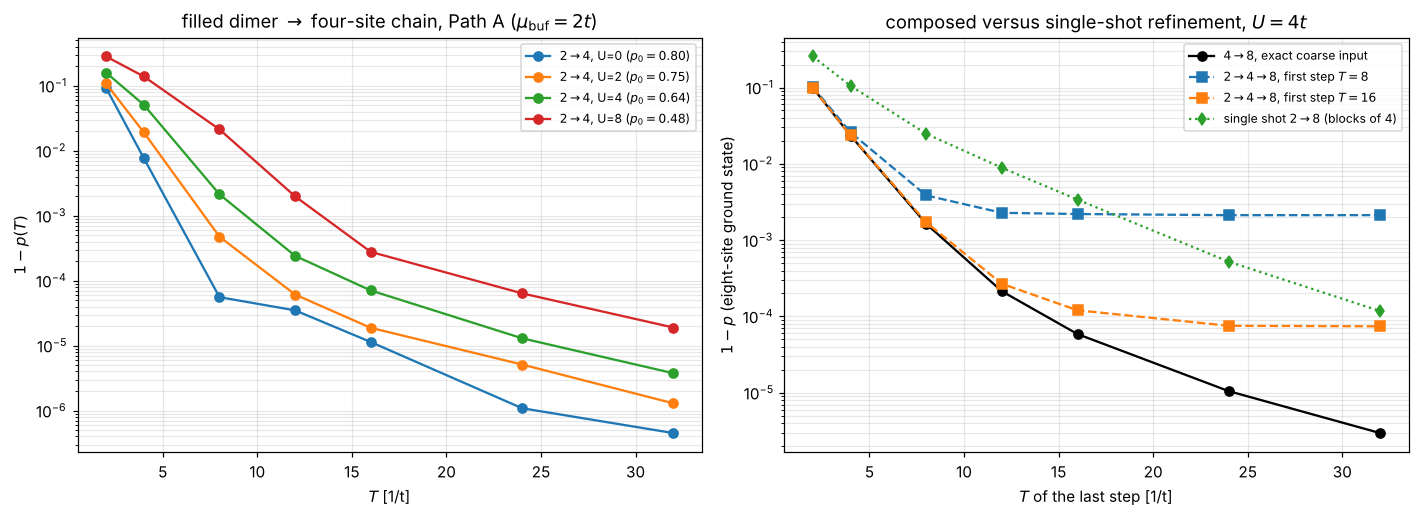

In [6]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

Ts5 = np.array([2, 4, 8, 12, 16, 24, 32])
print("filled dimer 2 -> 4, (2,2), Path A with mu_buf = 2:")
print(f"{'U/t':>4s} {'E_low':>7s} {'E_high':>8s} {'p0':>6s} {'Delta':>6s} {'D_eff':>6s} {'min gap':>8s} | " + " ".join(f"p({T})" for T in Ts5))
dimer = {}
for U in Us:
    (Nc, bc), (Nf2, bf2), blocks2, intra2 = hb.refine_chain(2)
    Hf, _ = hb.H_hubbard(Nf2, bf2, 2, 2, U); Hd = Hf.toarray(); wf, Vf = np.linalg.eigh(Hd)
    P = hb.prolong(Nc, Nf2, blocks2, 2, 2); ps = hb.prolonged_state(Hf, P)
    Deff, c2 = hb.effective_gap(ps["Phi0"], wf, Vf)
    Hle, Hhs = hb.path_A(Hd, ps["Hl"], P, ps["El"] + 2.0)
    ov, eigs = hb.refine_overlaps(ps["Phi0"], Hle, Hhs, Ts5, Vf[:, 0], MSL)
    s, W = hb.path_gap(Hle, Hhs, 21)
    dimer[U] = dict(E_low=ps["El"], E_high=wf[0], p0=c2[0], gap=wf[1]-wf[0], Deff=Deff, ov=ov, eigs=eigs, Phi0=ps["Phi0"], Hf=Hd, wf=wf, Vf=Vf)
    print(f"{U:4.0f} {ps['El']:7.3f} {wf[0]:8.4f} {c2[0]:6.3f} {wf[1]-wf[0]:6.3f} {Deff:6.3f} {(W[:,1]-W[:,0]).min():8.3f} | " + " ".join(f"{o:.4f}" for o in ov))

# --- composed chain 2 -> 4 -> 8 with refined inputs, versus exact inputs and the single-shot 2 -> 8 ---
print("\ncomposed chain 2 -> 4 -> 8 (refined input at every step, mu from the variational coarse energy), U = 4:")
U = 4.0
composed = {}
for T1 in (8, 16):
    psi4 = hb.evolve(dimer[U]["Phi0"], dimer[U]["eigs"], T1)              # refined 4-site state after T1
    r = chain48[U]; Hl4 = r["Hl"]
    # express psi4 in the coarse (4-site) sector: it IS a 4-site sector vector (dim 36)
    El_var = float(np.real(np.vdot(psi4, Hl4 @ psi4)))
    Phi0 = r["P"] @ psi4
    Hle, Hhs = hb.path_A(r["Hf"], Hl4, r["P"], El_var + 2.0)
    ov, eigs_c = hb.refine_overlaps(Phi0, Hle, Hhs, Ts5, r["Vf"][:, 0], MSL)
    composed[T1] = dict(ov=ov, psi8=hb.evolve(Phi0, eigs_c, 16)); del eigs_c
    p4 = abs(np.vdot(dimer[U]["Vf"][:, 0], psi4))**2
    print(f"  step 2->4 at T={T1}: p = {p4:.5f}, E_var = {El_var:.5f} (exact {r['E_low']:.5f}); prolonged to 8 sites: p0 = {abs(np.vdot(r['Vf'][:,0], Phi0))**2:.4f};"
          f" after 4->8: " + " ".join(f"p({T})={o:.5f}" for T, o in zip(Ts5, ov)))
print("  exact coarse input (Sec. 3):                 " + " ".join(f"p({T})={chain48[U]['paths']['A, mu_buf=2']['ov'][list(Ts).index(T)]:.5f}" for T in (8, 16, 32)))
# single shot 2 -> 8 with blocks of four fine sites
(Nc, bc), (Nf8, bf8), blocks8, intra8 = hb.refine_chain(2, b=4)
Hf8 = chain48[U]["Hf"]; wf8, Vf8 = chain48[U]["wf"], chain48[U]["Vf"]
P8 = hb.prolong(Nc, Nf8, blocks8, 2, 2); ps8 = hb.prolonged_state(Hf8, P8)
Deff8, c28 = hb.effective_gap(ps8["Phi0"], wf8, Vf8)
Hle, Hhs = hb.path_A(Hf8, ps8["Hl"], P8, ps8["El"] + 2.0)
ov28, _ = hb.refine_overlaps(ps8["Phi0"], Hle, Hhs, Ts5, Vf8[:, 0], MSL)
print(f"  single shot 2->8 (blocks of 4): E_low = {ps8['El']:.4f}, p0 = {c28[0]:.4f}, D_eff = {Deff8:.3f}; " + " ".join(f"p({T})={o:.5f}" for T, o in zip(Ts5, ov28)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for U_, d in dimer.items():
    ax[0].semilogy(Ts5, np.maximum(1 - d["ov"], 1e-12), "o-", color=cols[U_], label=f"$2\\to4$, U={U_:.0f} ($p_0={d['p0']:.2f}$)")
ax[0].set_xlabel("$T$ [1/t]"); ax[0].set_ylabel("$1-p(T)$"); ax[0].set_title("filled dimer $\\to$ four-site chain, Path A ($\\mu_{\\rm buf}=2t$)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which="both")
ax[1].semilogy(Ts5, np.maximum(1 - np.array([chain48[U]['paths']['A, mu_buf=2']['ov'][list(Ts).index(T)] for T in Ts5]), 1e-12), "k-o", label="$4\\to8$, exact coarse input")
for T1, cmp_ in composed.items():
    ax[1].semilogy(Ts5, np.maximum(1 - cmp_["ov"], 1e-12), "s--", label=f"$2\\to4\\to8$, first step $T={T1}$")
ax[1].semilogy(Ts5, np.maximum(1 - ov28, 1e-12), "d:", label="single shot $2\\to8$ (blocks of 4)")
ax[1].set_xlabel("$T$ of the last step [1/t]"); ax[1].set_ylabel("$1-p$ (eight-site ground state)"); ax[1].set_title("composed versus single-shot refinement, $U=4t$"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


---
## 6&nbsp; Eight to sixteen sites

The $784\to14\,400$-dimensional step is handled with ARPACK for the reference and a sparse Krylov
exponential for the slice propagation (48 slices).  The effective gap is read off from the lowest
forty eigenstates of the fine sector.

In [7]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

from scipy.sparse.linalg import eigsh
from scipy.sparse import csr_matrix, identity
t0 = time.time()
(Nc, bc), (Nf16, bf16), blocks16, intra16 = hb.refine_chain(8)
U = 4.0
Hf16, _ = hb.H_hubbard(Nf16, bf16, 2, 2, U)
w16, V16 = eigsh(Hf16, k=40, which="SA", tol=1e-10); o = np.argsort(w16); w16, V16 = w16[o], V16[:, o]
P16 = hb.prolong(Nc, Nf16, blocks16, 2, 2, sparse=True); ps16 = hb.prolonged_state(Hf16, P16)
Deff16, c216 = hb.effective_gap(ps16["Phi0"], w16, V16)
S16 = hb.total_spin(V16[:, 0], Nf16, 2, 2)[1]
print(f"chain 8->16, (2,2), U={U:.0f}: dims {ps16['Hl'].shape[0]} -> {Hf16.shape[0]}; E_low = {ps16['El']:.6f}, E_high = {w16[0]:.6f}, "
      f"p0 = {c216[0]:.4f}, sector gap = {w16[1]-w16[0]:.4f}, D_eff = {Deff16:.4f} (S of the ground state: {S16:.0f})  [{time.time()-t0:.0f} s]")
print("  excitations with weight > 1e-10 among the lowest 40: " + ", ".join(f"{w16[k]-w16[0]:.3f} ({c216[k]:.1e})" for k in range(1, 40) if c216[k] > 1e-10))
mu = ps16["El"] + 2.0
Hle16 = P16 @ csr_matrix(ps16["Hl"] - mu*np.eye(len(ps16["Hl"]))) @ P16.T; Hhs16 = Hf16 - mu*identity(Hf16.shape[0])
res816 = {}
for T in (8, 16, 32):
    psi = hb.refine_sparse(ps16["Phi0"], Hle16, Hhs16, float(T), M=48)
    res816[T] = abs(np.vdot(V16[:, 0], psi))**2
    print(f"  Path A (mu_buf=2), T={T:2d}: p = {res816[T]:.6f}   [{time.time()-t0:.0f} s]")
# composed 2->4->8->16: the refined 8-site state (T=16 at each step) as input
psi8 = composed[16]["psi8"]                      # 2->4 (T=16) then 4->8 (T=16), both with variational shifts
El8 = float(np.real(np.vdot(psi8, ps16["Hl"] @ psi8)))
Phi0c = np.asarray(P16 @ psi8).ravel()
Hle16c = P16 @ csr_matrix(ps16["Hl"] - (El8+2.0)*np.eye(len(ps16["Hl"]))) @ P16.T; Hhs16c = Hf16 - (El8+2.0)*identity(Hf16.shape[0])
psi16 = hb.refine_sparse(Phi0c, Hle16c, Hhs16c, 16.0, M=48)
print(f"  composed 2->4->8->16 (T=16 per step, refined inputs): p(8-site input) = {abs(np.vdot(chain48[U]['Vf'][:,0], psi8))**2:.5f}, "
      f"prolonged p0 = {abs(np.vdot(V16[:,0], Phi0c))**2:.4f}, final p = {abs(np.vdot(V16[:,0], psi16))**2:.5f}   [{time.time()-t0:.0f} s]")


chain 8->16, (2,2), U=4: dims 784 -> 14400; E_low = -6.817213, E_high = -7.209813, p0 = 0.8692, sector gap = 0.0510, D_eff = 0.1379 (S of the ground state: 0)  [1 s]
  excitations with weight > 1e-10 among the lowest 40: 0.138 (9.9e-05), 0.415 (7.7e-04), 0.505 (1.2e-02), 0.608 (1.3e-04), 0.633 (9.1e-04), 0.700 (9.9e-05), 0.826 (2.4e-05), 0.857 (8.9e-04)
  Path A (mu_buf=2), T= 8: p = 0.992374   [6 s]
  Path A (mu_buf=2), T=16: p = 0.999313   [11 s]
  Path A (mu_buf=2), T=32: p = 0.999946   [17 s]
  composed 2->4->8->16 (T=16 per step, refined inputs): p(8-site input) = 0.99988, prolonged p0 = 0.8692, final p = 0.99923   [23 s]


---
## 7&nbsp; Two dimensions: the plaquette and the wrong symmetry sector

For the square lattice the first step is $2\times2\to4\times4$ with $2\times2$ plaquettes as blocks
($b=4$, Galerkin parameters $t/2$, $U/4$).  Besides $\mathbf S^2$ the path conserves the point group
$C_{4v}$ of the open square; we project every state on the five irreps with the character
formula $w_\Gamma=(d_\Gamma/8)\sum_g\chi_\Gamma(g)^*\langle\psi|g|\psi\rangle$, the group elements
being fermionic site permutations in the sector basis.

In [8]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

from scipy.sparse.linalg import eigsh
from scipy.sparse import csr_matrix, identity
t0 = time.time()
(Nc, bc), (Nf4, bf4), blocks4, intra4 = hb.refine_square(2)
Ts7 = np.array([4, 8, 16, 32])
print("plaquette 2x2 -> 4x4, (1,1), Path A with mu_buf = 2:")
print(f"{'U/t':>4s} {'E_low':>8s} {'E_high':>8s} {'p0':>6s} {'Delta':>6s} {'D_eff':>6s} {'irrep(coarse gs)':>16s} {'irrep(fine gs)':>14s} | " + " ".join(f"p({T})" for T in Ts7))
sq11 = {}
for U in (0.0, 4.0, 8.0):
    Hf, _ = hb.H_hubbard(Nf4, bf4, 1, 1, U); Hd = Hf.toarray(); wf, Vf = np.linalg.eigh(Hd)
    P = hb.prolong(Nc, Nf4, blocks4, 1, 1); ps = hb.prolonged_state(Hf, P)
    Deff, c2 = hb.effective_gap(ps["Phi0"], wf, Vf)
    Hle, Hhs = hb.path_A(Hd, ps["Hl"], P, ps["El"] + 2.0)
    ov, _ = hb.refine_overlaps(ps["Phi0"], Hle, Hhs, Ts7, Vf[:, 0], MSL)
    ic = hb.c4v_irrep(ps["Vl"][:, 0], 2, 1, 1); i_f = hb.c4v_irrep(Vf[:, 0], 4, 1, 1)
    sq11[U] = dict(E_low=ps["El"], E_high=wf[0], p0=c2[0], gap=wf[1]-wf[0], Deff=Deff, ov=ov)
    print(f"{U:4.0f} {ps['El']:8.4f} {wf[0]:8.4f} {c2[0]:6.3f} {wf[1]-wf[0]:6.3f} {Deff:6.3f} {ic[0]+f' ({ic[1]:.2f})':>16s} {i_f[0]+f' ({i_f[1]:.2f})':>14s} | " + " ".join(f"{o:.5f}" for o in ov))

print(f"\nplaquette 2x2 -> 4x4, (2,2): coarse levels and the fine ground state, labeled by (C4v irrep, S)   [{time.time()-t0:.0f} s]")
sq22 = {}
Uscan = (0.0, 1.0, 2.0, 4.0, 6.0, 8.0)
for U in Uscan:
    Hf, _ = hb.H_hubbard(Nf4, bf4, 2, 2, U)
    w, V = eigsh(Hf, k=30, which="SA", tol=1e-10); o = np.argsort(w); w, V = w[o], V[:, o]
    P = hb.prolong(Nc, Nf4, blocks4, 2, 2, sparse=True); ps = hb.prolonged_state(Hf, P)
    lab_c = [(hb.c4v_irrep(ps["Vl"][:, k], 2, 2, 2)[0], int(round(hb.total_spin(ps["Vl"][:, k], Nc, 2, 2)[1]))) for k in range(6)]
    lab_f = [(hb.c4v_irrep(V[:, k], 4, 2, 2)[0], int(round(hb.total_spin(V[:, k], Nf4, 2, 2)[1]))) for k in range(4)]
    ovl = np.abs(np.asarray((P @ ps["Vl"]).T @ V[:, 0]).ravel())**2
    sq22[U] = dict(wl=ps["wl"], wf=w, lab_c=lab_c, lab_f=lab_f, ovl=ovl, ps=ps, P=P, V=V, Hf=Hf)
    print(f"  U={U:.0f}: coarse E = " + ", ".join(f"{e:.4f} {l}" for e, l in zip(ps["wl"][:4], lab_c[:4]))
          + f" | fine E_0 = {w[0]:.4f} {lab_f[0]}, gap {w[1]-w[0]:.4f} (E_1 {lab_f[1]}) | weight of the fine g.s. on the coarse states: "
          + ", ".join(f"{x:.4f}" for x in ovl[:4]) + f" (all 36: {ovl.sum():.4f})")


plaquette 2x2 -> 4x4, (1,1), Path A with mu_buf = 2:
 U/t    E_low   E_high     p0  Delta  D_eff irrep(coarse gs) irrep(fine gs) | p(4) p(8) p(16) p(32)
   0  -6.0000  -6.4721  0.805  1.000  2.236        A1 (1.00)      A1 (1.00) | 0.99233 0.99994 0.99999 1.00000
   4  -5.8136  -6.2638  0.840  0.792  2.096        A1 (1.00)      A1 (1.00) | 0.99475 0.99985 0.99999 1.00000
   8  -5.7093  -6.1833  0.845  0.711  2.129        A1 (1.00)      A1 (1.00) | 0.99485 0.99977 0.99998 1.00000

plaquette 2x2 -> 4x4, (2,2): coarse levels and the fine ground state, labeled by (C4v irrep, S)   [2 s]
  U=0: coarse E = -10.0000 ('A1', 0), -10.0000 ('B2', 1), -10.0000 ('A2', 1), -10.0000 ('B1', 0) | fine E_0 = -10.9443 ('B2', 0), gap 0.0000 (E_1 ('B2', 0)) | weight of the fine g.s. on the coarse states: 0.3857, 0.0592, 0.1541, 0.0490 (all 36: 0.6480)
  U=1: coarse E = -9.8245 ('B1', 0), -9.8176 ('A2', 1), -9.7010 ('A1', 0), -9.6921 ('B2', 0) | fine E_0 = -10.7601 ('A2', 1), gap 0.0390 (E_1 ('B1', 0)) | weig

coarse state #1 (('A2', 1)), E = -9.3429, 0.0713 above the coarse g.s. (('B1', 0)); p0 = 0.6472; D_eff (lowest 30) = 1.7713 vs sector gap 0.0899
  Path A from the (A2, S=1) coarse state, T= 8: p = 0.999444
  Path A from the (A2, S=1) coarse state, T=16: p = 0.999971
  Path A from the (A2, S=1) coarse state, T=32: p = 0.999986
  Path A from the coarse ground state (('B1', 0)), T=16: p = 2.7e-29 (zero: wrong sector)


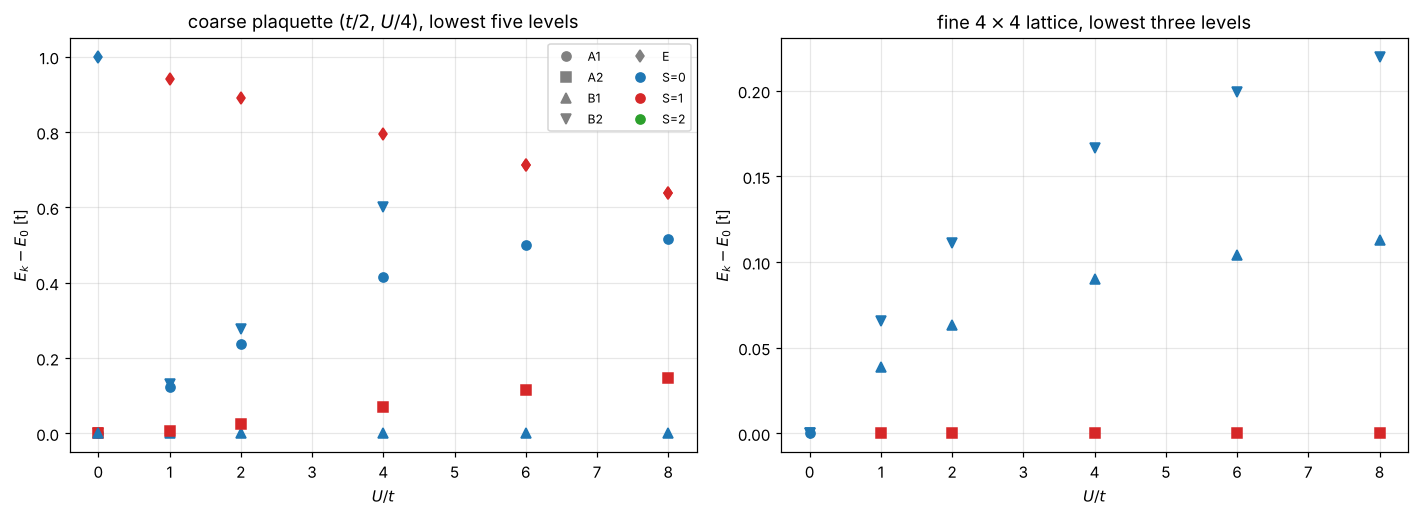

In [9]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# --- refine the coarse state in the target's symmetry sector (the lowest coarse (A2, S=1) state), U = 4 ---
U = 4.0; d = sq22[U]
kA2 = next(k for k, l in enumerate(d["lab_c"]) if l == d["lab_f"][0])
Phi0 = np.asarray(d["P"] @ d["ps"]["Vl"][:, kA2]).ravel(); El = d["wl"][kA2]
Deff22, c2 = hb.effective_gap(Phi0, d["wf"], d["V"])
print(f"coarse state #{kA2} ({d['lab_c'][kA2]}), E = {El:.4f}, {El - d['wl'][0]:.4f} above the coarse g.s. ({d['lab_c'][0]}); p0 = {c2[0]:.4f}; "
      f"D_eff (lowest 30) = {Deff22:.4f} vs sector gap {d['wf'][1]-d['wf'][0]:.4f}")
Hle = d["P"] @ csr_matrix(d["ps"]["Hl"] - (El+2.0)*np.eye(36)) @ d["P"].T; Hhs = d["Hf"] - (El+2.0)*identity(d["Hf"].shape[0])
res22 = {}
for T in (8, 16, 32):
    psi = hb.refine_sparse(Phi0, Hle, Hhs, float(T), M=48)
    res22[T] = abs(np.vdot(d["V"][:, 0], psi))**2
    print(f"  Path A from the (A2, S=1) coarse state, T={T:2d}: p = {res22[T]:.6f}")
psi = hb.refine_sparse(np.asarray(d["P"] @ d["ps"]["Vl"][:, 0]).ravel(), Hle, Hhs, 16.0, M=48)
print(f"  Path A from the coarse ground state ({d['lab_c'][0]}), T=16: p = {abs(np.vdot(d['V'][:,0], psi))**2:.1e} (zero: wrong sector)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
mk = {"A1": "o", "A2": "s", "B1": "^", "B2": "v", "E": "d"}; spc = {0: "C0", 1: "C3", 2: "C2"}
for U_, d_ in sq22.items():
    for k in range(5):
        ax[0].plot(U_, d_["wl"][k] - d_["wl"][0], mk[d_["lab_c"][k][0]], color=spc[d_["lab_c"][k][1]], ms=6)
    for k in range(3):
        ax[1].plot(U_, d_["wf"][k] - d_["wf"][0], mk[d_["lab_f"][k][0]], color=spc[d_["lab_f"][k][1]], ms=6)
for a, ttl in zip(ax, ("coarse plaquette ($t/2$, $U/4$), lowest five levels", "fine $4\\times4$ lattice, lowest three levels")):
    a.set_xlabel("$U/t$"); a.set_ylabel("$E_k-E_0$ [t]"); a.set_title(ttl); a.grid(alpha=0.3)
from matplotlib.lines import Line2D
h = [Line2D([], [], marker=m, color="gray", ls="", label=irr) for irr, m in mk.items()] + [Line2D([], [], marker="o", color=c, ls="", label=f"S={s}") for s, c in spc.items()]
ax[0].legend(handles=h, fontsize=8, ncol=2)
plt.tight_layout(); plt.show()


The half-filled coarse plaquette has a $B_1$ singlet ground state at every $U>0$, with the
$A_2$ triplet close above it; the dilute fine lattice (four electrons on sixteen sites, open
boundaries) has an $(A_2,S=1)$ ground state for all $U>0$ studied.  The prolongation conserves both
$\mathbf S^2$ and $C_{4v}$, so the coarse ground state has exactly zero weight on the fine ground
state and nothing to refine or filter; the lowest coarse state *in the target's sector* carries
weight $0.65$ and refines to $p>0.9999$ at $T=16/t$ despite a sector gap below $0.1t$.

---
## 8&nbsp; The rodeo filter

The filter is that of papers I and II: $M$ cycles of controlled $e^{-iH_{\rm high}t_k}$ with the
phase $e^{iE_{\rm obj}t_k}$, Gaussian times of width $\sigma$, post-selection on the ancilla.  For
$E_{\rm obj}=E_0$ the ensemble infidelity of the accepted runs is exactly
$1-\mathcal F_M=\sum_{k\ne0}|c_k|^2q_k^M/(p+\sum_{k\ne0}|c_k|^2q_k^M)$ with
$q_k=\tfrac12(1+e^{-(E_k-E_0)^2\sigma^2/2})$, which we evaluate from the ED spectrum.  The width is
set by the symmetry-protected gap, $\sigma=5/\Delta_{\rm eff}$.  Inputs: the prolonged state, the
Path-A state at $T=8$ and $16$, the Path-B state at its ceiling, and the fine-chain UCCSD state of
Section 9 (computed here so that the figure is complete).

chain 4->8 (2,2), exact ensemble rodeo with sigma = 5/D_eff   [3 s]

U=0, sigma=5.69/t:  input (p)            1-F_M for M=1,2,4,6,10        acceptance M=2, 6
   prolonged                    (0.77733)   1.3e-01 6.7e-02 1.8e-02 4.5e-03 2.8e-04    0.8330 0.7808
   Path A, T=8                  (0.99718)   1.4e-03 7.1e-04 1.8e-04 4.4e-05 2.8e-06    0.9979 0.9972
   Path A, T=16                 (0.99997)   1.7e-05 8.6e-06 2.2e-06 5.4e-07 3.4e-08    1.0000 1.0000
   Path B ($\Lambda=16$), T=32  (0.99838)   8.1e-04 4.1e-04 1.0e-04 2.5e-05 1.6e-06    0.9988 0.9984
   UCCSD (8 sites)              (1.00000)   3.2e-30 1.6e-30 4.1e-31 1.0e-31 6.6e-33    1.0000 1.0000

U=2, sigma=6.41/t:  input (p)            1-F_M for M=1,2,4,6,10        acceptance M=2, 6
   prolonged                    (0.81388)   1.0e-01 5.4e-02 1.4e-02 3.6e-03 2.2e-04    0.8604 0.8168
   Path A, T=8                  (0.99876)   6.2e-04 3.1e-04 7.8e-05 1.9e-05 1.2e-06    0.9991 0.9988
   Path A, T=16                 (0.99996)   1

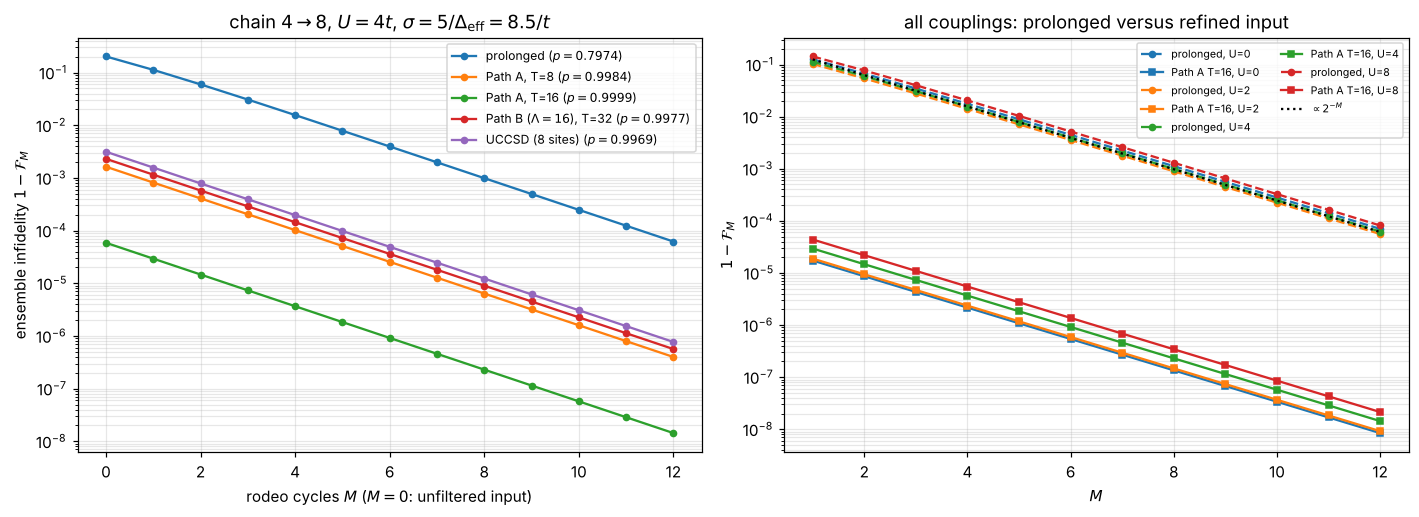

In [10]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

Ms = np.arange(1, 13)
rodeo48 = {}
t0 = time.time()
ucc_fine = {}
for U in Us:
    r = chain48[U]; sig = 5.0/r["Deff"]
    inputs = {"prolonged": r["Phi0"].astype(complex),
              "Path A, T=8": r["paths"]["A, mu_buf=2"]["states"][8],
              "Path A, T=16": r["paths"]["A, mu_buf=2"]["states"][16],
              "Path B ($\\Lambda=16$), T=32": r["paths"]["B, Lambda=16"]["states"][32]}
    uc = hb.uccsd_hubbard(8, hb.chain(8)[1], 2, 2, U, maxiter=400, H=r["Hf"])
    ucc_fine[U] = uc; inputs["UCCSD (8 sites)"] = uc["psi"]
    rodeo48[U] = dict(sigma=sig, res={})
    for name, v in inputs.items():
        inf, acc = hb.rodeo_infidelity(v, r["wf"], r["Vf"], Ms, sig)
        rodeo48[U]["res"][name] = dict(p=abs(np.vdot(r["Vf"][:, 0], v))**2, inf=inf, acc=acc)
print(f"chain 4->8 (2,2), exact ensemble rodeo with sigma = 5/D_eff   [{time.time()-t0:.0f} s]")
for U, d in rodeo48.items():
    print(f"\nU={U:.0f}, sigma={d['sigma']:.2f}/t:  input (p)            1-F_M for M=1,2,4,6,10        acceptance M=2, 6")
    for name, v in d["res"].items():
        print(f"   {name:28s} ({v['p']:.5f})   " + " ".join(f"{v['inf'][m-1]:.1e}" for m in (1, 2, 4, 6, 10)) + f"    {v['acc'][1]:.4f} {v['acc'][5]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
U = 4.0; d = rodeo48[U]
for name, v in d["res"].items():
    ax[0].semilogy(np.concatenate([[0], Ms]), np.concatenate([[1 - v["p"]], v["inf"]]), "o-", ms=4, label=f"{name} ($p={v['p']:.4f}$)")
ax[0].set_xlabel("rodeo cycles $M$ ($M=0$: unfiltered input)"); ax[0].set_ylabel("ensemble infidelity $1-\\mathcal{F}_M$")
ax[0].set_title(f"chain $4\\to8$, $U=4t$, $\\sigma=5/\\Delta_{{\\rm eff}}={d['sigma']:.1f}/t$"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which="both")
for U_, d_ in rodeo48.items():
    ax[1].semilogy(Ms, d_["res"]["prolonged"]["inf"], "o--", color=cols[U_], ms=4, label=f"prolonged, U={U_:.0f}")
    ax[1].semilogy(Ms, d_["res"]["Path A, T=16"]["inf"], "s-", color=cols[U_], ms=4, label=f"Path A T=16, U={U_:.0f}")
ax[1].semilogy(Ms, 0.25*2.0**(-Ms.astype(float)), "k:", label="$\\propto2^{-M}$")
ax[1].set_xlabel("$M$"); ax[1].set_ylabel("$1-\\mathcal{F}_M$"); ax[1].set_title("all couplings: prolonged versus refined input"); ax[1].legend(fontsize=7, ncol=2); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


---
## 9&nbsp; The UCCSD comparator

As in paper I we compare the pipeline with a variational preparation.  The sector-level UCCSD of
`pairinglib.hubbard` uses the free-fermion orbitals as the Hartree–Fock reference, a spin-resolved
pool of singles and doubles applied as a product of exponentials in a fixed order, and the exact
adjoint gradient; it is exact for the ansatz it simulates.  On a device the reference and the
excitations live on the site register after a Givens network, and the circuit cost is counted with
the Pauli-rotation primitive of paper I.  Two uses: (i) the **coarse** solver on the four-site chain
(8 qubits), whose state is then prolonged and refined — the analogue of the $3\to4$ chain of paper
I; (ii) the **fine** solver on the eight-site chain (16 qubits) as the direct competitor.

In [11]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

print(f"{'U/t':>4s} | {'coarse L=4: E_HF':>16s} {'E_UCCSD':>9s} {'E_FCI':>9s} {'1-F':>8s} {'params':>6s} {'CNOT':>5s} | {'fine L=8: E_HF':>14s} {'E_UCCSD':>9s} {'E_FCI':>9s} {'1-F':>8s} {'params':>6s} {'CNOT':>5s}")
ucc_coarse = {}
for U in Us:
    r = chain48[U]
    Hc = hb.H_hubbard(4, hb.chain(4)[1], 2, 2, U/2, t=0.5)[0].toarray() - 4.0*np.eye(36)   # the Galerkin coarse model
    wc, Vc = np.linalg.eigh(Hc)
    uc = hb.uccsd_hubbard(4, hb.chain(4)[1], 2, 2, U/2, t=0.5, maxiter=400, H=Hc)
    ucc_coarse[U] = uc
    cc = hb.uccsd_cnots(4, uc["singles"], uc["doubles"]); cf = hb.uccsd_cnots(8, ucc_fine[U]["singles"], ucc_fine[U]["doubles"])
    uf = ucc_fine[U]
    print(f"{U:4.0f} | {uc['E_hf']:16.5f} {uc['E']:9.5f} {wc[0]:9.5f} {1-abs(np.vdot(Vc[:,0], uc['psi']))**2:8.1e} {uc['n_params']:6d} {cc['total']:5d} | "
          f"{uf['E_hf']:14.5f} {uf['E']:9.5f} {r['E_high']:9.5f} {1-abs(np.vdot(r['Vf'][:,0], uf['psi']))**2:8.1e} {uf['n_params']:6d} {cf['total']:5d}")
print("(CNOT: Givens network to the orbital basis + Pauli-rotation ladders of the excitations, block JW ordering)")

print("\nrefining the UCCSD coarse state (4 sites) to 8 sites, Path A with mu from the variational coarse energy, versus the exact coarse state:")
ucc_refined = {}
for U in Us:
    r = chain48[U]; uc = ucc_coarse[U]
    psi_low = uc["psi"]; El_var = uc["E"]
    Phi0 = r["P"] @ psi_low
    Hle, Hhs = hb.path_A(r["Hf"], r["Hl"], r["P"], El_var + 2.0)
    ov, eigs = hb.refine_overlaps(Phi0, Hle, Hhs, Ts, r["Vf"][:, 0], MSL)
    ucc_refined[U] = dict(ov=ov, Phi0=Phi0, state16=hb.evolve(Phi0, eigs, 16)); del eigs
    print(f"  U={U:.0f}: p0 = {abs(np.vdot(r['Vf'][:,0], Phi0))**2:.5f} (exact input {r['p0']:.5f});  " + "  ".join(f"p({T})={ov[list(Ts).index(T)]:.5f}" for T in (8, 16, 32))
          + "   [exact input: " + " ".join(f"{r['paths']['A, mu_buf=2']['ov'][list(Ts).index(T)]:.5f}" for T in (8, 16, 32)) + "]")


 U/t | coarse L=4: E_HF   E_UCCSD     E_FCI      1-F params  CNOT | fine L=8: E_HF   E_UCCSD     E_FCI      1-F params  CNOT
   0 |         -6.23607  -6.23607  -6.23607  6.7e-16     26  1464 |       -6.82295  -6.82295  -6.82295  1.8e-15    198 23312
   2 |         -5.23607  -5.43744  -5.43797  1.8e-04     26  1464 |       -5.71184  -6.02962  -6.03209  4.7e-04    198 23312
   4 |         -4.23607  -4.96957  -4.97657  3.3e-03     26  1464 |       -4.60073  -5.61876  -5.63443  3.1e-03    198 23312
   8 |         -2.23607  -4.51765  -4.55859  1.7e-02     26  1464 |       -2.37850  -5.22167  -5.27797  1.2e-02    198 23312
(CNOT: Givens network to the orbital basis + Pauli-rotation ladders of the excitations, block JW ordering)

refining the UCCSD coarse state (4 sites) to 8 sites, Path A with mu from the variational coarse energy, versus the exact coarse state:
  U=0: p0 = 0.77733 (exact input 0.77733);  p(8)=0.99718  p(16)=0.99997  p(32)=1.00000   [exact input: 0.99718 0.99997 1.00000]
  U

---
## 10&nbsp; Circuit level: Pauli structure, Trotterized refinement and gate budgets

In the block Jordan–Wigner ordering an open chain of $L_f$ sites on $2L_f$ qubits has
$4(L_f-1)$ hopping strings $\tfrac t2(X_jX_{j+1}+Y_jY_{j+1})$ of weight two, $L_f$ interaction
strings $\tfrac U4Z_jZ_{j+L_f}$ and $2L_f$ single-$Z$ terms; we verify the count on $L=4$ (8 qubits)
with the full-space Pauli decomposition of the library and count CNOTs with the primitive of paper
I (a weight-$w$ rotation costs $2(w-1)$ CNOTs; a controlled rotation two more).  The product formula
groups the bonds into two layers of disjoint bonds (each layer is a product of commuting two-qubit
blocks, realized exactly) plus the diagonal interaction.  The embedded coarse term of Path A is
the coarse Hubbard step on the bonding register conditioned on all $2N_c$ antibonding qubits being
empty; its cost is quoted with the shared-flag convention of the revision of 2026-10-20 (the
conjunction of the antibonding controls is computed once into a clean flag qubit, every coarse
rotation is singly controlled by it, the conditioned scalar phase is one controlled phase, and the
frame change to the bonding basis is charged around each application), with the Gray-code and
per-rotation Toffoli-ladder conventions for comparison.  The controlled fine step absorbs the
scalar sum of the single-$Z$ terms (fixed particle number) into the ancilla phase.  We then (i) find the number of second-order steps that reproduces
the exact-slice overlap at $T=16$ to within $1-p_{\rm exact}$, for both paths, and (ii) feed the
same Trotterized rodeo filter (second order, $\delta t=0.25$, forty Gaussian time sets) the
prolonged, refined and UCCSD inputs and count CNOTs per accepted preparation, exactly as in Sec. V.C
of paper I.

L=4 (8 qubits): full-space decomposition -> 24 non-identity strings, max weight 2; analytic count 24 (hopping 12, ZZ 4, Z 8)
L=4 (8 qubits): 24 strings of weight <= 2; CNOTs per step: order 1 32, order 2 64, controlled order 2 128 (24 rotations)
L=8 (16 qubits): 52 strings of weight <= 2; CNOTs per step: order 1 72, order 2 144, controlled order 2 288 (52 rotations)
Path A coarse term for 4->8: 24 rotations conditioned on 8 antibonding qubits: shared flag 124 CNOTs + frame change 32 per application (c-1 = 7 clean work qubits); per-rotation Toffoli ladder 1132; Gray-code phase polynomial 12526; unconditioned 32
prolongation 4->8: 16 CNOTs

Trotterized refinement, T = 16, U = 4: overlap with the fine ground state (exact slices: Path A 0.999941, Path B Lambda=8 0.992393, Lambda=16 0.993156)
 n_s |  A order 1  A order 2 | B8 order 1 B8 order 2 | B16 order 1 B16 order 2
  16 |   0.014644   0.078675 |   0.001257   0.001857 |   0.000201   0.016955
  32 |   0.760642   0.934267 |   0.016447   0

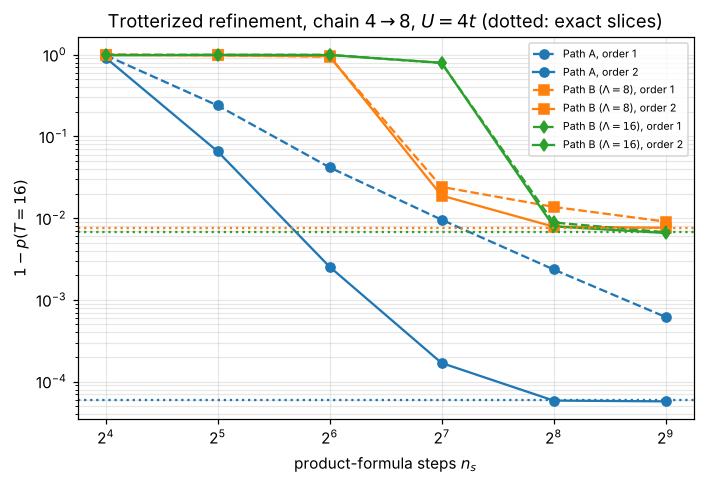

In [12]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# --- Pauli structure and step costs ---
for L in (4, 8):
    N, bonds = hb.chain(L); pc = hb.hubbard_pauli_counts(N, bonds)
    if L == 4:
        dec = pl.pauli_decompose(hb.hubbard_full_jw(N, bonds, 4.0)); ws = [sum(c != "I" for c in s) for s in dec]
        print(f"L={L} (8 qubits): full-space decomposition -> {len(dec)-1} non-identity strings, max weight {max(ws)}; analytic count {pc['total']} (hopping {pc['hopping']}, ZZ {pc['interaction']}, Z {pc['single_Z']})")
    st1 = hb.chain_step_cnots(N, bonds, 1); st2 = hb.chain_step_cnots(N, bonds, 2); ct2 = hb.chain_step_cnots(N, bonds, 2, controlled=True)
    print(f"L={L} ({2*L} qubits): {pc['total']} strings of weight <= {pc['max_weight']}; CNOTs per step: order 1 {st1['cnots']}, order 2 {st2['cnots']}, controlled order 2 {ct2['cnots']} ({st1['rotations']} rotations)")
Nc, bc = hb.chain(4); ca = hb.conditioned_term_cnots(Nc, bc, n_controls=8)
print(f"Path A coarse term for 4->8: {ca['rotations']} rotations conditioned on 8 antibonding qubits: shared flag {ca['flag']} CNOTs + frame change {ca['frame']} per application (c-1 = 7 clean work qubits); per-rotation Toffoli ladder {ca['toffoli']}; Gray-code phase polynomial {ca['gray']}; unconditioned {ca['base']}")
CA_FLAG = ca["flag"] + ca["frame"]
CN_PROL = 2*4*2            # Givens rotations: N_c per spin, 2 CNOTs each
print(f"prolongation 4->8: {CN_PROL} CNOTs")

# --- Trotterized refinement at T = 16, U = 4: steps needed for both paths ---
U = 4.0; r = chain48[U]; T = 16.0
Psih = r["Vf"][:, 0]
terms = hb.hubbard_terms(8, hb.chain(8)[1], 2, 2, U)          # [K_even, K_odd, D]
Kev, Kod, D = [t_.toarray() for t_ in terms]
mu = r["E_low"] + 2.0
A = r["P"] @ (r["Hl"] - mu*np.eye(36)) @ r["P"].T
p_ex = {"A": r["paths"]["A, mu_buf=2"]["ov"][list(Ts).index(16)], "B8": r["paths"]["B, Lambda=8"]["ov"][list(Ts).index(16)], "B16": r["paths"]["B, Lambda=16"]["ov"][list(Ts).index(16)]}
c2f = lambda s: np.cos(np.pi*s/2)**2; s2f = lambda s: np.sin(np.pi*s/2)**2
groupsA = [A, Kev, Kod, D - mu*np.eye(784)]; coefA = [c2f, s2f, s2f, s2f]
groupsB = [Kev, Kod, D]
coefB = {"B8": [lambda s: 1 + 8.0*np.cos(np.pi*s/2)**2, lambda s: 1.0, lambda s: 1.0],
         "B16": [lambda s: 1 + 16.0*np.cos(np.pi*s/2)**2, lambda s: 1.0, lambda s: 1.0]}
ns_list = (16, 32, 64, 128, 256, 512)
trot = {}
print(f"\nTrotterized refinement, T = {T:.0f}, U = {U:.0f}: overlap with the fine ground state (exact slices: Path A {p_ex['A']:.6f}, Path B Lambda=8 {p_ex['B8']:.6f}, Lambda=16 {p_ex['B16']:.6f})")
print(f"{'n_s':>4s} | {'A order 1':>10s} {'A order 2':>10s} | {'B8 order 1':>10s} {'B8 order 2':>10s} | {'B16 order 1':>11s} {'B16 order 2':>11s}")
for ns in ns_list:
    row = []
    for key in ("A", "B8", "B16"):
        groups, coefs = (groupsA, coefA) if key == "A" else (groupsB, coefB[key])
        for order in (1, 2):
            psi = hb.trotter_refine(r["Phi0"], groups, coefs, T, ns, order=order)
            p = abs(np.vdot(Psih, psi))**2; trot[(key, order, ns)] = p; row.append(p)
    print(f"{ns:4d} | " + " | ".join(f"{row[2*k]:10.6f} {row[2*k+1]:10.6f}" for k in range(3)))
TOL = 1e-3
def n_needed(key, order):
    for ns in ns_list:
        if abs(trot[(key, order, ns)] - p_ex[key]) <= TOL: return ns
    print(f"  (Path {key}, order {order}: not within {TOL} of the exact-slice overlap at n_s={ns_list[-1]}; using it)"); return ns_list[-1]
n_ref = {key: n_needed(key, 2) for key in ("A", "B8", "B16")}
print(f"second-order steps reproducing the exact-slice overlap within {TOL}: Path A {n_ref['A']}, Path B (Lambda=8) {n_ref['B8']}, Path B (Lambda=16) {n_ref['B16']}"
      f"   [order 1: {n_needed('A', 1)}, {n_needed('B8', 1)}, {n_needed('B16', 1)}]")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for key, order, mk_, col in (("A", 1, "o--", "C0"), ("A", 2, "o-", "C0"), ("B8", 1, "s--", "C1"), ("B8", 2, "s-", "C1"), ("B16", 1, "d--", "C2"), ("B16", 2, "d-", "C2")):
    ax.semilogy(ns_list, [max(1 - trot[(key, order, ns)], 1e-9) for ns in ns_list], mk_, color=col, label=f"Path {key.replace('B8', 'B ($\\Lambda=8$)').replace('B16', 'B ($\\Lambda=16$)')}, order {order}")
for key, col in (("A", "C0"), ("B8", "C1"), ("B16", "C2")):
    ax.axhline(1 - p_ex[key], color=col, ls=":")
ax.set_xscale("log", base=2); ax.set_xlabel("product-formula steps $n_s$"); ax.set_ylabel("$1-p(T=16)$"); ax.set_title("Trotterized refinement, chain $4\\to8$, $U=4t$ (dotted: exact slices)"); ax.legend(fontsize=7); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


Trotterized controlled evolution (second order): the fixed step is diagonalized once; the filter then projects on the
eigenvector of the step unitary closest to the ground state, whose eigenphase is what an energy scan on the device locates:
  dt =  0.25: E_eff - E_0 = +8.92e-02, infidelity floor 1-|<Psi|w>|^2 = 2.6e-03
  dt =  0.10: E_eff - E_0 = +1.35e-02, infidelity floor 1-|<Psi|w>|^2 = 5.8e-05
  dt =  0.05: E_eff - E_0 = +3.35e-03, infidelity floor 1-|<Psi|w>|^2 = 3.5e-06
operating point: dt = 0.1, E_obj = E_eff = -5.620907 (E_0 = -5.634427), sigma = 8.51; cycle times quantized to multiples of dt

chain 4->8, U=4: Trotterized rodeo (order 2, dt=0.1, sigma=8.51, 40 time sets); per-step CNOTs 144 (controlled 288); coarse term 156/application   [1 s]
input                                               p prep CNOT | M=1: 1-F_w   acc   CNOT/acc | M=2: 1-F_w   acc   CNOT/acc | M=4: 1-F_w   acc   CNOT/acc | M=6: 1-F_w   acc   CNOT/acc
prolonged                                     0.79741

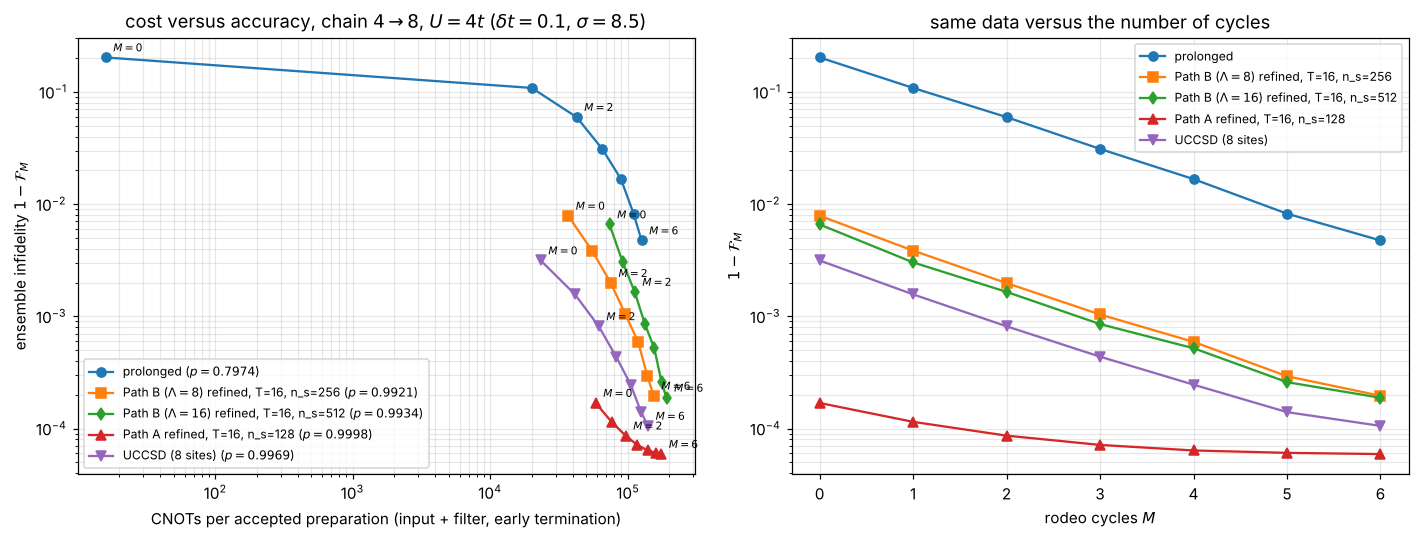

In [13]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# --- matched-observable comparison: the same Trotterized rodeo filter on every input ---
U = 4.0; r = chain48[U]; Psih = r["Vf"][:, 0]; E0 = r["E_high"]
NSAMP, M_MAX, SEED = 40, 6, 3
SIG = rodeo48[U]["sigma"]
N8, b8 = hb.chain(8)
st2 = hb.chain_step_cnots(N8, b8, 2)["cnots"]; ct2 = hb.chain_step_cnots(N8, b8, 2, controlled=True)["cnots"]
ca = CA_FLAG                                                     # shared-flag coarse term incl. the frame change
terms = hb.hubbard_terms(N8, b8, 2, 2, U)
print("Trotterized controlled evolution (second order): the fixed step is diagonalized once; the filter then projects on the")
print("eigenvector of the step unitary closest to the ground state, whose eigenphase is what an energy scan on the device locates:")
for dt_ in (0.25, 0.1, 0.05):
    tr_ = hb.trotter_evolution(terms, dt_, order=2, target=Psih)
    print(f"  dt = {dt_:5.2f}: E_eff - E_0 = {tr_['E_eff'] - E0:+.2e}, infidelity floor 1-|<Psi|w>|^2 = {tr_['floor']:.1e}")
DT = 0.1
tr = hb.trotter_evolution(terms, DT, order=2, target=Psih); E_obj = tr["E_eff"]
print(f"operating point: dt = {DT}, E_obj = E_eff = {E_obj:.6f} (E_0 = {E0:.6f}), sigma = {SIG:.2f}; cycle times quantized to multiples of dt")
# inputs with their preparation cost (second-order refinement with the steps found above; the coarse term twice per step)
inputs = {"prolonged": (r["Phi0"].astype(complex), CN_PROL),
          f"Path B ($\\Lambda=8$) refined, T=16, n_s={n_ref['B8']}": (hb.trotter_refine(r["Phi0"], groupsB, coefB["B8"], 16.0, n_ref["B8"], order=2), CN_PROL + n_ref["B8"]*st2),
          f"Path B ($\\Lambda=16$) refined, T=16, n_s={n_ref['B16']}": (hb.trotter_refine(r["Phi0"], groupsB, coefB["B16"], 16.0, n_ref["B16"], order=2), CN_PROL + n_ref["B16"]*st2),
          f"Path A refined, T=16, n_s={n_ref['A']}": (hb.trotter_refine(r["Phi0"], groupsA, coefA, 16.0, n_ref["A"], order=2), CN_PROL + n_ref["A"]*(st2 + 2*ca)),
          "UCCSD (8 sites)": (ucc_fine[U]["psi"], hb.uccsd_cnots(8, ucc_fine[U]["singles"], ucc_fine[U]["doubles"])["total"])}
rng = np.random.default_rng(SEED)
tsets = [np.abs(rng.normal(0.0, SIG, M_MAX)) for _ in range(NSAMP)]
cyc_cost = np.array([[tr["nsteps"](t)*ct2 for t in ts] for ts in tsets])        # CNOTs per cycle (controlled second-order steps)
rows = {}
t0 = time.time()
for name, (v0, cprep) in inputs.items():
    p = abs(np.vdot(Psih, v0))**2
    F = np.zeros((NSAMP, M_MAX)); Acc = np.zeros((NSAMP, M_MAX))
    for s_, ts in enumerate(tsets):
        F[s_], Acc[s_] = hb.rodeo_track_U(v0, tr["Ufun"], ts, E_obj, Psih, dt=DT)
    Fw = (F*Acc).sum(0)/Acc.sum(0); Am = Acc.mean(0)
    reach = np.concatenate([np.ones((NSAMP, 1)), Acc[:, :-1]], axis=1)
    cost_et = (cprep + np.cumsum(reach*cyc_cost, axis=1).mean(0))/Am
    rows[name] = dict(p=p, cprep=cprep, Fw=Fw, A=Am, cost=cost_et)
print(f"\nchain 4->8, U={U:.0f}: Trotterized rodeo (order 2, dt={DT}, sigma={SIG:.2f}, {NSAMP} time sets); per-step CNOTs {st2} (controlled {ct2}); coarse term {ca}/application   [{time.time()-t0:.0f} s]")
print(f"{'input':44s} {'p':>8s} {'prep CNOT':>9s} | " + " | ".join(f"M={m}: 1-F_w   acc   CNOT/acc" for m in (1, 2, 4, 6)))
for name, d in rows.items():
    print(f"{name:44s} {d['p']:8.5f} {d['cprep']:9d} | " + " | ".join(f"{1-d['Fw'][m-1]:.1e} {d['A'][m-1]:.4f} {d['cost'][m-1]:8.0f}" for m in (1, 2, 4, 6)))
floor = min(1 - d["Fw"][-1] for d in rows.values())
print(f"best infidelity after {M_MAX} cycles: {floor:.1e} (Trotter floor of the filter: {tr['floor']:.1e})")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
mks = ["o-", "s-", "d-", "^-", "v-"]
for (name, d), mk_ in zip(rows.items(), mks):
    inf = np.concatenate([[1 - d["p"]], 1 - d["Fw"]]); cost = np.concatenate([[d["cprep"]], d["cost"]])
    ax[0].loglog(cost, inf, mk_, label=f"{name} ($p={d['p']:.4f}$)")
    for m in (0, 2, 6): ax[0].annotate(f"$M={m}$", (cost[m], inf[m]), textcoords="offset points", xytext=(5, 4), fontsize=7)
    ax[1].semilogy(np.arange(0, M_MAX+1), inf, mk_, label=name)
ax[0].set_xlabel("CNOTs per accepted preparation (input + filter, early termination)"); ax[0].set_ylabel("ensemble infidelity $1-\\mathcal{F}_M$")
ax[0].set_title(f"cost versus accuracy, chain $4\\to8$, $U=4t$ ($\\delta t={DT}$, $\\sigma={SIG:.1f}$)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which="both")
ax[1].set_xlabel("rodeo cycles $M$"); ax[1].set_ylabel("$1-\\mathcal{F}_M$"); ax[1].set_title("same data versus the number of cycles"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


---
## 11&nbsp; Revision checks: the counted coarse term, the pruned variational comparator, the ordinary adiabatic ramp and the response norm

The assessment of paper I (October 2026) raised points that apply here as well; this section
settles them for the chain $4\to8$ at $U=4t$.  (a) The embedded coarse term of Path A contains
non-commuting coarse terms; the counted circuit does not exponentiate it as one block but as the
three conditioned coarse groups $P(D_c-\mu)P^\dagger$, $PK^c_{\rm even}P^\dagger$,
$PK^c_{\rm odd}P^\dagger$, and the Trotterized refinement is repeated at that level.  (b) The
198-parameter UCCSD of Section 9 is pruned to the operators whose amplitudes exceed $10^{-3}$ and
re-optimized, which is the demonstrated restricted ansatz that an adaptive selection would at
best find.  (c) An ordinary adiabatic ramp that switches on the interaction,
$H(s)=K+\sin^2(\pi s/2)\,U\sum_in_{i\uparrow}n_{i\downarrow}$ started from the free-fermion
determinant of the fine chain (prepared by a Givens network), is the generic preconditioning
against which the specific refinement paths must be measured.  (d) The first-order response norm
$\chi_u(s)=\sum_{n>0}|\langle n|\partial_uH|0\rangle|^2/(E_n-E_0)^2$, $u=\sin^2(\pi s/2)$, of
Path A is followed along the path for every $U$, and the digital filter's long-run state is
characterized.  (e) The matched comparison of Section 10 is repeated with the new inputs, with
$M=0$ included, with CNOTs per attempt as well as per accepted preparation, with bootstrap
uncertainties of the sampled infidelities, and with the minimum cost at three target
infidelities.

(a) Path A, T=16, U=4: exact slices p = 0.999941; second-order product formula with the coarse term as one block / split into three conditioned coarse groups:
    n_s =  64: one block 0.997456   split 0.997299
    n_s = 128: one block 0.999831   split 0.999818
    n_s = 256: one block 0.999941   split 0.999941
    n_s = 512: one block 0.999943   split 0.999943
    steps within 1e-3 of the exact-slice overlap (split groups): n_s = 128; cost 16 + 128*(144 + 2*156) = 58384 CNOTs
(b) UCCSD (8 sites): 72 of 198 amplitudes exceed 1e-02
(b) UCCSD (8 sites): 98 of 198 amplitudes exceed 1e-03
    pruned ansatz (98 parameters, 11408 CNOTs): E = -5.618755, 1-F = 3.145e-03   (full: 198 parameters, 23312 CNOTs, 1-F = 3.143e-03, FCI -5.634427)
(c) U-ramp from the free-fermion determinant: p0 = 0.7804, D_eff = 0.588; exact slices: p(4)=0.96878 p(8)=0.99686 p(12)=0.99960 p(16)=0.99989 p(24)=0.99999 p(32)=0.99999
    T = 8: exact 0.996861; n_s = 64 second-order steps give 0.996891; cost 112 (Givens net

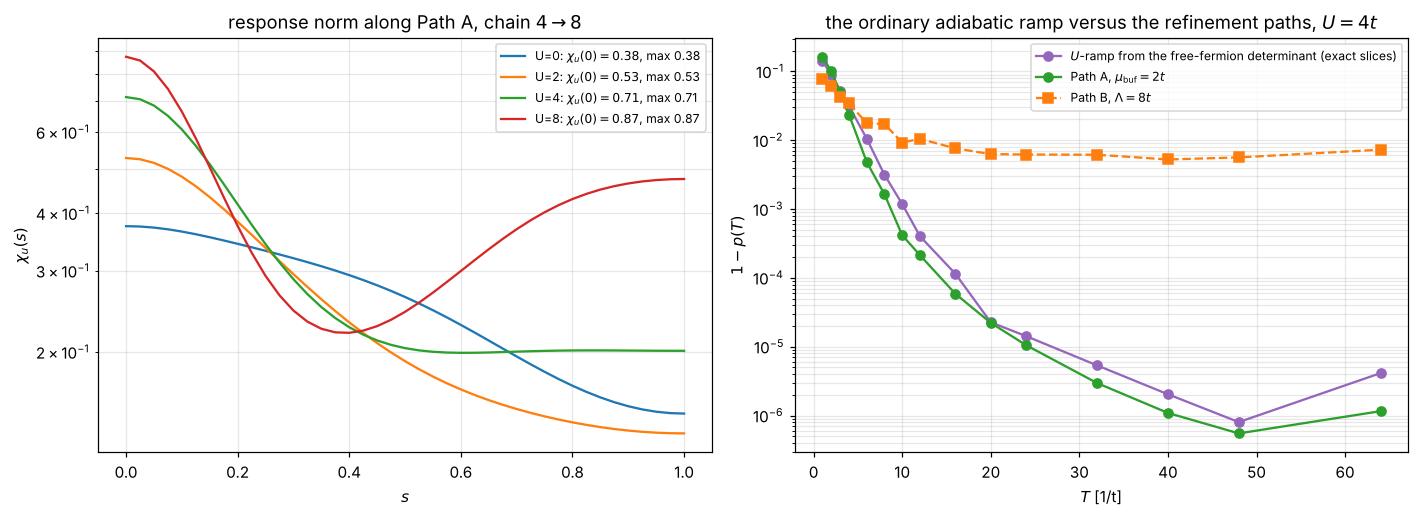

In [14]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

from scipy.optimize import minimize
U = 4.0; r = chain48[U]; Psih = r["Vf"][:, 0]; Hd = r["Hf"]; mu = r["E_low"] + 2.0
Kev, Kod, D = [t_.toarray() for t_ in hb.hubbard_terms(8, hb.chain(8)[1], 2, 2, U)]
c2f = lambda s: np.cos(np.pi*s/2)**2; s2f = lambda s: np.sin(np.pi*s/2)**2
# --- (a) Path A with the coarse term split into its coarse Trotter groups
tl, Ul, cst = hb.galerkin_params("chain", 1.0, U, 4)
Kc_e, Kc_o, Dc = [t_.toarray() for t_ in hb.hubbard_terms(4, hb.chain(4)[1], 2, 2, Ul, t=tl)]
A_groups = [r["P"] @ (Dc + (cst - mu)*np.eye(36)) @ r["P"].T, r["P"] @ Kc_e @ r["P"].T, r["P"] @ Kc_o @ r["P"].T]
assert abs(sum(A_groups) - r["P"] @ (r["Hl"] - mu*np.eye(36)) @ r["P"].T).max() < 1e-10
groupsA_split = A_groups + [Kev, Kod, D - mu*np.eye(784)]; coefA_split = [c2f]*3 + [s2f]*3
pA_ex = p_ex["A"]
print(f"(a) Path A, T=16, U={U:.0f}: exact slices p = {pA_ex:.6f}; second-order product formula with the coarse term as one block / split into three conditioned coarse groups:")
trotA = {}
for ns in (64, 128, 256, 512):
    p1 = abs(np.vdot(Psih, hb.trotter_refine(r["Phi0"], groupsA, coefA, 16.0, ns, order=2)))**2
    p2 = abs(np.vdot(Psih, hb.trotter_refine(r["Phi0"], groupsA_split, coefA_split, 16.0, ns, order=2)))**2
    trotA[ns] = p2; print(f"    n_s = {ns:3d}: one block {p1:.6f}   split {p2:.6f}")
nA_split = next(ns for ns in (64, 128, 256, 512) if abs(trotA[ns] - pA_ex) <= 1e-3)
ca = CA_FLAG; st2 = hb.chain_step_cnots(8, hb.chain(8)[1], 2)["cnots"]
print(f"    steps within 1e-3 of the exact-slice overlap (split groups): n_s = {nA_split}; cost {CN_PROL} + {nA_split}*({st2} + 2*{ca}) = {CN_PROL + nA_split*(st2 + 2*ca)} CNOTs")

# --- (b) pruned UCCSD on the fine chain
uf = ucc_fine[U]; th = np.abs(uf["theta"]); labels = uf["singles"] + uf["doubles"]
for thr in (1e-2, 1e-3):
    print(f"(b) UCCSD (8 sites): {int((th > thr).sum())} of {len(th)} amplitudes exceed {thr:.0e}")
keep = [i for i in range(len(th)) if th[i] > 1e-3]
up = hb.uccsd_hubbard(8, hb.chain(8)[1], 2, 2, U, maxiter=400, H=Hd, keep=keep, theta0=uf["theta"][keep])
cn_full = hb.uccsd_cnots(8, uf["singles"], uf["doubles"])["total"]; cn_pr = hb.uccsd_cnots(8, up["singles"], up["doubles"])["total"]
print(f"    pruned ansatz ({up['n_params']} parameters, {cn_pr} CNOTs): E = {up['E']:.6f}, 1-F = {1-abs(np.vdot(Psih, up['psi']))**2:.3e}   (full: {uf['n_params']} parameters, {cn_full} CNOTs, 1-F = {1-abs(np.vdot(Psih, uf['psi']))**2:.3e}, FCI {r['E_high']:.6f})")

# --- (c) the ordinary adiabatic ramp K -> K + U n n from the free-fermion determinant
Hfree, _ = hb.H_hubbard(8, hb.chain(8)[1], 2, 2, 0.0); w0, V0 = np.linalg.eigh(Hfree.toarray()); FF = V0[:, 0]
Deff_ff, c2ff = hb.effective_gap(FF, r["wf"], r["Vf"])
ov_r, _ = hb.refine_overlaps(FF, Hd - D, Hd, Ts, Psih, MSL)
print(f"(c) U-ramp from the free-fermion determinant: p0 = {c2ff[0]:.4f}, D_eff = {Deff_ff:.3f}; exact slices: " + " ".join(f"p({T})={o:.5f}" for T, o in zip(Ts, ov_r) if T in (4, 8, 12, 16, 24, 32)))
groupsR = [Kev, Kod, D]; coefR = [lambda s: 1.0, lambda s: 1.0, s2f]
CN_GIVENS = 2*(8*7//2)*2
ramp = {}
for T in (8, 16):
    pex = ov_r[list(Ts).index(T)]
    for ns in (16, 32, 64, 128, 256):
        pr = abs(np.vdot(Psih, hb.trotter_refine(FF, groupsR, coefR, float(T), ns, order=2)))**2
        if abs(pr - pex) <= 1e-3 or ns == 256:
            ramp[T] = (ns, pr); break
    print(f"    T = {T}: exact {pex:.6f}; n_s = {ramp[T][0]} second-order steps give {ramp[T][1]:.6f}; cost {CN_GIVENS} (Givens network) + {ramp[T][0]}*{st2} = {CN_GIVENS + ramp[T][0]*st2} CNOTs")

# --- (d) response norm along Path A for every U, and the long-run state of the fixed-step filter
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sgrid = np.linspace(0, 1, 41)
print("(d) first-order response norm chi_u(s) of Path A (mu_buf = 2):")
for U_, r_ in chain48.items():
    mu_ = r_["E_low"] + 2.0; A_ = r_["P"] @ (r_["Hl"] - mu_*np.eye(36)) @ r_["P"].T; B_ = r_["Hf"] - mu_*np.eye(784); dHu = B_ - A_
    chi = []
    for s_ in sgrid:
        u = np.sin(np.pi*s_/2)**2; ws, Vs = np.linalg.eigh((1-u)*A_ + u*B_)
        amp = np.abs(Vs[:, 1:].T @ (dHu @ Vs[:, 0]))**2; chi.append(float(np.sum(amp/(ws[1:]-ws[0])**2)))
    ax[0].plot(sgrid, chi, color=cols[U_], label=f"U={U_:.0f}: $\\chi_u(0)={chi[0]:.2f}$, max {max(chi):.2f}")
    print(f"    U={U_:.0f}: chi_u(0) = {chi[0]:.3f}, max_s chi_u(s) = {max(chi):.3f} at s = {sgrid[int(np.argmax(chi))]:.2f}")
ax[0].set_yscale("log"); ax[0].set_xlabel("$s$"); ax[0].set_ylabel("$\\chi_u(s)$"); ax[0].set_title("response norm along Path A, chain $4\\to8$"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which="both")
ax[1].semilogy(Ts[1:], np.maximum(1 - ov_r[1:], 1e-12), "o-", color="C4", label="$U$-ramp from the free-fermion determinant (exact slices)")
ax[1].semilogy(Ts[1:], np.maximum(1 - r["paths"]["A, mu_buf=2"]["ov"][1:], 1e-12), "o-", color="C2", label="Path A, $\\mu_{\\rm buf}=2t$")
ax[1].semilogy(Ts[1:], np.maximum(1 - r["paths"]["B, Lambda=8"]["ov"][1:], 1e-12), "s--", color="C1", label="Path B, $\\Lambda=8t$")
ax[1].set_xlabel("$T$ [1/t]"); ax[1].set_ylabel("$1-p(T)$"); ax[1].set_title("the ordinary adiabatic ramp versus the refinement paths, $U=4t$"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()
tr_ = hb.trotter_evolution(hb.hubbard_terms(8, hb.chain(8)[1], 2, 2, U), 0.1, order=2, target=Psih)
print(f"    fixed-step filter (dt = 0.1): with quantized times all cycles share the eigenvectors of the step unitary, so the long-run accepted state is its")
print(f"    eigenvector closest to the ground state (infidelity floor {tr_['floor']:.2e}) and, with E_obj = E_eff, the long-run acceptance tends to the input weight on it rather than decaying")


chain 4->8, U=4: Trotterized rodeo (order 2, dt=0.1, sigma=8.51, E_obj = E_eff, 40 time sets; bootstrap relative std. error of the sampled infidelity in brackets)
input                                           p   prep | M=0: 1-F_w (rse)  acc  /attempt /accepted | M=2: 1-F_w (rse)  acc  /attempt /accepted | M=6: 1-F_w (rse)  acc  /attempt /accepted
prolonged                                 0.79741     16 | 2.0e-01 (  0%) 1.000       16       16 | 6.0e-02 (  7%) 0.848    38140    42485 | 4.7e-03 ( 18%) 0.801   116915   126018
free-fermion determinant                  0.78040    112 | 2.2e-01 (  0%) 1.000      112      112 | 6.6e-02 (  5%) 0.831    38236    43217 | 5.0e-03 ( 17%) 0.779   117011   127311
UCCSD pruned (98 par.)                    0.99685  11408 | 3.1e-03 (  0%) 1.000    11408    11408 | 8.2e-04 (  6%) 0.997    49532    49625 | 1.1e-04 (  7%) 0.997   128307   128469
UCCSD (198 par.)                          0.99686  23312 | 3.1e-03 (  0%) 1.000    23312    23312 | 8.1e-04 

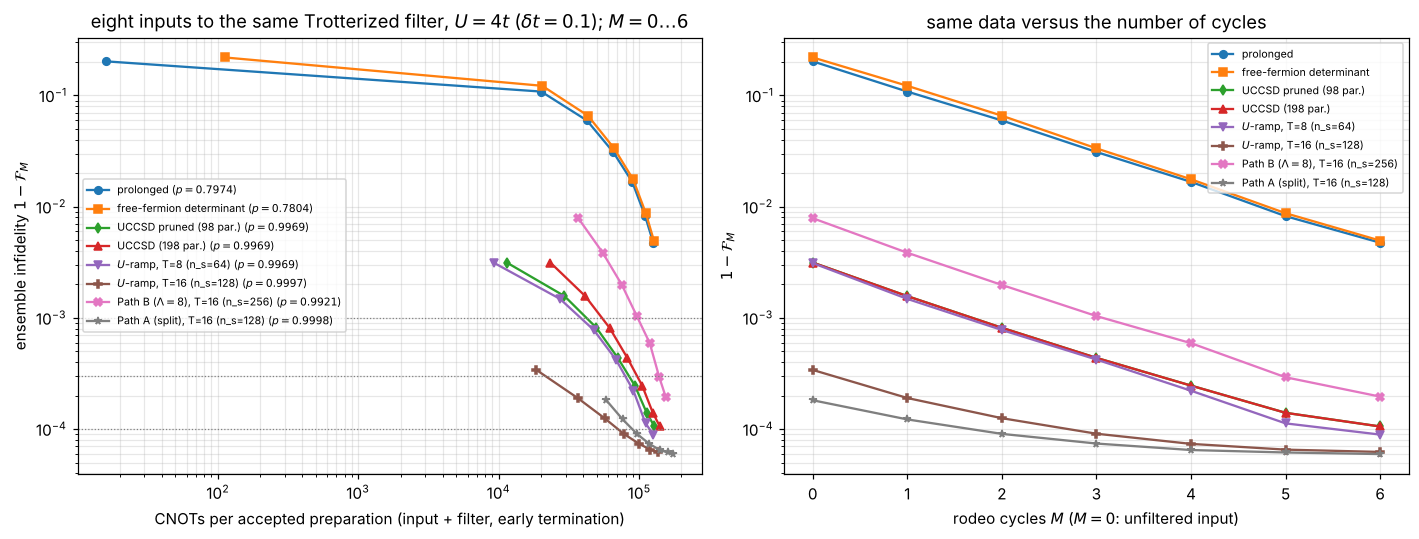

In [15]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# --- (e) matched comparison with the new inputs: M = 0..6, per attempt and per accepted, bootstrap errors, minimum cost at targets
U = 4.0; r = chain48[U]; Psih = r["Vf"][:, 0]
inputs2 = {"prolonged": (r["Phi0"].astype(complex), CN_PROL),
           "free-fermion determinant": (FF.astype(complex), CN_GIVENS),
           f"UCCSD pruned ({up['n_params']} par.)": (up["psi"], cn_pr),
           "UCCSD (198 par.)": (ucc_fine[U]["psi"], cn_full),
           f"$U$-ramp, T=8 (n_s={ramp[8][0]})": (hb.trotter_refine(FF, groupsR, coefR, 8.0, ramp[8][0], order=2), CN_GIVENS + ramp[8][0]*st2),
           f"$U$-ramp, T=16 (n_s={ramp[16][0]})": (hb.trotter_refine(FF, groupsR, coefR, 16.0, ramp[16][0], order=2), CN_GIVENS + ramp[16][0]*st2),
           f"Path B ($\\Lambda=8$), T=16 (n_s={n_ref['B8']})": (hb.trotter_refine(r["Phi0"], groupsB, coefB["B8"], 16.0, n_ref["B8"], order=2), CN_PROL + n_ref["B8"]*st2),
           f"Path A (split), T=16 (n_s={nA_split})": (hb.trotter_refine(r["Phi0"], groupsA_split, coefA_split, 16.0, nA_split, order=2), CN_PROL + nA_split*(st2 + 2*ca))}
rng = np.random.default_rng(SEED); tsets = [np.abs(rng.normal(0.0, SIG, M_MAX)) for _ in range(NSAMP)]
cyc_cost = np.array([[tr["nsteps"](t)*ct2 for t in ts] for ts in tsets])
rows2 = {}
rngb = np.random.default_rng(5)
for name, (v0, cprep) in inputs2.items():
    p = abs(np.vdot(Psih, v0))**2
    F = np.zeros((NSAMP, M_MAX)); Acc = np.zeros((NSAMP, M_MAX))
    for s_, ts in enumerate(tsets):
        F[s_], Acc[s_] = hb.rodeo_track_U(v0, tr["Ufun"], ts, E_obj, Psih, dt=DT)
    Fw = (F*Acc).sum(0)/Acc.sum(0); Am = Acc.mean(0)
    boots = np.array([1 - ((F*Acc)[idx].sum(0)/Acc[idx].sum(0)) for idx in (rngb.integers(0, NSAMP, NSAMP) for _ in range(400))])
    rse = boots.std(0)/np.maximum(1 - Fw, 1e-30)
    reach = np.concatenate([np.ones((NSAMP, 1)), Acc[:, :-1]], axis=1)
    cost_acc = np.concatenate([[float(cprep)], (cprep + np.cumsum(reach*cyc_cost, axis=1).mean(0))/Am])
    cost_att = np.concatenate([[float(cprep)], cprep + np.cumsum(cyc_cost, axis=1).mean(0)])
    rows2[name] = dict(p=p, cprep=cprep, inf=np.concatenate([[1-p], 1-Fw]), rse=np.concatenate([[0.0], rse]), acc=np.concatenate([[1.0], Am]), cost_acc=cost_acc, cost_att=cost_att)
print(f"chain 4->8, U={U:.0f}: Trotterized rodeo (order 2, dt={DT}, sigma={SIG:.2f}, E_obj = E_eff, {NSAMP} time sets; bootstrap relative std. error of the sampled infidelity in brackets)")
print(f"{'input':40s} {'p':>8s} {'prep':>6s} | " + " | ".join(f"M={m}: 1-F_w (rse)  acc  /attempt /accepted" for m in (0, 2, 6)))
for name, d in rows2.items():
    print(f"{name:40s} {d['p']:8.5f} {d['cprep']:6d} | " + " | ".join(f"{d['inf'][m]:.1e} ({100*d['rse'][m]:3.0f}%) {d['acc'][m]:.3f} {d['cost_att'][m]:8.0f} {d['cost_acc'][m]:8.0f}" for m in (0, 2, 6)))
print(f"best infidelity after {M_MAX} cycles: {min(d['inf'][-1] for d in rows2.values()):.1e} (floor of the fixed-step filter {tr['floor']:.1e})")
print("\nfull table, M = 0..6: ensemble infidelity (bootstrap rse %) / cumulative acceptance / CNOTs per accepted preparation")
for name, d in rows2.items():
    print(f"  {name}")
    print("     1-F : " + " ".join(f"{d['inf'][m]:.2e}({100*d['rse'][m]:2.0f}%)" for m in range(M_MAX+1)))
    print("     acc : " + " ".join(f"{d['acc'][m]:12.4f}" for m in range(M_MAX+1)))
    print("     cost: " + " ".join(f"{d['cost_acc'][m]:12.0f}" for m in range(M_MAX+1)))
print("\nminimum CNOTs per accepted preparation reaching a target infidelity, per input (M = 0..6; '-' = not reached):")
TGTS = (1e-3, 3e-4, 1e-4)
print(f"{'input':40s} " + " ".join(f"{'target '+format(t,'.0e'):>22s}" for t in TGTS))
for name, d in rows2.items():
    cells_ = []
    for tgt in TGTS:
        ok = np.where(d["inf"] <= tgt)[0]
        if ok.size:
            m = ok[np.argmin(d["cost_acc"][ok])]; cells_.append(f"M={m} {d['cost_acc'][m]:8.0f} ({d['inf'][m]:.1e})")
        else: cells_.append("-")
    print(f"{name:40s} " + " ".join(f"{c:>22s}" for c in cells_))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
mks = ["o-", "s-", "d-", "^-", "v-", "P-", "X-", "*-"]
for (name, d), mk_ in zip(rows2.items(), mks):
    ax[0].loglog(d["cost_acc"], d["inf"], mk_, ms=5, label=f"{name} ($p={d['p']:.4f}$)")
    ax[1].semilogy(np.arange(0, M_MAX+1), d["inf"], mk_, ms=5, label=name)
for tgt in (1e-3, 3e-4, 1e-4): ax[0].axhline(tgt, color="gray", ls=":", lw=0.8)
ax[0].set_xlabel("CNOTs per accepted preparation (input + filter, early termination)"); ax[0].set_ylabel("ensemble infidelity $1-\\mathcal{F}_M$")
ax[0].set_title(f"eight inputs to the same Trotterized filter, $U=4t$ ($\\delta t={DT}$); $M=0\\ldots6$"); ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3, which="both")
ax[1].set_xlabel("rodeo cycles $M$ ($M=0$: unfiltered input)"); ax[1].set_ylabel("$1-\\mathcal{F}_M$"); ax[1].set_title("same data versus the number of cycles"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


---
## 12&nbsp; Eight to sixteen sites at the circuit level, and the adaptive variational comparator

Section 11 left one question open: at eight sites the free-fermion determinant has the same
overlap and the same effective gap as the prolonged coarse eigenstate, so the plain $U$-ramp wins;
does the coarse eigenstate become the better start once the lattice is larger?  Here the chain
$8\to16$ at $(2,2)$ and $U=4t$ ($784\to14\,400$ states) is taken to the circuit level.  Every
product-formula factor of the fine chain is a Kronecker product of two $120\times120$
exponentials (`hb.hubbard_groups`, one species at a time), the embedded coarse term is applied
exactly through the $784$-dimensional coarse space (`hb.ProjGroup`), the variational comparators
use sparse generators (`hb.uccsd_hubbard_kron`, `hb.adapt_hubbard`), and the Trotter-effective
ground state of the fixed-step filter is obtained by iterating the quantized-time filter itself
(`hb.effective_step_state`), since the $14\,400$-dimensional step unitary cannot be
diagonalized.  We also run ADAPT-VQE with the UCCSD pool at eight sites, through the filter of
Section 11.  Figures 11 and 12.

(a) chain 8->16, (2,2), U=4: E_low = -6.817213, E_high = -7.209813, sector gap 0.0510
    prolonged coarse ground state: p0 = 0.8692, D_eff = 0.1379; free-fermion determinant: p0 = 0.7162, D_eff = 0.1379   [2 s]
    sector gap along the U-ramp: s=0.0: 0.165 s=0.25: 0.125 s=0.5: 0.078 s=0.75: 0.057 s=1.0: 0.051
(b) exact slices, U-ramp from the determinant: p(4)=0.82856 p(8)=0.90373 p(12)=0.94636 p(16)=0.96970 p(24)=0.98970 p(32)=0.99591 p(48)=0.99887 p(64)=0.99919   [9 s]
    Path A, mu_buf=2: p(8)=0.99237 p(16)=0.99931 p(32)=0.99995   [26 s]
    Path A, mu_buf=4: p(8)=0.99155 p(16)=0.99879 p(32)=0.99991   [43 s]
    Path B, Lambda=8: p(16)=0.99492 p(32)=0.99531   [46 s]
    Path B, Lambda=16: p(16)=0.99500 p(32)=0.99605   [51 s]
(c) 16-site step 304 CNOTs (second order; controlled 608); coarse term of Path A (8-site step, 52 rotations, conditioned on 16 qubits): shared flag 268 + frame 64 = 332 per application (per-rotation ladder 4948); Givens network 480; prolongation 8->16 32
    U

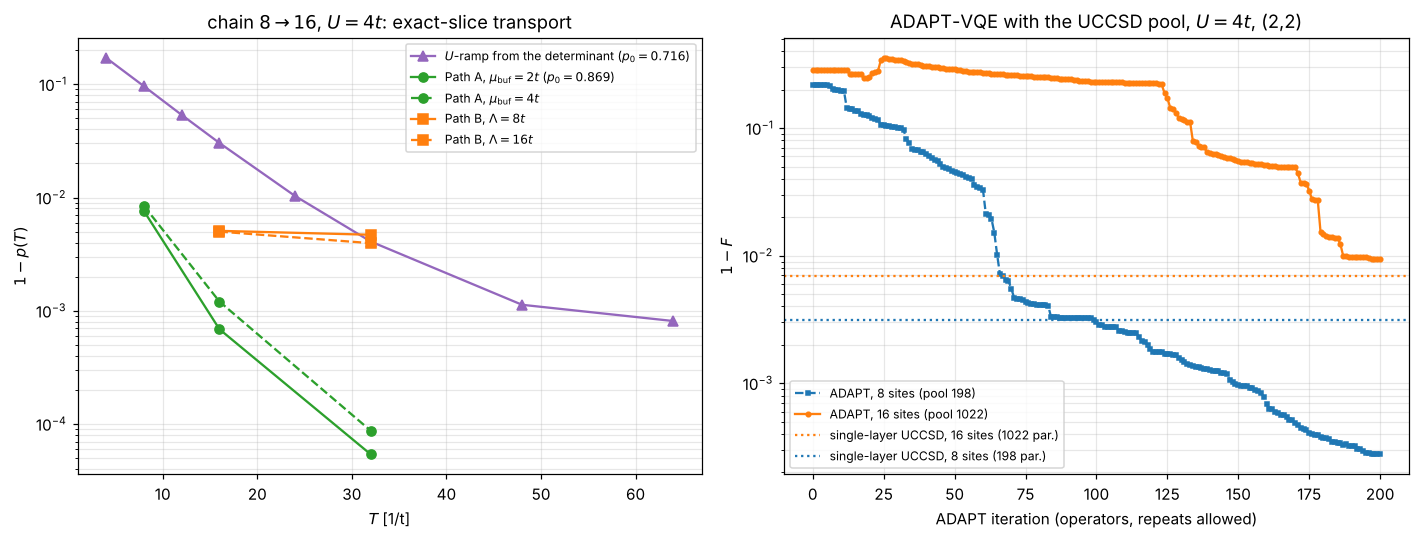

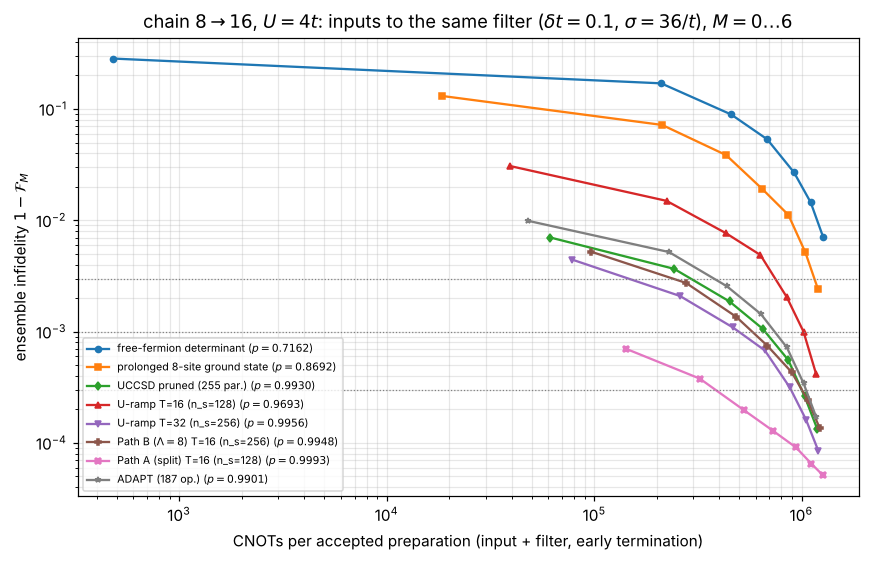

In [16]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

from scipy.sparse.linalg import eigsh
from scipy.sparse import csr_matrix, identity
t0 = time.time()
U = 4.0
(Nc, bc), (Nf, bf), blocks, intra = hb.refine_chain(8)
Hf, _ = hb.H_hubbard(Nf, bf, 2, 2, U); Kfree = hb.H_hubbard(Nf, bf, 2, 2, 0.0)[0]
w16, V16 = eigsh(Hf, k=40, which="SA", tol=1e-10); o = np.argsort(w16); w16, V16 = w16[o], V16[:, o]; GS16 = V16[:, 0]; E016 = w16[0]
P16 = hb.prolong(Nc, Nf, blocks, 2, 2, sparse=True); ps = hb.prolonged_state(Hf, P16); Hl16, El16, Phi016 = ps["Hl"], ps["El"], ps["Phi0"]
pool16 = hb._uccsd_pool_kron(Nf, bf, 2, 2); FF16 = hb._to_site(pool16, pool16["ref"]).real
Deff_p, c2p = hb.effective_gap(Phi016, w16, V16); Deff_f, c2f_ = hb.effective_gap(FF16, w16, V16)
print(f"(a) chain 8->16, (2,2), U={U:.0f}: E_low = {El16:.6f}, E_high = {E016:.6f}, sector gap {w16[1]-w16[0]:.4f}")
print(f"    prolonged coarse ground state: p0 = {c2p[0]:.4f}, D_eff = {Deff_p:.4f}; free-fermion determinant: p0 = {c2f_[0]:.4f}, D_eff = {Deff_f:.4f}   [{time.time()-t0:.0f} s]")
print("    sector gap along the U-ramp: " + " ".join(f"s={s_}: {np.sort(eigsh(Kfree + np.sin(np.pi*s_/2)**2*(Hf-Kfree), k=2, which='SA', tol=1e-8)[0])[1]-np.sort(eigsh(Kfree + np.sin(np.pi*s_/2)**2*(Hf-Kfree), k=2, which='SA', tol=1e-8)[0])[0]:.3f}" for s_ in (0.0, 0.25, 0.5, 0.75, 1.0)))
# --- (b) exact slices (Krylov, 48 slices)
Ts16 = (4, 8, 12, 16, 24, 32, 48, 64)
ramp_ex = {T: abs(np.vdot(GS16, hb.refine_sparse(FF16, Kfree, Hf, float(T), M=48)))**2 for T in Ts16}
print("(b) exact slices, U-ramp from the determinant: " + " ".join(f"p({T})={ramp_ex[T]:.5f}" for T in Ts16) + f"   [{time.time()-t0:.0f} s]")
pathA_ex = {}
for mb in (2.0, 4.0):
    mu = El16 + mb; Hle = P16 @ csr_matrix(Hl16 - mu*np.eye(784)) @ P16.T; Hhs = Hf - mu*identity(Hf.shape[0])
    for T in (8, 16, 32):
        pathA_ex[(mb, T)] = abs(np.vdot(GS16, hb.refine_sparse(Phi016, Hle, Hhs, float(T), M=48)))**2
    print(f"    Path A, mu_buf={mb:.0f}: " + " ".join(f"p({T})={pathA_ex[(mb, T)]:.5f}" for T in (8, 16, 32)) + f"   [{time.time()-t0:.0f} s]")
Kin16 = hb.hubbard_terms(Nf, intra, 2, 2, 0.0, layers=[list(range(len(intra)))])[0]
pathB_ex = {}
for Lam in (8.0, 16.0):
    for T in (16, 32):
        pathB_ex[(Lam, T)] = abs(np.vdot(GS16, hb.refine_sparse(Phi016, Hf + Lam*Kin16, Hf, float(T), M=48)))**2
    print(f"    Path B, Lambda={Lam:.0f}: " + " ".join(f"p({T})={pathB_ex[(Lam, T)]:.5f}" for T in (16, 32)) + f"   [{time.time()-t0:.0f} s]")
# --- (c) product formulas and gate counts
c2f = lambda s: np.cos(np.pi*s/2)**2; s2f = lambda s: np.sin(np.pi*s/2)**2
groups16 = hb.hubbard_groups(Nf, bf, 2, 2, U)
st16 = hb.chain_step_cnots(Nf, bf, 2)["cnots"]; ct16 = hb.chain_step_cnots(Nf, bf, 2, controlled=True)["cnots"]
ca16d = hb.conditioned_term_cnots(8, bc, n_controls=16); ca16 = ca16d["flag"] + ca16d["frame"]; CN_GIVENS16 = 2*(Nf*(Nf-1)//2)*2; CN_PROL16 = 2*8*2
print(f"(c) 16-site step {st16} CNOTs (second order; controlled {ct16}); coarse term of Path A (8-site step, {ca16d['rotations']} rotations, conditioned on 16 qubits): shared flag {ca16d['flag']} + frame {ca16d['frame']} = {ca16} per application (per-rotation ladder {ca16d['toffoli']}); Givens network {CN_GIVENS16}; prolongation 8->16 {CN_PROL16}")
def n_needed16(Phi, grp, coefs, T, pex, tol=1e-3):
    out, prev = [], None
    for ns in (32, 64, 128, 256, 512):
        p = abs(np.vdot(GS16, hb.trotter_path_groups(Phi, grp, coefs, T, ns, order=2)))**2; out.append((ns, p))
        if abs(p - pex) <= tol or (prev is not None and abs(p - prev) < 1e-4 and p > 0.5): return ns, p, out   # converged, or plateaued short of the exact value
        prev = p
    return ns, p, out
trot16 = {}
ramp_coefs = [lambda s: 1.0, lambda s: 1.0, s2f]
for T in (16, 32):
    ns, p, out = n_needed16(FF16, groups16, ramp_coefs, float(T), ramp_ex[T])
    trot16[("ramp", T)] = dict(ns=ns, p=p, psi=hb.trotter_path_groups(FF16, groups16, ramp_coefs, float(T), ns), cost=CN_GIVENS16 + ns*st16)
    print(f"    U-ramp T={T}: exact {ramp_ex[T]:.5f}; " + " ".join(f"{n}:{pp:.5f}" for n, pp in out) + f" -> n_s={ns}, {trot16[('ramp', T)]['cost']} CNOTs   [{time.time()-t0:.0f} s]")
tl, Ul, cst = hb.galerkin_params("chain", 1.0, U, 2 + 2)        # the constant is -t N_particles (N = 4), NOT -t N_coarse: with 8 the embedded path differed from Eq. (6) by -4t cos^2 P P^T (bug fixed 2026-10-20)
Kc_e, Kc_o, Dc = [t_.toarray() for t_ in hb.hubbard_terms(8, bc, 2, 2, Ul, t=tl)]
mu = El16 + 2.0
assert abs(Dc + (cst - mu)*np.eye(784) + Kc_e + Kc_o - (Hl16 - mu*np.eye(784))).max() < 1e-10, "coarse groups must sum to H_low - mu"
gA16 = [hb.ProjGroup(P16, Dc + (cst - mu)*np.eye(784)), hb.ProjGroup(P16, Kc_e), hb.ProjGroup(P16, Kc_o), groups16[0], groups16[1], hb.DiagGroup(groups16[2].d - mu)]
cA16 = [c2f]*3 + [s2f]*3
for T in (8, 16):
    ns, p, out = n_needed16(Phi016, gA16, cA16, float(T), pathA_ex[(2.0, T)])
    trot16[("A", T)] = dict(ns=ns, p=p, psi=hb.trotter_path_groups(Phi016, gA16, cA16, float(T), ns), cost=CN_PROL16 + ns*(st16 + 2*ca16))
    print(f"    Path A (split coarse groups, mu_buf=2) T={T}: exact {pathA_ex[(2.0, T)]:.5f}; " + " ".join(f"{n}:{pp:.5f}" for n, pp in out) + f" -> n_s={ns}, {trot16[('A', T)]['cost']} CNOTs + coarse preparation   [{time.time()-t0:.0f} s]")
gB16 = [groups16[0], groups16[1], groups16[2]]
for Lam in (8.0,):                                   # T = 32 sits at the same ceiling (exact slices above) and would need 512 steps: not Trotterized
    cB16 = [lambda s, L=Lam: 1 + L*np.cos(np.pi*s/2)**2, lambda s: 1.0, lambda s: 1.0]
    for T in (16,):
        ns, p, out = n_needed16(Phi016, gB16, cB16, float(T), pathB_ex[(Lam, T)])
        trot16[("B", T)] = dict(ns=ns, p=p, psi=hb.trotter_path_groups(Phi016, gB16, cB16, float(T), ns), cost=CN_PROL16 + ns*st16)
        print(f"    Path B (Lambda={Lam:.0f}) T={T}: exact {pathB_ex[(Lam, T)]:.5f}; " + " ".join(f"{n}:{pp:.5f}" for n, pp in out) + f" -> n_s={ns}, {trot16[('B', T)]['cost']} CNOTs + coarse preparation   [{time.time()-t0:.0f} s]")
# --- (d) variational inputs at 16 sites, and ADAPT at 8 and 16 sites
uf16 = hb.uccsd_hubbard_kron(Nf, bf, 2, 2, U, maxiter=300, H=Hf); th = np.abs(uf16["theta"]); keep = [i for i in range(len(th)) if th[i] > 1e-3]
up16 = hb.uccsd_hubbard_kron(Nf, bf, 2, 2, U, maxiter=300, H=Hf, keep=keep, theta0=uf16["theta"][keep])
cn_full16 = hb.uccsd_cnots(Nf, uf16["singles"], uf16["doubles"])["total"]; cn_pr16 = hb.uccsd_cnots(Nf, up16["singles"], up16["doubles"])["total"]
print(f"(d) UCCSD (16 sites): {uf16['n_params']} parameters, {cn_full16} CNOTs, E = {uf16['E']:.6f} (E0 {E016:.6f}), 1-F = {1-abs(np.vdot(GS16, uf16['psi']))**2:.3e}; "
      f"pruned (|theta| > 1e-3): {up16['n_params']} parameters, {cn_pr16} CNOTs, 1-F = {1-abs(np.vdot(GS16, up16['psi']))**2:.3e}   [{time.time()-t0:.0f} s]")
def cn_of(N_, ops): return hb.uccsd_cnots(N_, [l for l in ops if len(l) == 3], [l for l in ops if len(l) == 5])["total"]
TGT = (1e-2, 3e-3, 1e-3, 3e-4)
ad16 = hb.adapt_hubbard(Nf, bf, 2, 2, U, grad_tol=1e-6, max_ops=200, H=Hf, target=GS16); h16 = ad16["history"]
reach16 = {tgt: next((d for d in h16 if d["infidelity"] <= tgt), None) for tgt in TGT}
print(f"    ADAPT-VQE, 16 sites (pool {ad16['pool_size']}, repeats allowed): {len(ad16['ops'])} operators, 1-F = {h16[-1]['infidelity']:.2e}; operators (CNOTs) to reach "
      + ", ".join(f"{tgt:.0e}: {reach16[tgt]['n_ops']} ({cn_of(Nf, ad16['ops'][:reach16[tgt]['n_ops']])})" if reach16[tgt] else f"{tgt:.0e}: -" for tgt in TGT) + f"   [{time.time()-t0:.0f} s]")
r8 = chain48[U]; Psih8 = r8["Vf"][:, 0]
ad8 = hb.adapt_hubbard(8, bc, 2, 2, U, grad_tol=1e-6, max_ops=200, H=csr_matrix(r8["Hf"]), target=Psih8); h8 = ad8["history"]
reach8 = {tgt: next((d for d in h8 if d["infidelity"] <= tgt), None) for tgt in TGT}
print(f"    ADAPT-VQE, 8 sites (pool {ad8['pool_size']}): {len(ad8['ops'])} operators, 1-F = {h8[-1]['infidelity']:.2e}; operators (CNOTs) to reach "
      + ", ".join(f"{tgt:.0e}: {reach8[tgt]['n_ops']} ({cn_of(8, ad8['ops'][:reach8[tgt]['n_ops']])})" if reach8[tgt] else f"{tgt:.0e}: -" for tgt in TGT) + f"   [{time.time()-t0:.0f} s]")
# the 8-site ADAPT state at 1e-3 through the filter of Section 11 (same forty time sets)
d8 = reach8[1e-3]
if d8 is not None:
    v0 = d8["psi"].astype(complex); cprep8 = cn_of(8, ad8["ops"][:d8["n_ops"]])
    F = np.zeros((NSAMP, M_MAX)); Acc = np.zeros((NSAMP, M_MAX))
    for s_, ts in enumerate(tsets): F[s_], Acc[s_] = hb.rodeo_track_U(v0, tr["Ufun"], ts, E_obj, Psih8, dt=DT)
    Fw = (F*Acc).sum(0)/Acc.sum(0); Am = Acc.mean(0); reach_ = np.concatenate([np.ones((NSAMP, 1)), Acc[:, :-1]], axis=1)
    cacc8 = np.concatenate([[float(cprep8)], (cprep8 + np.cumsum(reach_*cyc_cost, axis=1).mean(0))/Am]); inf8 = np.concatenate([[1-abs(np.vdot(Psih8, v0))**2], 1-Fw])
    print(f"    8 sites: ADAPT state ({d8['n_ops']} operators, {cprep8} CNOTs) through the Section-11 filter: 1-F_M = " + " ".join(f"{x:.1e}" for x in inf8) + "; CNOTs per accepted preparation " + " ".join(f"{c:.1e}" for c in cacc8))
    print("      minimum cost at 1e-3 / 3e-4 / 1e-4: " + " / ".join((lambda ok: f"{cacc8[ok[np.argmin(cacc8[ok])]]:.1e} (M={ok[np.argmin(cacc8[ok])]})" if ok.size else "-")(np.where(inf8 <= tgt)[0]) for tgt in (1e-3, 3e-4, 1e-4)))
# --- (e) the filter at 16 sites and the matched comparison
SIG16 = 5.0/Deff_p; DT16 = 0.1
psi_eff, E_eff16, resid16 = hb.effective_step_state(groups16, DT16, GS16, E016, SIG16, iters=80, return_residual=True); floor16 = 1 - abs(np.vdot(GS16, psi_eff))**2
print(f"(e) filter at 16 sites: sigma = 5/D_eff = {SIG16:.1f}, dt = {DT16}: E_eff - E0 = {E_eff16-E016:+.2e}, floor {floor16:.1e}, eigenvector residual ||U psi - e^(-iE dt) psi|| = {resid16:.1e}; mean {SIG16*np.sqrt(2/np.pi)/DT16:.0f} steps = {ct16*SIG16*np.sqrt(2/np.pi)/DT16:.2e} CNOTs per cycle   [{time.time()-t0:.0f} s]")
NS16 = 20
rng = np.random.default_rng(SEED); tsets16 = [np.abs(rng.normal(0.0, SIG16, M_MAX)) for _ in range(NS16)]
cyc16 = np.array([[max(1, int(round(t/DT16)))*ct16 for t in ts] for ts in tsets16])        # controlled second-order steps per cycle, as in Section 11
CN_COARSE8 = CN_GIVENS + ramp[16][0]*st2             # the 8-site U-ramp at T=16 (3.4e-4; an exact coarse-state oracle is used here, the actual coarse state is propagated in Section 13)
inputs16 = {"free-fermion determinant": (FF16, CN_GIVENS16),
            "prolonged 8-site ground state": (Phi016, CN_COARSE8 + CN_PROL16),
            f"UCCSD pruned ({up16['n_params']} par.)": (up16["psi"], cn_pr16),
            f"U-ramp T=16 (n_s={trot16[('ramp', 16)]['ns']})": (trot16[("ramp", 16)]["psi"], trot16[("ramp", 16)]["cost"]),
            f"U-ramp T=32 (n_s={trot16[('ramp', 32)]['ns']})": (trot16[("ramp", 32)]["psi"], trot16[("ramp", 32)]["cost"]),
            f"Path B ($\\Lambda=8$) T=16 (n_s={trot16[('B', 16)]['ns']})": (trot16[("B", 16)]["psi"], CN_COARSE8 + trot16[("B", 16)]["cost"]),
            f"Path A (split) T=16 (n_s={trot16[('A', 16)]['ns']})": (trot16[("A", 16)]["psi"], CN_COARSE8 + trot16[("A", 16)]["cost"])}
if reach16[1e-2] is not None:
    inputs16[f"ADAPT ({reach16[1e-2]['n_ops']} op.)"] = (reach16[1e-2]["psi"], cn_of(Nf, ad16["ops"][:reach16[1e-2]["n_ops"]]))
rows16 = {}; rngb = np.random.default_rng(5)
print(f"    matched comparison at 16 sites ({NS16} time sets, M = 0..{M_MAX}, E_obj = E_eff; coarse preparation of the hierarchy counted as {CN_COARSE8} CNOTs)")
for name, (v0, cprep) in inputs16.items():
    v0 = np.asarray(v0, complex); p = abs(np.vdot(GS16, v0))**2
    F = np.zeros((NS16, M_MAX)); Acc = np.zeros((NS16, M_MAX))
    for s_, ts in enumerate(tsets16): F[s_], Acc[s_] = hb.rodeo_track_groups(v0, groups16, ts, E_eff16, GS16, DT16)
    Fw = (F*Acc).sum(0)/Acc.sum(0); Am = Acc.mean(0)
    boots = np.array([1 - ((F*Acc)[idx].sum(0)/Acc[idx].sum(0)) for idx in (rngb.integers(0, NS16, NS16) for _ in range(400))]); rse = boots.std(0)/np.maximum(1-Fw, 1e-30)
    reach_ = np.concatenate([np.ones((NS16, 1)), Acc[:, :-1]], axis=1)
    rows16[name] = dict(p=p, cprep=cprep, inf=np.concatenate([[1-p], 1-Fw]), rse=np.concatenate([[0], rse]), acc=np.concatenate([[1], Am]), cacc=np.concatenate([[float(cprep)], (cprep + np.cumsum(reach_*cyc16, axis=1).mean(0))/Am]))
    print(f"    {name:44s} p={p:.5f} prep={cprep:8d} | " + " ".join(f"{rows16[name]['inf'][m]:.1e}({100*rows16[name]['rse'][m]:2.0f}%)" for m in range(M_MAX+1)) + f" | acc(6) {Am[-1]:.3f} | cost " + " ".join(f"{c:.1e}" for c in rows16[name]["cacc"]) + f"   [{time.time()-t0:.0f} s]")
print("    minimum CNOTs per accepted preparation at a target infidelity (16 sites):")
for tgt in (1e-2, 3e-3, 1e-3, 3e-4):
    best = []
    for name, d in rows16.items():
        ok = np.where(d["inf"] <= tgt)[0]
        if ok.size: m = ok[np.argmin(d["cacc"][ok])]; best.append((d["cacc"][m], name, m, d["inf"][m]))
    best.sort(); print(f"      {tgt:.0e}: " + "; ".join(f"{nm} M={m} {c:.2e} ({i:.1e})" for c, nm, m, i in best))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].semilogy(Ts16, [max(1-ramp_ex[T], 1e-9) for T in Ts16], "^-", color="C4", label="$U$-ramp from the determinant ($p_0=%.3f$)" % c2f_[0])
ax[0].semilogy([8, 16, 32], [max(1-pathA_ex[(2.0, T)], 1e-9) for T in (8, 16, 32)], "o-", color="C2", label="Path A, $\\mu_{\\rm buf}=2t$ ($p_0=%.3f$)" % c2p[0])
ax[0].semilogy([8, 16, 32], [max(1-pathA_ex[(4.0, T)], 1e-9) for T in (8, 16, 32)], "o--", color="C2", label="Path A, $\\mu_{\\rm buf}=4t$")
for Lam, ls_ in ((8.0, "-"), (16.0, "--")):
    ax[0].semilogy([16, 32], [max(1-pathB_ex[(Lam, T)], 1e-9) for T in (16, 32)], "s"+ls_, color="C1", label=f"Path B, $\\Lambda={Lam:.0f}t$")
ax[0].set_xlabel("$T$ [1/t]"); ax[0].set_ylabel("$1-p(T)$"); ax[0].set_title("chain $8\\to16$, $U=4t$: exact-slice transport"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which="both")
ax[1].semilogy([d["n_ops"] for d in h8], [max(d["infidelity"], 1e-12) for d in h8], "s--", ms=3, label="ADAPT, 8 sites (pool 198)")
ax[1].semilogy([d["n_ops"] for d in h16], [max(d["infidelity"], 1e-12) for d in h16], "o-", ms=3, label=f"ADAPT, 16 sites (pool {ad16['pool_size']})")
ax[1].axhline(1-abs(np.vdot(GS16, uf16["psi"]))**2, color="C1", ls=":", label=f"single-layer UCCSD, 16 sites ({uf16['n_params']} par.)")
ax[1].axhline(1-abs(np.vdot(Psih8, ucc_fine[U]["psi"]))**2, color="C0", ls=":", label="single-layer UCCSD, 8 sites (198 par.)")
ax[1].set_xlabel("ADAPT iteration (operators, repeats allowed)"); ax[1].set_ylabel("$1-F$"); ax[1].set_title("ADAPT-VQE with the UCCSD pool, $U=4t$, (2,2)"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 1, figsize=(8, 5.2))
mks = ["o-", "s-", "d-", "^-", "v-", "P-", "X-", "*-", "<-"]
for (name, d), mk in zip(rows16.items(), mks):
    ax.loglog(d["cacc"], d["inf"], mk, ms=4, label=f"{name} ($p={d['p']:.4f}$)")
for tgt in (3e-3, 1e-3, 3e-4): ax.axhline(tgt, color="gray", ls=":", lw=0.8)
ax.set_xlabel("CNOTs per accepted preparation (input + filter, early termination)"); ax.set_ylabel("ensemble infidelity $1-\\mathcal{F}_M$")
ax.set_title(f"chain $8\\to16$, $U=4t$: inputs to the same filter ($\\delta t={DT16}$, $\\sigma={SIG16:.0f}/t$), $M=0\\ldots6$"); ax.legend(fontsize=7); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


---
## 13&nbsp; Pre-submission revision: corrected conventions, propagated coarse states and the cost frontiers

The pre-submission assessment of 19 October 2026 (`paper3/hubbard_pre_submission_critical_assessment.md`)
found four errors in the circuit-level study, all confirmed and corrected in the library and in
Sections 10–12 above: the sixteen-site Path-A path used the Galerkin constant $-tN_c$ instead of
$-tN$ (an embedded term $-4t\cos^2(\pi s/2)PP^\dagger$ that is not a global phase; corrected
$p(16/t)=0.9993$ instead of $0.9983$); the double-excitation Pauli weight was charged as the full
span of the four indices instead of the parity support of the two intervals (UCCSD templates
$1\,720\to1\,464$, $30\,864\to23\,312$, $335\,360\to235\,904$ CNOTs); the coarse term of Path A
was priced with a multi-control ladder per rotation although one shared flag suffices
($1\,088\to124{+}32$ and $4\,856\to268{+}64$ CNOTs per application, with $c-1$ clean work qubits);
and the scalar sum of the single-$Z$ terms was charged in the controlled step ($352\to288$,
$736\to608$).  Two further points are settled here: the fixed-input tables were not cost
frontiers (longer unfiltered ramps are cheaper at every target), and the coarse state of the
hierarchy was exact where its preparation was charged.  This section therefore (a) replaces the
sampled schedule averages at eight sites by the **exact** quantized-time ensemble
(`hb.exact_digital_ensemble`: $\rho^{(M)}_{ij}=c_ic_j^*Q_{ij}^M$ in the eigenbasis of the step
unitary, coherences kept), (b) prepares and **propagates the actual coarse state** at every level
(a four-site ramp for $4\to8$, the cheapest eight-site route for $8\to16$), and (c) searches the
adiabatic routes **jointly** over time, step count, shift or $\Lambda$ and cycle number, $M=0$
included, with the same grid density for the ramp and for both refinement paths, and admits every
ADAPT prefix.  Figures 13 (eight sites) and 14 (sixteen sites) show the lower envelopes; the
minima per route are the new Tables 2 and 3 of the paper.

(a) conventions: controlled second-order step 288 (8 sites), 608 (16 sites) CNOTs (scalar single-Z sum absorbed; 352 / 736 before)
    Path-A coarse term 4->8: 24 rotations; shared flag 124 + frame 32 = 156 CNOTs per application (7 clean work qubits); per-rotation ladder 1132; Gray code 12526
    Path-A coarse term 8->16: 52 rotations; shared flag 268 + frame 64 = 332 CNOTs per application (15 clean work qubits); per-rotation ladder 4948; Gray code 6881246
    UCCSD template, 4 sites: 1464 CNOTs (parity-support weights)
    UCCSD template, 8 sites: 23312 CNOTs (parity-support weights)
    UCCSD template, 16 sites: 235904 CNOTs (parity-support weights)
    pruned UCCSD 8 sites (98 par.) 11408; full 23312; pruned 16 sites (255 par.) 61584
(b) four-site coarse state 'c' (cheapest ramp below 1e-04): T=8, n_s=128: 1-F = 6.7e-05, 8216 CNOTs (Givens 24 + 128 x 64)
    prolonged: p0 = 0.795350 (exact coarse eigenstate 0.797409)
(b) four-site coarse state 'a' (cheapest ramp below 2e-05): T=12, 

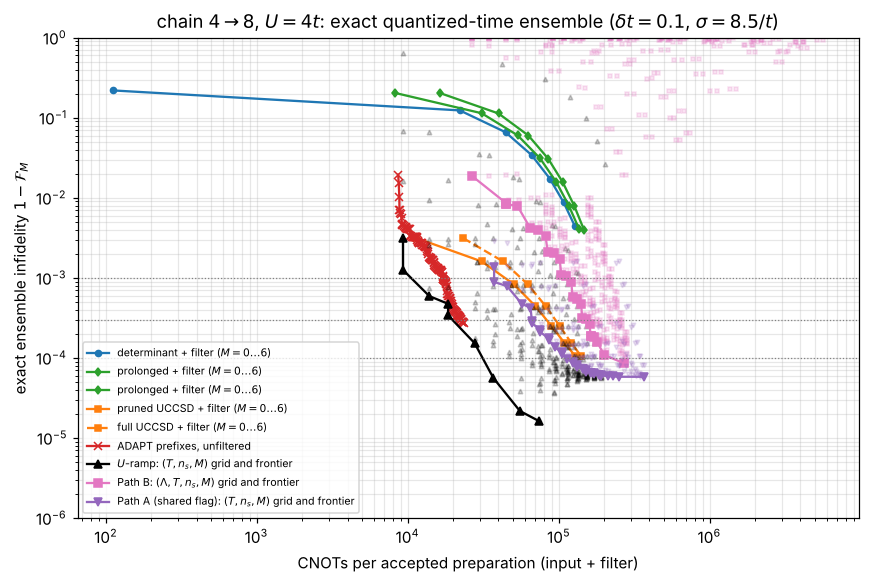

In [17]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

t0 = time.time()
U = 4.0; r = chain48[U]; Psih = r["Vf"][:, 0]; E0 = r["E_high"]
c2f = lambda s: np.cos(np.pi*s/2)**2; s2f = lambda s: np.sin(np.pi*s/2)**2
M_MAX = 6
# ---- (a) conventions after the revision
print("(a) conventions: controlled second-order step", hb.chain_step_cnots(8, hb.chain(8)[1], 2, controlled=True)["cnots"], "(8 sites),", hb.chain_step_cnots(16, hb.chain(16)[1], 2, controlled=True)["cnots"], "(16 sites) CNOTs (scalar single-Z sum absorbed; 352 / 736 before)")
for Nc_, nctl in ((4, 8), (8, 16)):
    d_ = hb.conditioned_term_cnots(Nc_, hb.chain(Nc_)[1], nctl)
    print(f"    Path-A coarse term {Nc_}->{2*Nc_}: {d_['rotations']} rotations; shared flag {d_['flag']} + frame {d_['frame']} = {d_['flag']+d_['frame']} CNOTs per application ({nctl-1} clean work qubits); per-rotation ladder {d_['toffoli']}; Gray code {d_['gray']}")
def cn_of(N_, ops): return hb.uccsd_cnots(N_, [l for l in ops if len(l) == 3], [l for l in ops if len(l) == 5])["total"]
for L_ in (4, 8, 16):
    pool_ = hb._uccsd_pool_kron(L_, hb.chain(L_)[1], 2, 2)
    print(f"    UCCSD template, {L_} sites: {cn_of(L_, pool_['labels'])} CNOTs (parity-support weights)")
cn_pr = cn_of(8, up["singles"] + up["doubles"]); cn_full = cn_of(8, ucc_fine[U]["singles"] + ucc_fine[U]["doubles"]); cn_pr16 = cn_of(16, up16["labels"])
print(f"    pruned UCCSD 8 sites ({up['n_params']} par.) {cn_pr}; full {cn_full}; pruned 16 sites ({up16['n_params']} par.) {cn_pr16}")

# ---- (b) the actual coarse states of the 4->8 hierarchy: four-site U-ramps from the free-fermion determinant
#      (two options, both prolonged and transported, so that the joint search can trade coarse accuracy against filter cycles)
N4, b4 = hb.chain(4); H4, _ = hb.H_hubbard(4, b4, 2, 2, U); w4, V4 = np.linalg.eigh(H4.toarray()); GS4 = V4[:, 0]
FF4 = np.linalg.eigh(hb.H_hubbard(4, b4, 2, 2, 0.0)[0].toarray())[1][:, 0]
K4e, K4o, D4 = [t_.toarray() for t_ in hb.hubbard_terms(4, b4, 2, 2, U)]
g4 = [K4e, K4o, D4]; c4 = [lambda s: 1.0, lambda s: 1.0, s2f]
st4 = hb.chain_step_cnots(4, b4, 2)["cnots"]; CN_GIVENS4 = 2*(4*3//2)*2
grid4 = {}
for T4 in (8, 12, 16, 24):
    for ns4 in (32, 64, 128, 256, 512):
        psi4 = hb.trotter_refine(FF4, g4, c4, float(T4), ns4, order=2); grid4[(T4, ns4)] = dict(T=T4, ns=ns4, psi=psi4, inf=1 - abs(np.vdot(GS4, psi4))**2, cost=CN_GIVENS4 + ns4*st4)
coarse4 = {}
for tag, thr in (("c", 1e-4), ("a", 2e-5)):
    coarse4[tag] = min((d for d in grid4.values() if d["inf"] < thr), key=lambda d: d["cost"])
    print(f"(b) four-site coarse state '{tag}' (cheapest ramp below {thr:.0e}): T={coarse4[tag]['T']}, n_s={coarse4[tag]['ns']}: 1-F = {coarse4[tag]['inf']:.1e}, {coarse4[tag]['cost']} CNOTs (Givens {CN_GIVENS4} + {coarse4[tag]['ns']} x {st4})")
    v = r["P"] @ coarse4[tag]["psi"]; coarse4[tag]["Phi0"] = v/np.linalg.norm(v); coarse4[tag]["cprep"] = coarse4[tag]["cost"] + CN_PROL
    print(f"    prolonged: p0 = {abs(np.vdot(Psih, coarse4[tag]['Phi0']))**2:.6f} (exact coarse eigenstate {r['p0']:.6f})")

# ---- (c) eight sites: exact quantized-time ensemble, joint search
tr8 = hb.trotter_evolution(hb.hubbard_terms(8, hb.chain(8)[1], 2, 2, U), DT, order=2, target=Psih)
ct2 = hb.chain_step_cnots(8, hb.chain(8)[1], 2, controlled=True)["cnots"]
Kev, Kod, D = [t_.toarray() for t_ in hb.hubbard_terms(8, hb.chain(8)[1], 2, 2, U)]
mu = r["E_low"] + 2.0
tl, Ul, cst = hb.galerkin_params("chain", 1.0, U, 2 + 2)
Kc_e, Kc_o, Dc = [t_.toarray() for t_ in hb.hubbard_terms(4, b4, 2, 2, Ul, t=tl)]
gA = [r["P"] @ (Dc + (cst - mu)*np.eye(36)) @ r["P"].T, r["P"] @ Kc_e @ r["P"].T, r["P"] @ Kc_o @ r["P"].T, Kev, Kod, D - mu*np.eye(784)]; cA = [c2f]*3 + [s2f]*3
gR = [Kev, Kod, D]; cR = [lambda s: 1.0, lambda s: 1.0, s2f]
gB = [Kev, Kod, D]
caA = CA_FLAG
inputs8 = {"free-fermion determinant": (FF.astype(complex), CN_GIVENS, "determinant + filter"),
           "prolonged (coarse c)": (coarse4["c"]["Phi0"].astype(complex), coarse4["c"]["cprep"], "prolonged + filter"),
           "prolonged (coarse a)": (coarse4["a"]["Phi0"].astype(complex), coarse4["a"]["cprep"], "prolonged + filter"),
           f"UCCSD pruned ({up['n_params']} par.)": (up["psi"].astype(complex), cn_pr, "pruned UCCSD + filter"),
           "UCCSD full (198 par.)": (ucc_fine[U]["psi"].astype(complex), cn_full, "full UCCSD + filter")}
for d_ in h8:
    if d_["n_ops"] > 0 and d_["infidelity"] < 2e-2:
        inputs8[f"ADAPT {d_['n_ops']} op."] = (d_["psi"].astype(complex), cn_of(8, ad8["ops"][:d_["n_ops"]]), "ADAPT (+ filter)")
for T in (8, 12, 16, 24, 32, 48):
    for ns in (64, 96, 128, 192, 256, 384, 512):
        inputs8[f"ramp T={T} n_s={ns}"] = (hb.trotter_refine(FF, gR, cR, float(T), ns, order=2), CN_GIVENS + ns*st2, "U-ramp (grid)")
for tag in ("c", "a"):
    Phi0_act, CN_COARSE4 = coarse4[tag]["Phi0"], coarse4[tag]["cprep"]
    for Lam in (8.0, 16.0, 32.0):
        cB = [lambda s, L=Lam: 1 + L*np.cos(np.pi*s/2)**2, lambda s: 1.0, lambda s: 1.0]
        for T in (16, 24, 32):
            for ns in (128, 256, 512, 1024):
                inputs8[f"Path B L={Lam:.0f} T={T} n_s={ns} ({tag})"] = (hb.trotter_refine(Phi0_act, gB, cB, float(T), ns, order=2), CN_COARSE4 + ns*st2, "Path B (grid)")
    for T in (8, 12, 16):
        for ns in (64, 128, 256, 512):
            inputs8[f"Path A T={T} n_s={ns} ({tag})"] = (hb.trotter_refine(Phi0_act, gA, cA, float(T), ns, order=2), CN_COARSE4 + ns*(st2 + 2*caA), "Path A (grid)")
print(f"(c) eight sites: {len(inputs8)} inputs, exact quantized-time ensemble (dt={DT}, sigma={SIG:.2f}, E_obj=E_eff)   [{time.time()-t0:.0f} s]")
def evaluate8(inputs):
    rows = {}
    for name, (v0, cprep, route) in inputs.items():
        e = hb.exact_digital_ensemble(tr8, v0, Psih, SIG, M_MAX)
        ccyc = e["mean_steps"]*ct2
        reach = e["acc"][:-1]
        num = cprep + np.cumsum(reach*ccyc)
        rows[name] = dict(p=1-e["inf"][0], cprep=cprep, inf=e["inf"], acc=e["acc"], cacc=np.concatenate([[float(cprep)], num/e["acc"][1:]]), route=route)
    return rows, ccyc
rows8, ccyc8 = evaluate8(inputs8)
def minima(rows, targets, routes):
    out = {}
    for tgt in targets:
        best = {}
        for name, d in rows.items():
            ok = np.where(d["inf"] <= tgt)[0]
            if ok.size:
                m = ok[np.argmin(d["cacc"][ok])]
                if d["route"] not in best or d["cacc"][m] < best[d["route"]][0]: best[d["route"]] = (d["cacc"][m], name, int(m), d["inf"][m])
        out[tgt] = best
    print("    minimum CNOTs per accepted preparation (input, M) per route:")
    for route in routes:
        print(f"      {route:26s} " + " | ".join((f"{tgt:.0e}: {out[tgt][route][0]:.2e} [{out[tgt][route][1]}, M={out[tgt][route][2]}, {out[tgt][route][3]:.1e}]" if route in out[tgt] else f"{tgt:.0e}: -") for tgt in targets))
    return out
ROUTES8 = ["determinant + filter", "prolonged + filter", "full UCCSD + filter", "pruned UCCSD + filter", "ADAPT (+ filter)", "U-ramp (grid)", "Path B (grid)", "Path A (grid)"]
print(f"    cycle: {ccyc8:.0f} CNOTs on average ({ccyc8/ct2:.1f} controlled steps)")
print(f"    {'input':34s} {'p':>8s} {'C_prep':>7s} | 1-F_M, M=0..6 | P_6 | CNOTs per accepted, M=0..6")
for name, d in rows8.items():
    if d["route"] in ("U-ramp (grid)", "Path B (grid)", "Path A (grid)") and not any(d["inf"][m] <= 3e-4 for m in range(M_MAX+1)): continue
    print(f"    {name:34s} {d['p']:8.5f} {d['cprep']:7d} | " + " ".join(f"{x:.1e}" for x in d["inf"]) + f" | {d['acc'][-1]:.3f} | " + " ".join(f"{c:.1e}" for c in d["cacc"]))
mins8 = minima(rows8, (1e-3, 3e-4, 1e-4), ROUTES8)
print(f"    [{time.time()-t0:.0f} s]")

fig, ax = plt.subplots(figsize=(8, 5.4))
for route, mk, col in (("determinant + filter", "o-", "C0"), ("prolonged + filter", "d-", "C2"), ("pruned UCCSD + filter", "s-", "C1"), ("full UCCSD + filter", "s--", "C1")):
    for name, d in rows8.items():
        if d["route"] == route: ax.loglog(d["cacc"], np.maximum(d["inf"], 1e-7), mk, color=col, ms=4, label=route + " ($M=0\\ldots6$)")
ad_ = [(n, d) for n, d in rows8.items() if d["route"] == "ADAPT (+ filter)"]
ax.loglog([d["cprep"] for n, d in ad_], [d["inf"][0] for n, d in ad_], "x-", color="C3", ms=5, label="ADAPT prefixes, unfiltered")
for route, mk, col, lab in (("U-ramp (grid)", "^", "k", "$U$-ramp: $(T,n_s,M)$ grid and frontier"), ("Path B (grid)", "s", "C6", "Path B: $(\\Lambda,T,n_s,M)$ grid and frontier"), ("Path A (grid)", "v", "C4", "Path A (shared flag): $(T,n_s,M)$ grid and frontier")):
    pts = np.array([(d["cacc"][m], d["inf"][m]) for d in rows8.values() if d["route"] == route for m in range(M_MAX+1)])
    ax.loglog(pts[:, 0], np.maximum(pts[:, 1], 1e-7), mk, color=col, ms=3, alpha=0.2)
    order = np.argsort(pts[:, 0]); best = np.inf; fx, fy = [], []
    for i_ in order:
        if pts[i_, 1] < best: best = pts[i_, 1]; fx.append(pts[i_, 0]); fy.append(pts[i_, 1])
    ax.loglog(fx, np.maximum(fy, 1e-7), mk + "-", color=col, ms=5, label=lab)
for tgt in (1e-3, 3e-4, 1e-4): ax.axhline(tgt, color="gray", ls=":", lw=0.8)
ax.set_xlabel("CNOTs per accepted preparation (input + filter)"); ax.set_ylabel("exact ensemble infidelity $1-\\mathcal{F}_M$"); ax.set_ylim(1e-6, 1)
ax.set_title(f"chain $4\\to8$, $U=4t$: exact quantized-time ensemble ($\\delta t={DT}$, $\\sigma={SIG:.1f}/t$)"); ax.legend(fontsize=7, loc="lower left"); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


(d) coarse state 'c' for 8->16: the cheapest unfiltered eight-site route below 3e-04 is 'ramp T=16 n_s=192' (1-F = 1.78e-04, 27760 CNOTs); prolonged: p0 = 0.868869 (exact coarse eigenstate 0.869189)
(d) coarse state 'a' for 8->16: the cheapest unfiltered eight-site route below 1e-04 is 'ramp T=24 n_s=256' (1-F = 5.62e-05, 36976 CNOTs); prolonged: p0 = 0.868809 (exact coarse eigenstate 0.869189)
    ramps done   [26 s]
    47 inputs prepared   [101 s]
    free-fermion determinant           p=0.71624 prep=     480 | 2.8e-01( 0%) 1.7e-01( 3%) 8.9e-02( 4%) 5.0e-02( 6%) 2.5e-02( 7%) 1.4e-02(10%) 7.4e-03(14%) | acc(6) 0.717 | cost 4.8e+02 1.9e+05 4.1e+05 6.2e+05 8.4e+05 1.0e+06 1.2e+06   [350 s]
    prolonged (coarse c)               p=0.86887 prep=   27792 | 1.3e-01( 0%) 7.1e-02( 3%) 3.7e-02( 4%) 1.8e-02( 7%) 9.8e-03(11%) 4.6e-03( 9%) 2.3e-03(10%) | acc(6) 0.870 | cost 2.8e+04 2.0e+05 4.0e+05 6.0e+05 8.1e+05 9.9e+05 1.1e+06   [602 s]
    prolonged (coarse a)               p=0.86881 prep=   

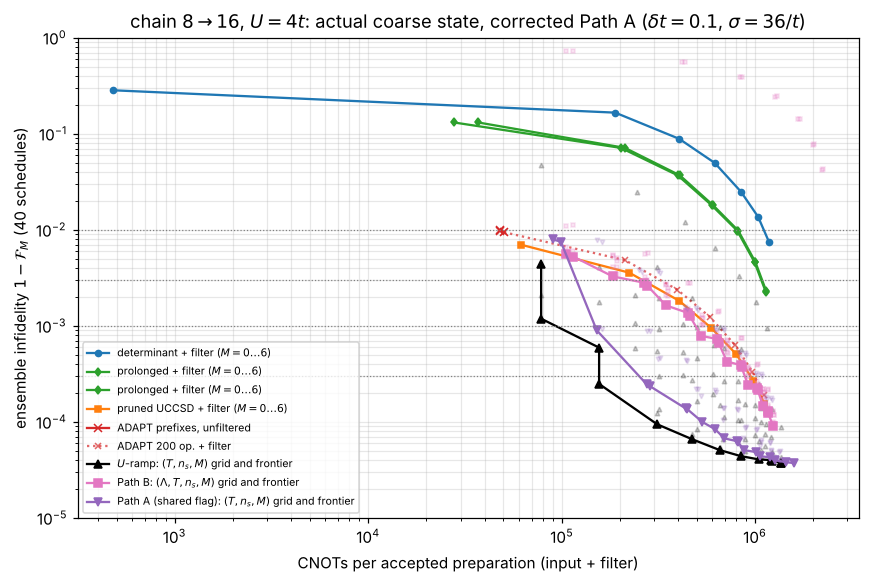

In [18]:
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb

# ---- (d) sixteen sites: the actual coarse state (cheapest eight-site route below 1e-4), corrected Path A, shared-flag costs, joint search (40 schedules)
t0 = time.time()
U = 4.0
coarse8 = {}
for tag, thr in (("c", 3e-4), ("a", 1e-4)):
    ok8 = [(d["cacc"][0], n) for n, d in rows8.items() if d["route"] == "U-ramp (grid)" and d["inf"][0] <= thr]
    c8cost, c8name = min(ok8); v = P16 @ inputs8[c8name][0]
    coarse8[tag] = dict(name=c8name, inf=rows8[c8name]["inf"][0], cost=c8cost, Phi0=np.asarray(v, complex)/np.linalg.norm(v), cprep=int(c8cost) + CN_PROL16)
    print(f"(d) coarse state '{tag}' for 8->16: the cheapest unfiltered eight-site route below {thr:.0e} is '{c8name}' (1-F = {coarse8[tag]['inf']:.2e}, {c8cost:.0f} CNOTs); prolonged: p0 = {abs(np.vdot(GS16, coarse8[tag]['Phi0']))**2:.6f} (exact coarse eigenstate {abs(np.vdot(GS16, Phi016))**2:.6f})")
st16 = hb.chain_step_cnots(Nf, bf, 2)["cnots"]; ct16 = hb.chain_step_cnots(Nf, bf, 2, controlled=True)["cnots"]
ca16d = hb.conditioned_term_cnots(8, bc, n_controls=16); ca16 = ca16d["flag"] + ca16d["frame"]
inputs16 = {"free-fermion determinant": (FF16.astype(complex), CN_GIVENS16, "determinant + filter"),
            "prolonged (coarse c)": (coarse8["c"]["Phi0"], coarse8["c"]["cprep"], "prolonged + filter"),
            "prolonged (coarse a)": (coarse8["a"]["Phi0"], coarse8["a"]["cprep"], "prolonged + filter"),
            f"UCCSD pruned ({up16['n_params']} par.)": (np.asarray(up16["psi"], complex), cn_pr16, "pruned UCCSD + filter")}
for d_ in h16:
    if d_["n_ops"] > 0 and d_["infidelity"] <= 1.2e-2 and (d_["n_ops"] % 10 == 0 or d_ is reach16[1e-2] or d_ is h16[-1]):
        inputs16[f"ADAPT {d_['n_ops']} op."] = (np.asarray(d_["psi"], complex), cn_of(Nf, ad16["ops"][:d_["n_ops"]]), "ADAPT (+ filter)")
ramp_coefs = [lambda s: 1.0, lambda s: 1.0, s2f]
for T in (32, 48, 64, 128):
    for ns in (256, 512, 1024):
        inputs16[f"ramp T={T} n_s={ns}"] = (hb.trotter_path_groups(FF16, groups16, ramp_coefs, float(T), ns), CN_GIVENS16 + ns*st16, "U-ramp (grid)")
print(f"    ramps done   [{time.time()-t0:.0f} s]")
for tag in ("c", "a"):
    Phi0_16act, CN_COARSE16 = coarse8[tag]["Phi0"], coarse8[tag]["cprep"]
    for Lam in (8.0, 16.0):
        cB16 = [lambda s, L=Lam: 1 + L*np.cos(np.pi*s/2)**2, lambda s: 1.0, lambda s: 1.0]
        for T in (16, 32):
            for ns in (256, 512):
                inputs16[f"Path B L={Lam:.0f} T={T} n_s={ns} ({tag})"] = (hb.trotter_path_groups(Phi0_16act, gB16, cB16, float(T), ns), CN_COARSE16 + ns*st16, "Path B (grid)")
    for T, ns in ((8, 64), (8, 128), (16, 128), (16, 256), (32, 256), (32, 512)):
        inputs16[f"Path A T={T} n_s={ns} ({tag})"] = (hb.trotter_path_groups(Phi0_16act, gA16, cA16, float(T), ns), CN_COARSE16 + ns*(st16 + 2*ca16), "Path A (grid)")
print(f"    {len(inputs16)} inputs prepared   [{time.time()-t0:.0f} s]")
NS16B = 40
rng = np.random.default_rng(SEED); tsets16b = [np.abs(rng.normal(0.0, SIG16, M_MAX)) for _ in range(NS16B)]
cyc16b = np.array([[max(1, int(round(t/DT16)))*ct16 for t in ts] for ts in tsets16b])
rows16b = {}; rngb = np.random.default_rng(5)
for name, (v0, cprep, route) in inputs16.items():
    p = abs(np.vdot(GS16, v0))**2
    F = np.zeros((NS16B, M_MAX)); Acc = np.zeros((NS16B, M_MAX))
    for s_, ts in enumerate(tsets16b): F[s_], Acc[s_] = hb.rodeo_track_groups(v0, groups16, ts, E_eff16, GS16, DT16)
    Fw = (F*Acc).sum(0)/Acc.sum(0); Am = Acc.mean(0)
    boots = np.array([1 - ((F*Acc)[idx].sum(0)/Acc[idx].sum(0)) for idx in (rngb.integers(0, NS16B, NS16B) for _ in range(400))]); rse = boots.std(0)/np.maximum(1-Fw, 1e-30)
    reach_ = np.concatenate([np.ones((NS16B, 1)), Acc[:, :-1]], axis=1)
    rows16b[name] = dict(p=p, cprep=cprep, inf=np.concatenate([[1-p], 1-Fw]), rse=np.concatenate([[0], rse]), acc=np.concatenate([[1], Am]), cacc=np.concatenate([[float(cprep)], (cprep + np.cumsum(reach_*cyc16b, axis=1).mean(0))/Am]), route=route, F=F, Acc=Acc)
    print(f"    {name:34s} p={p:.5f} prep={cprep:8d} | " + " ".join(f"{rows16b[name]['inf'][m]:.1e}({100*rows16b[name]['rse'][m]:2.0f}%)" for m in range(M_MAX+1)) + f" | acc(6) {Am[-1]:.3f} | cost " + " ".join(f"{c:.1e}" for c in rows16b[name]["cacc"]) + f"   [{time.time()-t0:.0f} s]")
print(f"    cycle: {cyc16b.mean():.0f} CNOTs on average; {NS16B} shared time sets, bootstrap relative standard errors in brackets")
ROUTES16 = ["determinant + filter", "prolonged + filter", "pruned UCCSD + filter", "ADAPT (+ filter)", "U-ramp (grid)", "Path B (grid)", "Path A (grid)"]
mins16 = minima(rows16b, (1e-2, 3e-3, 1e-3, 3e-4), ROUTES16)
# the decision uncertainty: bootstrap the minimum-cost operating point of each route at each target over the shared schedules
print("    bootstrap of the operating-point selection over the shared schedules (400 resamples): fraction of resamples in which the listed (input, M) stays the cheapest of its route, and the 5-95% range of the route's minimum cost")
rngb = np.random.default_rng(17)
for tgt in (1e-2, 3e-3, 1e-3, 3e-4):
    line = []
    for route in ROUTES16:
        if route not in mins16[tgt]: continue
        c0, name0, m0, _ = mins16[tgt][route]; same = 0; costs = []
        for _ in range(400):
            idx = rngb.integers(0, NS16B, NS16B); bestc, bestk = np.inf, None
            for name, d in rows16b.items():
                if d["route"] != route: continue
                F, Acc = d["F"][idx], d["Acc"][idx]; Fw = (F*Acc).sum(0)/Acc.sum(0); Am = Acc.mean(0)
                inf = np.concatenate([[d["inf"][0]], 1-Fw]); reach_ = np.concatenate([np.ones((NS16B, 1)), Acc[:, :-1]], axis=1)
                cacc = np.concatenate([[float(d["cprep"])], (d["cprep"] + np.cumsum(reach_*cyc16b[idx], axis=1).mean(0))/Am])
                ok = np.where(inf <= tgt)[0]
                if ok.size:
                    m = ok[np.argmin(cacc[ok])]
                    if cacc[m] < bestc: bestc, bestk = cacc[m], (name, int(m))
            if bestk == (name0, m0): same += 1
            if bestk is not None: costs.append(bestc)
        line.append(f"{route}: {100*same/400:.0f}%, [{np.percentile(costs, 5):.1e}, {np.percentile(costs, 95):.1e}]" if costs else f"{route}: -")
    print(f"      {tgt:.0e}: " + "; ".join(line))
print(f"    [{time.time()-t0:.0f} s]")

fig, ax = plt.subplots(figsize=(8, 5.4))
for route, mk, col in (("determinant + filter", "o-", "C0"), ("prolonged + filter", "d-", "C2"), ("pruned UCCSD + filter", "s-", "C1")):
    for name, d in rows16b.items():
        if d["route"] == route: ax.loglog(d["cacc"], np.maximum(d["inf"], 1e-7), mk, color=col, ms=4, label=route + " ($M=0\\ldots6$)")
ad_ = [(n, d) for n, d in rows16b.items() if d["route"] == "ADAPT (+ filter)"]
ax.loglog([d["cprep"] for n, d in ad_], [d["inf"][0] for n, d in ad_], "x-", color="C3", ms=5, label="ADAPT prefixes, unfiltered")
for n, d in ad_[-1:]: ax.loglog(d["cacc"], d["inf"], "x:", color="C3", ms=4, alpha=0.7, label=f"{n} + filter")
for route, mk, col, lab in (("U-ramp (grid)", "^", "k", "$U$-ramp: $(T,n_s,M)$ grid and frontier"), ("Path B (grid)", "s", "C6", "Path B: $(\\Lambda,T,n_s,M)$ grid and frontier"), ("Path A (grid)", "v", "C4", "Path A (shared flag): $(T,n_s,M)$ grid and frontier")):
    pts = np.array([(d["cacc"][m], d["inf"][m]) for d in rows16b.values() if d["route"] == route for m in range(M_MAX+1)])
    ax.loglog(pts[:, 0], np.maximum(pts[:, 1], 1e-7), mk, color=col, ms=3, alpha=0.2)
    order = np.argsort(pts[:, 0]); best = np.inf; fx, fy = [], []
    for i_ in order:
        if pts[i_, 1] < best: best = pts[i_, 1]; fx.append(pts[i_, 0]); fy.append(pts[i_, 1])
    ax.loglog(fx, np.maximum(fy, 1e-7), mk + "-", color=col, ms=5, label=lab)
for tgt in (1e-2, 3e-3, 1e-3, 3e-4): ax.axhline(tgt, color="gray", ls=":", lw=0.8)
ax.set_xlabel("CNOTs per accepted preparation (input + filter)"); ax.set_ylabel("ensemble infidelity $1-\\mathcal{F}_M$ (40 schedules)"); ax.set_ylim(1e-5, 1)
ax.set_title(f"chain $8\\to16$, $U=4t$: actual coarse state, corrected Path A ($\\delta t={DT16}$, $\\sigma={SIG16:.0f}/t$)"); ax.legend(fontsize=7, loc="lower left"); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


<!-- EXT:HREFINE -->
---
## 14&nbsp; Convergence of the operating-point search

The joint search of Section 13 used coarse control grids (ramp $T\in\{8,\ldots,48\}/t$ in steps of
$4$--$16$ with $n_s\in\{64,\ldots,512\}$ at eight sites; $T\in\{32,48,64,128\}/t$ and
$n_s\in\{256,512,1024\}$ at sixteen).  The final pre-submission pass of 21 October 2026 (the same
checklist as `paper/morefeedback.md` for paper I) asks how far those minima are from converged.
Here the ramp and Path A (shared-flag coarse term, actual propagated coarse state) are searched on
fine grids of $T$ (steps of $1$--$2/t$ at eight sites, $2$--$4/t$ at sixteen), Path B on a finer
$T$ grid as well, with the step count on a geometric list (ratio $1.15$) and then located to the
integer by bracketing and bisection at every target; at eight sites every cycle number
$M=0,\ldots,6$ is evaluated with the exact quantized-time ensemble (`hb.exact_digital_ensemble`,
now with a cached $Q$), at sixteen sites the refinement is restricted to $M=0$, which is complete
for the ramp and Path A because one average filter cycle alone ($1.8\times10^5$ CNOTs) costs more
than their unfiltered minima at every target (checked in the output).  The coarse state of the
$8\to16$ hierarchy is re-selected as the cheapest *refined* eight-site unfiltered ramp below
$3\times10^{-4}$ ('c') and below $10^{-4}$ ('a').  Three search levels are reported per route and
target --- L0 (the Section-13 grid), L1 (fine grid, geometric $n_s$), L2 (L1 + integer $n_s$) ---
with the number of distinct controls within $10\%$ of the minimum and the Path-A/ramp ratio.
Figure 15 draws the cost frontiers; these are the numbers of Tables 2 and 3 and of Table S7 of
paper III.  The cell is self-contained (it rebuilds its inputs from `pairinglib.hubbard`), so it
can be re-executed on its own with `scripts/run_new_cells.py --nb notebooks/ResolutionRefHubbard.ipynb --mark "<!-- EXT:HREFINE -->"`.

chain 4->8, (2,2), U=4: E0 = -5.634427, D_eff = 0.5879, sigma = 8.51/t, dt = 0.1, E_eff - E0 = +1.35e-02, floor 5.8e-05; step 144 CNOTs (controlled 288), cycle 19545 CNOTs on average; Givens 112, prolongation 16, Path-A coarse term 156 (shared flag + frame)   [2 s]
  four-site coarse state 'c': ramp T=8, n_s=128, 1-F = 6.7e-05, 8232 CNOTs incl. prolongation; prolonged p0 = 0.79535
  four-site coarse state 'a': ramp T=12, n_s=256, 1-F = 1.4e-05, 16424 CNOTs incl. prolongation; prolonged p0 = 0.79666
    U-ramp control None: T grid 6..48, 24 step counts   [3 s]
  U-ramp: 7224 grid points evaluated   [71 s]
    Path A control c: T grid 6..24, 24 step counts   [71 s]
    Path A control a: T grid 6..24, 24 step counts   [117 s]
  Path A: 6384 grid points evaluated   [187 s]
    Path B control (8.0, 'c'): T grid 12..32, 21 step counts   [187 s]
    Path B control (8.0, 'a'): T grid 12..32, 21 step counts   [207 s]
    Path B control (16.0, 'c'): T grid 12..32, 21 step counts   [226 s]
    Pa

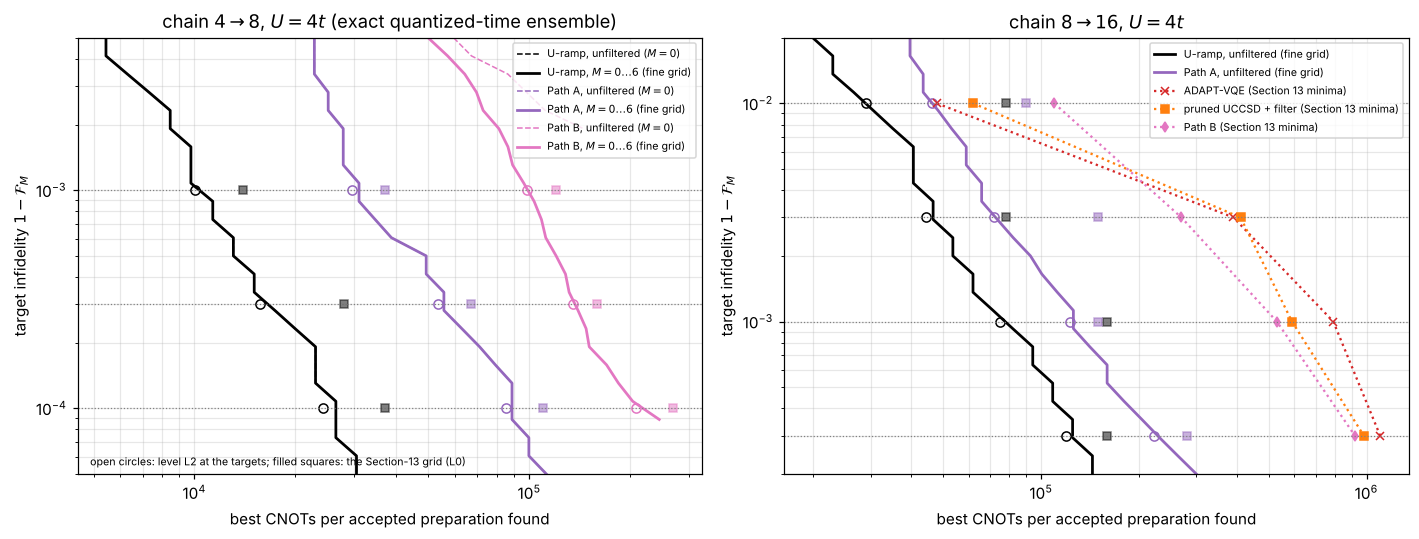

In [19]:
# <!-- EXT:HREFINE -->
import numpy as np, matplotlib.pyplot as plt, time
from math import comb
try:
    import pairinglib as pl
except ModuleNotFoundError:
    import sys, pathlib
    sys.path.insert(0, str((pathlib.Path.cwd()/".."/"src").resolve()))
    import pairinglib as pl
import pairinglib.hubbard as hb
import sys as _sys, os, time, json
import matplotlib
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import eigsh

OUT = _sys.argv[1] if len(_sys.argv) > 1 and not _sys.argv[1].startswith("-") else None   # None inside a notebook kernel
if OUT: matplotlib.use("Agg")
t0 = time.time()
c2f = lambda s: np.cos(np.pi * s / 2) ** 2
s2f = lambda s: np.sin(np.pi * s / 2) ** 2
U = 4.0
M_MAX = 6
RATIO = 1.15
TGT8 = (1e-3, 3e-4, 1e-4)
TGT16 = (1e-2, 3e-3, 1e-3, 3e-4)
# the minima of the Section-13 grids (paper III Tables 2 and 3 of 2026-10-20): level L0
L0 = {"8": {"U-ramp": (1.4e4, 2.8e4, 3.7e4), "Path A": (3.7e4, 6.7e4, 1.1e5), "Path B": (1.2e5, 1.6e5, 2.7e5)},
      "16": {"U-ramp": (7.8e4, 7.8e4, 1.6e5, 1.6e5), "Path A": (9.0e4, 1.5e5, 1.5e5, 2.8e5)}}
# the other rows of Table 3 (sixteen sites, 40 schedules; unchanged by this pass), for the figure
T3_OTHER = {"ADAPT-VQE": (4.8e4, 3.9e5, 7.9e5, 1.1e6), "pruned UCCSD + filter": (6.2e4, 4.1e5, 5.9e5, 9.8e5),
            "Path B": (1.1e5, 2.7e5, 5.3e5, 9.2e5)}


def geometric(lo, hi, ratio=RATIO):
    out = [lo]
    while out[-1] < hi:
        out.append(max(out[-1] + 1, int(np.ceil(out[-1] * ratio))))
    return out


class Route:
    """One adiabatic route: per control value a (Phi0, groups, coefs, extra cost) path; a cache of states."""
    def __init__(self, name, step_cnots, GS, path_fn):
        self.name, self.step, self.GS, self.path_fn = name, step_cnots, GS, path_fn
        self.cache = {}

    def state(self, ctrl, T, ns):
        key = (ctrl, float(T), int(ns))
        if key not in self.cache:
            self.cache[key] = self.path_fn(ctrl, float(T), int(ns))
        return self.cache[key]

    def inf0(self, ctrl, T, ns):
        return 1 - abs(np.vdot(self.GS, self.state(ctrl, T, ns))) ** 2

    def cprep(self, ctrl, ns):
        return self.extra(ctrl) + int(ns) * self.step

    def cost(self, ctrl, ns, M, acc, ccyc, reach):
        cp = self.cprep(ctrl, ns)
        return float(cp) if M == 0 else (cp + float(np.sum(reach[:M]) * ccyc)) / acc[M]


def min_steps(route, ctrl, T, target, M, ens, ns_lo, ns_hi):
    """Smallest n_s in [ns_lo, ns_hi] (bracketing by RATIO, then bisection) whose infidelity after M cycles
    is <= target; ens(psi) -> (inf array, acc array) or None for M=0.  Returns (n_s, inf, acc, reach) or None."""
    def ev(ns):
        if M == 0:
            return route.inf0(ctrl, T, ns), None, None
        e = ens(route.state(ctrl, T, ns))
        return e["inf"][M], e["acc"], e["acc"][:-1]
    lo, hi, ns = None, None, ns_lo
    while ns <= ns_hi:
        i, a, r_ = ev(ns)
        if i <= target:
            hi = (ns, i, a, r_); break
        lo = ns; ns = max(ns + 1, int(np.ceil(ns * RATIO)))
    if hi is None:
        return None
    if lo is None:
        return hi
    while hi[0] - lo > 1:
        mid = (lo + hi[0]) // 2
        i, a, r_ = ev(mid)
        if i <= target: hi = (mid, i, a, r_)
        else: lo = mid
    return hi


def levels(route, ctrls, Tgrid, ns_list, targets, ens, ccyc, Ms):
    """L1 cloud over (ctrl, T, n_s, M) and the L2 integer refinement at the targets."""
    cloud = []
    for ctrl in ctrls:
        print(f"    {route.name} control {ctrl}: T grid {Tgrid[0]:g}..{Tgrid[-1]:g}, {len(ns_list)} step counts   [{time.time()-t0:.0f} s]", flush=True)
        for T in Tgrid:
            for ns in ns_list:
                psi = route.state(ctrl, T, ns)
                if ens is None or Ms == (0,):
                    cloud.append((ctrl, T, ns, 0, route.inf0(ctrl, T, ns), float(route.cprep(ctrl, ns))))
                else:
                    e = ens(psi); reach = e["acc"][:-1]
                    for M in Ms:
                        cloud.append((ctrl, T, ns, M, e["inf"][M], route.cost(ctrl, ns, M, e["acc"], ccyc, reach)))
    res = {}
    for tgt in targets:
        ok = [p for p in cloud if p[4] <= tgt]
        if not ok:
            res[tgt] = None; continue
        best1 = min(ok, key=lambda p: p[5])
        per = {}
        for p in ok:
            k = (p[0], p[1], p[3])
            if k not in per or p[5] < per[k][5]: per[k] = p
        refined = []
        for p in sorted(per.values(), key=lambda p: p[5]):
            if p[5] > 1.4 * best1[5]: break
            ctrl, T, ns, M = p[0], p[1], p[2], p[3]
            hit = min_steps(route, ctrl, T, tgt, M, ens, max(ns_list[0], int(ns / RATIO)), ns)
            if hit is not None:
                refined.append((ctrl, T, hit[0], M, hit[1], route.cost(ctrl, hit[0], M, hit[2], ccyc, hit[3])))
        best2 = min(refined, key=lambda p: p[5])
        perc = {}
        for p in refined:
            k = (p[0], p[1])
            if k not in perc or p[5] < perc[k]: perc[k] = p[5]
        flat = [k for k, v in perc.items() if v <= 1.10 * best2[5]]
        res[tgt] = dict(L1=best1, L2=best2, flat=flat)
    return cloud, res


def fmt(p, route):
    ctrl, T, ns, M = p[0], p[1], p[2], p[3]
    if route == "U-ramp": return f"({T:g}, {ns}, {M})"
    if route == "Path A": return f"({T:g}, {ns}, {M}; {ctrl})"
    return f"({ctrl[0]:g}, {T:g}, {ns}, {M}; {ctrl[1]})"


def report(label, key, results, targets, ratio_pair=("Path A", "U-ramp")):
    print(f"\n{label}: best CNOTs per accepted preparation found at three search levels")
    print(f"  {'route':8s} {'target':>7s} | {'L0 Sec.13 grid':>14s} | {'L1 fine grid':>12s} {'point':>22s} | {'L2 +integer':>12s} {'point':>22s} | 1-F | controls within 10%")
    for route, res in results.items():
        for j, tgt in enumerate(targets):
            r_ = res[tgt]
            l0 = L0[key][route][j] if route in L0[key] else float("nan")
            if r_ is None:
                print(f"  {route:8s} {tgt:7.0e} | {l0:14.2e} | not reached"); continue
            fl = r_["flat"]; Ts = sorted(set(k[1] for k in fl))
            print(f"  {route:8s} {tgt:7.0e} | {l0:14.2e} | {r_['L1'][5]:12.4e} {fmt(r_['L1'], route):>22s} | {r_['L2'][5]:12.4e} {fmt(r_['L2'], route):>22s} | {r_['L2'][4]:.2e} | {len(fl)} (T = {Ts[0]:g}..{Ts[-1]:g})")
    a, b = ratio_pair
    print(f"  ratio {a} / {b} at the targets (L2): " + ", ".join(f"{tgt:.0e}: {results[a][tgt]['L2'][5]/results[b][tgt]['L2'][5]:.3f}" if results[a][tgt] and results[b][tgt] else f"{tgt:.0e}: -" for tgt in targets))
    print("  change L0 -> L2: " + ", ".join(f"{route} {tgt:.0e}: {100*(res[tgt]['L2'][5]/L0[key][route][j]-1):+.0f}%" for route, res in results.items() if route in L0[key] for j, tgt in enumerate(targets) if res[tgt]))


def frontier(cloud, tgts, Ms=None):
    return np.array([min((p[5] for p in cloud if p[4] <= tgt and (Ms is None or p[3] in Ms)), default=np.nan) for tgt in tgts])


# ============================================================ eight sites: chain 4 -> 8, (2,2), U = 4t, exact quantized-time ensemble
(Nc, bc), (Nf, bf), blocks, intra = hb.refine_chain(4)
Hf, _ = hb.H_hubbard(Nf, bf, 2, 2, U); Hd = Hf.toarray(); wf, Vf = np.linalg.eigh(Hd); Psih = Vf[:, 0]; E0 = wf[0]
P = hb.prolong(Nc, Nf, blocks, 2, 2); ps = hb.prolonged_state(Hf, P); El, Phi0ex = ps["El"], ps["Phi0"]
Deff, _ = hb.effective_gap(Phi0ex, wf, Vf); SIG = 5.0 / Deff; DT = 0.1
FF = np.linalg.eigh(hb.H_hubbard(Nf, bf, 2, 2, 0.0)[0].toarray())[1][:, 0]
terms = hb.hubbard_terms(Nf, bf, 2, 2, U); Kev, Kod, D = [t_.toarray() for t_ in terms]
tr8 = hb.trotter_evolution(terms, DT, order=2, target=Psih); E_eff = tr8["E_eff"]
st2 = hb.chain_step_cnots(Nf, bf, 2)["cnots"]; ct2 = hb.chain_step_cnots(Nf, bf, 2, controlled=True)["cnots"]
ca8 = hb.conditioned_term_cnots(Nc, bc, n_controls=8); CA_FLAG = ca8["flag"] + ca8["frame"]
CN_GIVENS = 2 * (Nf * (Nf - 1) // 2) * 2; CN_PROL = 2 * Nc * 2
cache8 = {}
ens8 = lambda psi: hb.exact_digital_ensemble(tr8, psi, Psih, SIG, M_MAX, cache=cache8)
e_ = ens8(FF.astype(complex)); ccyc8 = cache8["ns"] @ cache8["wn"] * ct2
print(f"chain 4->8, (2,2), U={U:.0f}: E0 = {E0:.6f}, D_eff = {Deff:.4f}, sigma = {SIG:.2f}/t, dt = {DT}, E_eff - E0 = {E_eff-E0:+.2e}, floor {tr8['floor']:.1e}; "
      f"step {st2} CNOTs (controlled {ct2}), cycle {ccyc8:.0f} CNOTs on average; Givens {CN_GIVENS}, prolongation {CN_PROL}, Path-A coarse term {CA_FLAG} (shared flag + frame)   [{time.time()-t0:.0f} s]")

# the actual four-site coarse states (as in Section 13: the cheapest four-site ramp below 1e-4 ('c') and 2e-5 ('a') on its grid)
N4, b4 = hb.chain(4); H4 = hb.H_hubbard(4, b4, 2, 2, U)[0].toarray(); GS4 = np.linalg.eigh(H4)[1][:, 0]
FF4 = np.linalg.eigh(hb.H_hubbard(4, b4, 2, 2, 0.0)[0].toarray())[1][:, 0]
g4 = [t_.toarray() for t_ in hb.hubbard_terms(4, b4, 2, 2, U)]; c4 = [lambda s: 1.0, lambda s: 1.0, s2f]
st4 = hb.chain_step_cnots(4, b4, 2)["cnots"]; CN_GIVENS4 = 2 * (4 * 3 // 2) * 2
grid4 = {}
for T4 in (8, 12, 16, 24):
    for ns4 in (32, 64, 128, 256, 512):
        psi4 = hb.trotter_refine(FF4, g4, c4, float(T4), ns4, order=2)
        grid4[(T4, ns4)] = dict(psi=psi4, inf=1 - abs(np.vdot(GS4, psi4)) ** 2, cost=CN_GIVENS4 + ns4 * st4)
coarse4 = {}
for tag, thr in (("c", 1e-4), ("a", 2e-5)):
    k4 = min((k for k, d in grid4.items() if d["inf"] < thr), key=lambda k: grid4[k]["cost"])
    v = P @ grid4[k4]["psi"]; coarse4[tag] = dict(Phi0=(v / np.linalg.norm(v)).astype(complex), cprep=grid4[k4]["cost"] + CN_PROL, T=k4[0], ns=k4[1], inf=grid4[k4]["inf"])
    print(f"  four-site coarse state '{tag}': ramp T={k4[0]}, n_s={k4[1]}, 1-F = {grid4[k4]['inf']:.1e}, {coarse4[tag]['cprep']} CNOTs incl. prolongation; prolonged p0 = {abs(np.vdot(Psih, coarse4[tag]['Phi0']))**2:.5f}")

mu = El + 2.0
tl, Ul, cst = hb.galerkin_params("chain", 1.0, U, 2 + 2)
Kc_e, Kc_o, Dc = [t_.toarray() for t_ in hb.hubbard_terms(4, b4, 2, 2, Ul, t=tl)]
# the same product formulas as Section 13 (groups [K_even, K_odd, D], the coarse term through P X P^T) in the
# Kronecker form of `hb.hubbard_groups` / `hb.ProjGroup` (validated against the dense `trotter_refine` to 1e-15; 70x faster)
groups8 = hb.hubbard_groups(Nf, bf, 2, 2, U)
gA = [hb.ProjGroup(P, Dc + (cst - mu) * np.eye(36)), hb.ProjGroup(P, Kc_e), hb.ProjGroup(P, Kc_o), groups8[0], groups8[1], hb.DiagGroup(groups8[2].d - mu)]; cA = [c2f] * 3 + [s2f] * 3
cR = [lambda s: 1.0, lambda s: 1.0, s2f]
_chk = hb.trotter_refine(FF, [Kev, Kod, D], cR, 16.0, 64, order=2)
assert abs(abs(np.vdot(_chk, hb.trotter_path_groups(FF, groups8, cR, 16.0, 64))) - 1) < 1e-12, "Kronecker groups must reproduce the dense product formula"

ramp8 = Route("U-ramp", st2, Psih, lambda ctrl, T, ns: hb.trotter_path_groups(FF, groups8, cR, T, ns)); ramp8.extra = lambda ctrl: CN_GIVENS
pathA8 = Route("Path A", st2 + 2 * CA_FLAG, Psih, lambda ctrl, T, ns: hb.trotter_path_groups(coarse4[ctrl]["Phi0"], gA, cA, T, ns)); pathA8.extra = lambda ctrl: coarse4[ctrl]["cprep"]
def _pathB(ctrl, T, ns):
    Lam, tag = ctrl; cB = [lambda s, L=Lam: 1 + L * np.cos(np.pi * s / 2) ** 2, lambda s: 1.0, lambda s: 1.0]
    return hb.trotter_path_groups(coarse4[tag]["Phi0"], groups8, cB, T, ns)
pathB8 = Route("Path B", st2, Psih, _pathB); pathB8.extra = lambda ctrl: coarse4[ctrl[1]]["cprep"]

ns8 = geometric(32, 768)
Ms8 = tuple(range(M_MAX + 1))
cloudR8, resR8 = levels(ramp8, (None,), np.arange(6, 48.01, 1.0), ns8, TGT8, ens8, ccyc8, Ms8)
print(f"  U-ramp: {len(cloudR8)} grid points evaluated   [{time.time()-t0:.0f} s]")
cloudA8, resA8 = levels(pathA8, ("c", "a"), np.arange(6, 24.01, 1.0), ns8, TGT8, ens8, ccyc8, Ms8)
print(f"  Path A: {len(cloudA8)} grid points evaluated   [{time.time()-t0:.0f} s]")
cloudB8, resB8 = levels(pathB8, [(L, tag) for L in (8.0, 16.0, 32.0) for tag in ("c", "a")], np.arange(12, 32.01, 2.0), geometric(64, 1024), TGT8, ens8, ccyc8, Ms8)
print(f"  Path B: {len(cloudB8)} grid points evaluated   [{time.time()-t0:.0f} s]")
res8 = {"U-ramp": resR8, "Path A": resA8, "Path B": resB8}
report("chain 4->8 (sixteen qubits), exact quantized-time ensemble", "8", res8, TGT8)
print(f"  [{time.time()-t0:.0f} s]")

# ============================================================ sixteen sites: chain 8 -> 16, (2,2), U = 4t, unfiltered (M = 0) refinement
(Nc16, bc16), (Nf16, bf16), blocks16, intra16 = hb.refine_chain(8)
Hf16, _ = hb.H_hubbard(Nf16, bf16, 2, 2, U)
w16, V16 = eigsh(Hf16, k=4, which="SA", tol=1e-10); o = np.argsort(w16); w16, V16 = w16[o], V16[:, o]; GS16 = V16[:, 0]
P16 = hb.prolong(Nc16, Nf16, blocks16, 2, 2, sparse=True); ps16 = hb.prolonged_state(Hf16, P16); Hl16, El16 = ps16["Hl"], ps16["El"]
pool16 = hb._uccsd_pool_kron(Nf16, bf16, 2, 2); FF16 = hb._to_site(pool16, pool16["ref"]).real
groups16 = hb.hubbard_groups(Nf16, bf16, 2, 2, U)
st16 = hb.chain_step_cnots(Nf16, bf16, 2)["cnots"]; ct16 = hb.chain_step_cnots(Nf16, bf16, 2, controlled=True)["cnots"]
ca16d = hb.conditioned_term_cnots(8, bc16, n_controls=16); ca16 = ca16d["flag"] + ca16d["frame"]; CN_GIVENS16 = 2 * (Nf16 * (Nf16 - 1) // 2) * 2; CN_PROL16 = 2 * 8 * 2
SIG16 = 5.0 / hb.effective_gap(ps16["Phi0"], w16, V16)[0]; DT16 = 0.1
nq, wq = hb.quantized_step_distribution(SIG16, DT16); ccyc16 = float(nq @ wq) * ct16
print(f"\nchain 8->16, (2,2), U={U:.0f}: E0 = {w16[0]:.6f}; step {st16} CNOTs (controlled {ct16}), Path-A coarse term {ca16} per application, Givens {CN_GIVENS16}, prolongation {CN_PROL16}; "
      f"sigma = {SIG16:.1f}/t, dt = {DT16}: a cycle costs {ccyc16:.3e} CNOTs on average   [{time.time()-t0:.0f} s]")
# the coarse state: the cheapest REFINED eight-site unfiltered ramp below 3e-4 ('c') and 1e-4 ('a')
coarse8 = {}
for tag, thr in (("c", 3e-4), ("a", 1e-4)):
    pts = [p for p in cloudR8 if p[3] == 0 and p[4] <= thr]
    best = min(pts, key=lambda p: p[5])
    hit = min_steps(ramp8, None, best[1], thr, 0, None, max(32, int(best[2] / RATIO)), best[2])
    psi8 = ramp8.state(None, best[1], hit[0]); v = P16 @ psi8
    coarse8[tag] = dict(Phi0=np.asarray(v, complex).ravel() / np.linalg.norm(v), cprep=int(CN_GIVENS + hit[0] * st2 + CN_PROL16), T=best[1], ns=hit[0], inf=hit[1])
    print(f"  eight-site coarse state '{tag}': ramp T={best[1]:g}, n_s={hit[0]}, 1-F = {hit[1]:.2e}, {coarse8[tag]['cprep']} CNOTs incl. prolongation (Section 13 used {27760+CN_PROL16 if tag=='c' else 36976+CN_PROL16}); prolonged p0 = {abs(np.vdot(GS16, coarse8[tag]['Phi0']))**2:.5f}")
mu16 = El16 + 2.0
Kc_e16, Kc_o16, Dc16 = [t_.toarray() for t_ in hb.hubbard_terms(8, bc16, 2, 2, Ul, t=tl)]
assert abs(Dc16 + (cst - mu16) * np.eye(784) + Kc_e16 + Kc_o16 - (Hl16 - mu16 * np.eye(784))).max() < 1e-10
gA16 = [hb.ProjGroup(P16, Dc16 + (cst - mu16) * np.eye(784)), hb.ProjGroup(P16, Kc_e16), hb.ProjGroup(P16, Kc_o16), groups16[0], groups16[1], hb.DiagGroup(groups16[2].d - mu16)]
cA16 = [c2f] * 3 + [s2f] * 3
ramp_coefs = [lambda s: 1.0, lambda s: 1.0, s2f]
ramp16 = Route("U-ramp", st16, GS16, lambda ctrl, T, ns: hb.trotter_path_groups(FF16, groups16, ramp_coefs, T, ns)); ramp16.extra = lambda ctrl: CN_GIVENS16
pathA16 = Route("Path A", st16 + 2 * ca16, GS16, lambda ctrl, T, ns: hb.trotter_path_groups(coarse8[ctrl]["Phi0"], gA16, cA16, T, ns)); pathA16.extra = lambda ctrl: coarse8[ctrl]["cprep"]
cloudR16, resR16 = levels(ramp16, (None,), np.arange(16, 80.01, 4.0), geometric(64, 768), TGT16, None, ccyc16, (0,))
print(f"  U-ramp (M=0): {len(cloudR16)} grid points evaluated   [{time.time()-t0:.0f} s]")
cloudA16, resA16 = levels(pathA16, ("c", "a"), np.arange(4, 40.01, 2.0), geometric(24, 512), TGT16, None, ccyc16, (0,))
print(f"  Path A (M=0): {len(cloudA16)} grid points evaluated   [{time.time()-t0:.0f} s]")
res16 = {"U-ramp": resR16, "Path A": resA16}
report("chain 8->16 (thirty-two qubits), unfiltered routes", "16", res16, TGT16)
print("  completeness of the M=0 refinement: the expected cost of any filtered point is at least its input plus one average cycle,"
      f" i.e. >= {CN_GIVENS16 + ccyc16:.2e} CNOTs even for the bare determinant, against the unfiltered minima "
      + ", ".join(f"{tgt:.0e}: {min(res16[r][tgt]['L2'][5] for r in res16 if res16[r][tgt]):.2e}" for tgt in TGT16))
print(f"  [{time.time()-t0:.0f} s]")

# ============================================================ figure 15: cost frontiers at eight and sixteen sites
tg8 = np.logspace(np.log10(5e-3), np.log10(5e-5), 25); tg16 = np.logspace(np.log10(2e-2), np.log10(2e-4), 25)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
a_ = ax[0]
for route, cloud, col in (("U-ramp", cloudR8, "k"), ("Path A", cloudA8, "C4"), ("Path B", cloudB8, "C6")):
    a_.loglog(frontier(cloud, tg8, Ms=(0,)), tg8, "--", color=col, lw=1, label=f"{route}, unfiltered ($M=0$)")
    a_.loglog(frontier(cloud, tg8), tg8, "-", color=col, lw=1.8, label=f"{route}, $M=0\\ldots6$ (fine grid)")
    for j, tgt in enumerate(TGT8):
        r_ = res8[route][tgt]
        if r_: a_.loglog([r_["L2"][5]], [tgt], "o", color=col, ms=6, mfc="none")
        a_.loglog([L0["8"][route][j]], [tgt], "s", color=col, ms=5, alpha=0.5)
for tgt in TGT8: a_.axhline(tgt, color="gray", ls=":", lw=0.8)
a_.set_title("chain $4\\to8$, $U=4t$ (exact quantized-time ensemble)"); a_.set_ylim(5e-5, 5e-3)
a_ = ax[1]
for route, cloud, col in (("U-ramp", cloudR16, "k"), ("Path A", cloudA16, "C4")):
    a_.loglog(frontier(cloud, tg16, Ms=(0,)), tg16, "-", color=col, lw=1.8, label=f"{route}, unfiltered (fine grid)")
    for j, tgt in enumerate(TGT16):
        r_ = res16[route][tgt]
        if r_: a_.loglog([r_["L2"][5]], [tgt], "o", color=col, ms=6, mfc="none")
        a_.loglog([L0["16"][route][j]], [tgt], "s", color=col, ms=5, alpha=0.5)
for (name, vals), col, mk in zip(T3_OTHER.items(), ("C3", "C1", "C6"), ("x", "s", "d")):
    a_.loglog(vals, TGT16, mk + ":", color=col, ms=5, label=f"{name} (Section 13 minima)")
for tgt in TGT16: a_.axhline(tgt, color="gray", ls=":", lw=0.8)
a_.set_title("chain $8\\to16$, $U=4t$"); a_.set_ylim(2e-4, 2e-2)
for a_ in ax:
    a_.set_xlabel("best CNOTs per accepted preparation found"); a_.set_ylabel("target infidelity $1-\\mathcal{F}_M$"); a_.grid(alpha=0.3, which="both"); a_.legend(fontsize=7, loc="upper right")
ax[0].text(0.02, 0.02, "open circles: level L2 at the targets; filled squares: the Section-13 grid (L0)", transform=ax[0].transAxes, fontsize=7)
plt.tight_layout()
if OUT:
    plt.savefig(os.path.join(OUT, "fig15.png"), dpi=150); print("wrote", OUT)
    with open(os.path.join(OUT, "hubbard_refine.json"), "w") as f:
        json.dump({key: {route: {f"{tgt:.0e}": dict(L1=[str(r_["L1"][0]), r_["L1"][1], r_["L1"][2], r_["L1"][3], r_["L1"][4], r_["L1"][5]],
                                                   L2=[str(r_["L2"][0]), r_["L2"][1], r_["L2"][2], r_["L2"][3], r_["L2"][4], r_["L2"][5]], flat=[str(c) for c in r_["flat"]])
                                 for tgt, r_ in res.items() if r_} for route, res in results.items()}
                   for key, results in (("8", res8), ("16", res16))}, f, indent=1)
else:
    plt.show()
print(f"[{time.time()-t0:.0f} s]")


---
## 15&nbsp; Summary

* **Lattice refinement is structurally clean.**  The Galerkin coarse model of the bonding
  prolongation is a Hubbard model in closed form ($t/2$, $U/2$ in one dimension, self-similar at
  fixed $U/t$; $t/2$, $U/4$ in two), the prolongation is $O(N_c)$ Givens rotations, and the fine
  Hamiltonian has $4(L_f-1)+3L_f$ Pauli strings of weight two.
* **Which gap matters.**  Path A conserves $\mathbf S^2$ and the lattice point group; the gap that
  controls the transport is $\Delta_{\rm eff}$, the lowest excitation in the sector of the target,
  not the sector gap.  Over the cases tested, $T^*=16/t$ from $U=0$ to $8t$ at $4\to8$ and a first
  tested $16/t$ at $8\to16$ with a sector gap of $0.05t$; the accessible gap itself shrinks with the
  size ($0.59t\to0.14t$), so this is a favorable observation, not a scaling law.  $\Delta_{\rm eff}$
  is the width to use in the rodeo filter.
* **Its converse.**  On the $2\times2\to4\times4$ plaquette at $(2,2)$ the coarse ground state
  ($B_1$ singlet) has zero overlap with the fine ground state ($A_2$ triplet); refining the lowest
  coarse state in the target's sector works, the coarse solver must carry the target's quantum
  numbers, and the filter cannot rescue a wrong choice.
* **Two paths.**  Path B (un-dimerization) stays two-local and refines as fast but is capped at
  $1-p\simeq(t/\Lambda)^2$; Path A removes the ceiling at the price of a coarse term conditioned on
  all antibonding qubits.  Two rodeo cycles remove either residual.
* **Bootstrap.**  From the filled dimer, a single basis state, two or three refinement steps of
  $T=16/t$ reach the eight- and sixteen-site ground states with $p>0.999$ before any filtering.
* **Costs.**  The matched comparison of Sections 10–12 is superseded by the frontiers of Section 13
  (corrected Path-A constant, shared-flag coarse term, parity-support UCCSD weights, actual coarse
  states, exact quantized-time ensemble at eight sites, joint search over the adiabatic controls with
  $M=0$ allowed); the verdict and the numbers quoted in the paper are those printed there.